# ACM ATLAS — Tabular Classification Baselines

**Objective:** Three-class (`Small`, `Medium`, `Large`) classification of known data centers using footprint-derived labels. **Input:** merged IM3 + EIA + WRI Aqueduct 4.0 dataset.

**Final workflow (v3):** data audit → proximity-contamination audit → corrected 250 m spatial-group-disjoint split → leakage-aware feature selection → Random Forest, weighted XGBoost, and weighted CatBoost comparison → spatial and state-grouped cross-validation → WRI ablation → final weighted XGBoost fit → SHAP explainability → one-time held-out test evaluation.

**Selected model:** Class-weighted XGBoost using 32 EIA and 11 WRI features. IM3 `type` is excluded because of potential target-proxy leakage.

**Final held-out results (161 facilities):** macro-F1 **0.4298**, balanced accuracy **0.5137**, accuracy **0.5093**.

**Evaluation discipline:** Never use `sqft` (the label source), facility IDs, direct coordinates, or state identifiers as predictors. Geographic EIA variables can still act as proxies. The final v3 evaluation uses a 250 m proximity-group-disjoint split. The held-out partition was evaluated once after model selection. This grouping reduces nearby-site contamination but does not guarantee separation of larger campuses.

**Historical experiments:** Earlier random-split and v2 experiments are retained for research provenance. Their results are not directly comparable with the corrected v3 held-out evaluation. Historical Random Forest material is preserved as non-executable reference content near the end.

**Reproducibility:** This notebook is a completed research record, not a guaranteed one-click rerunnable pipeline. Several publication cells deliberately prevent overwriting existing model artifacts or results. Reproducing experiments should use versioned output paths rather than overwriting the frozen v3 artifacts.

Run from the repository root using the ATLAS WSL environment.

---


## 1 — Setup and configuration
Install packages in your WSL environment if needed: `pip install pandas numpy scikit-learn matplotlib joblib nbformat`.

In [2]:

from pathlib import Path
import json
import warnings
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_recall_fscore_support, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    average_precision_score
)
from sklearn.preprocessing import label_binarize

SEED = 42
CLASS_NAMES = ["Small", "Medium", "Large"]

# New dataset version — keep historical artifacts untouched.
DATA_PATH = Path(
    "Data/processed/im3_atlas_wri_13scores_normalized_0to1.csv"
)

# Adjust only if the final CSV lives elsewhere.
OUTPUT_DIR = Path("outputs/tabular_baselines/atlas_wri_v2")

print("scikit-learn:", sklearn.__version__)
print("Dataset:", DATA_PATH)
print("Output directory:", OUTPUT_DIR)


scikit-learn: 1.9.1
Dataset: Data/processed/im3_atlas_wri_13scores_normalized_0to1.csv
Output directory: outputs/tabular_baselines/atlas_wri_v2


## 2 — Load and audit
Verify shape, uniqueness, target distribution, missingness and type values before training.

In [3]:

assert DATA_PATH.is_file(), (
    f"Dataset not found: {DATA_PATH.resolve()}"
)

df = pd.read_csv(DATA_PATH)

required_columns = {"id", "size_class", "sqft", "type", "state"}
missing_required = required_columns - set(df.columns)

assert not missing_required, (
    f"Missing required columns: {sorted(missing_required)}"
)

assert df["id"].notna().all(), "Missing facility IDs"
assert df["id"].is_unique, "Duplicate facility IDs"
assert df["size_class"].notna().all(), "Missing labels"
assert set(df["size_class"].unique()) == {0, 1, 2}, (
    "Unexpected size classes"
)

# Record exact source-file identity.
sha256 = hashlib.sha256()
with DATA_PATH.open("rb") as file:
    for chunk in iter(lambda: file.read(1024 * 1024), b""):
        sha256.update(chunk)

DATASET_SHA256 = sha256.hexdigest()

print("Dataset:", DATA_PATH.resolve())
print("SHA256:", DATASET_SHA256)
print("Shape:", df.shape)
print("Unique facilities:", df["id"].nunique())

print("\nClass distribution:")
display(
    df["size_class"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Small", 1: "Medium", 2: "Large"})
    .to_frame("count")
)

print("\nMissingness (%):")
missing_pct = df.isna().mean().mul(100)
display(
    missing_pct[missing_pct > 0]
    .sort_values(ascending=False)
    .round(2)
    .to_frame("missing_pct")
)

print("\nWRI columns:")
wri_columns = [c for c in df.columns if c.endswith("_norm")]
print(wri_columns)
print("Count:", len(wri_columns))


Dataset: /mnt/c/Users/attho/OneDrive/Desktop/College/ACM ATLAS/ATLAS/Data/processed/im3_atlas_wri_13scores_normalized_0to1.csv
SHA256: 471504ae401bf0317245153b5be514da30ebcbfbdf34c4c4892994add23b33ec
Shape: (1147, 63)
Unique facilities: 1147

Class distribution:


,count
size_class,
Small,111
Medium,330
Large,706



Missingness (%):


,missing_pct
gtd_norm,75.33
ref,72.71
operator,35.83
name,18.31



WRI columns:
['bws_norm', 'bwd_norm', 'iav_norm', 'sev_norm', 'gtd_norm', 'rfr_norm', 'cfr_norm', 'drr_norm', 'ucw_norm', 'cep_norm', 'udw_norm', 'usa_norm', 'rri_norm']
Count: 13


## 3 — Verify footprint label definition
This is an integrity check, **not** a step for deriving labels or creating predictors.

In [4]:
assert "sqft" in df.columns
print(df.groupby("size_class")["sqft"].agg(["count", "min", "median", "max"]))
# Confirm the known threshold rule; if violated, stop and review source preprocessing.
expected = np.select(
    [df["sqft"] < 20_000, df["sqft"] < 100_000],
    [0, 1], default=2
)
valid_sqft = df["sqft"].notna()
mismatch = (df.loc[valid_sqft, "size_class"].to_numpy() != expected[valid_sqft.to_numpy()]).sum()
print("Label/footprint mismatches:", mismatch)
assert mismatch == 0, "Check size_class thresholds in atlas_pipeline.ipynb" 

            count       min    median         max
size_class                                       
0             111     204.0   12565.0     19807.0
1             330   20213.0   55168.0     99760.0
2             706  100537.0  210782.0  26597517.0
Label/footprint mismatches: 0


In [5]:
print("ALL DATASET COLUMNS:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i:02d}. {column}")

print("\nEXISTING FEATURE DEFINITIONS:")
for name in ["IM3_FEATURES", "EIA_FEATURES", "FEATURE_GROUPS"]:
    if name in globals():
        print(f"{name}: {globals()[name]}")
    else:
        print(f"{name}: Not defined yet")

ALL DATASET COLUMNS:
01. id
02. state
03. state_abb
04. state_id
05. county
06. county_id
07. operator
08. ref
09. name
10. sqft
11. lon
12. lat
13. type
14. county_fips
15. size_class
16. nearest_plant_km
17. plants_50km
18. capacity_50km_mw
19. renewable_50km_mw
20. renewable_share_50km
21. nearest_big_plant_km
22. ba_code
23. ba_peak_mw
24. ba_avg_mw
25. ba_peak_to_avg
26. ba_demand_coverage
27. ba_share_coal
28. ba_share_gas
29. ba_share_nuclear
30. ba_share_hydro
31. ba_share_solar
32. ba_share_wind
33. ba_share_fossil
34. ba_share_renewable
35. ba_share_clean
36. ba_total_gen_mwh
37. retail_period
38. comm_elec_price_cents_kwh
39. comm_elec_sales_gwh
40. st_share_coal
41. st_share_gas
42. st_share_nuclear
43. st_share_hydro
44. st_share_solar
45. st_share_wind
46. st_share_fossil
47. st_share_renewable
48. st_share_clean
49. st_total_gen_mwh
50. pfaf_id
51. bws_norm
52. bwd_norm
53. iav_norm
54. sev_norm
55. gtd_norm
56. rfr_norm
57. cfr_norm
58. drr_norm
59. ucw_norm
60. cep_nor

## 4 — Explicit feature groups

**IM3:** `type` only in the initial leakage-conservative setup.

**EIA:** numeric plant proximity, generating capacity, balancing authority aggregates, retail electricity and state-level generation features.

Exclude all geography/IDs from the initial baseline. The notebook intentionally does not use `ba_code` or `retail_period` (potential categorical geographic/time proxies). No EIA field is allowed to be a target or square-footage transformation.

**Research checkpoint:** confirm with the team that `type` was not defined from footprint thresholds. If it was, remove it and treat the IM3-only experiment as unavailable rather than fabricating features.

In [6]:

# Preserve the historical IM3 feature definition.
IM3_FEATURES = ["type"]

# Preserve the original EIA feature set.
EIA_FEATURES = [
    "nearest_plant_km", "plants_50km", "capacity_50km_mw",
    "renewable_50km_mw", "renewable_share_50km",
    "nearest_big_plant_km",
    "ba_peak_mw", "ba_avg_mw", "ba_peak_to_avg",
    "ba_demand_coverage",
    "ba_share_coal", "ba_share_gas", "ba_share_nuclear",
    "ba_share_hydro", "ba_share_solar", "ba_share_wind",
    "ba_share_fossil", "ba_share_renewable", "ba_share_clean",
    "ba_total_gen_mwh",
    "comm_elec_price_cents_kwh", "comm_elec_sales_gwh",
    "st_share_coal", "st_share_gas", "st_share_nuclear",
    "st_share_hydro", "st_share_solar", "st_share_wind",
    "st_share_fossil", "st_share_renewable", "st_share_clean",
    "st_total_gen_mwh"
]

# WRI Aqueduct 4.0 — normalized indicators.
# Constant indicators are retained in the source CSV,
# but excluded from the initial training feature set.
WRI_ALL = [
    "bws_norm", "bwd_norm", "iav_norm", "sev_norm",
    "gtd_norm", "rfr_norm", "cfr_norm", "drr_norm",
    "ucw_norm", "cep_norm", "udw_norm", "usa_norm",
    "rri_norm"
]

WRI_CONSTANT = [
    c for c in WRI_ALL
    if df[c].nunique(dropna=True) <= 1
]

WRI_FEATURES = [
    c for c in WRI_ALL if c not in WRI_CONSTANT
]

# Seven experimental feature configurations.
FEATURE_GROUPS = {
    "IM3": IM3_FEATURES,
    "EIA": EIA_FEATURES,
    "IM3_EIA": IM3_FEATURES + EIA_FEATURES,
    "WRI": WRI_FEATURES,
    "IM3_WRI": IM3_FEATURES + WRI_FEATURES,
    "EIA_WRI": EIA_FEATURES + WRI_FEATURES,
    "IM3_EIA_WRI": IM3_FEATURES + EIA_FEATURES + WRI_FEATURES,
}

# Identifiers, target-derived values, and geographic proxies
# excluded from initial predictors.
LEAKAGE_FIELDS = {
    "id", "sqft", "size_class",
    "lat", "lon",
    "name", "operator", "ref",
    "state", "state_abb", "state_id",
    "county", "county_id", "county_fips",
    "ba_code", "retail_period", "pfaf_id"
}

# Structural checks.
for group, features in FEATURE_GROUPS.items():
    assert len(features) == len(set(features)), (
        f"Duplicate features in {group}"
    )
    assert not LEAKAGE_FIELDS.intersection(features), (
        f"Excluded feature found in {group}"
    )
    assert set(features).issubset(df.columns), (
        f"Missing columns in {group}: "
        f"{set(features) - set(df.columns)}"
    )

assert all(
    pd.api.types.is_numeric_dtype(df[c])
    for c in EIA_FEATURES + WRI_FEATURES
)

print("Constant WRI indicators:", WRI_CONSTANT)
print("Retained WRI indicators:", len(WRI_FEATURES))

display(pd.DataFrame([
    {"group": group, "n_features": len(features)}
    for group, features in FEATURE_GROUPS.items()
]))


Constant WRI indicators: ['ucw_norm', 'rri_norm']
Retained WRI indicators: 11


,group,n_features
0,IM3,1
1,EIA,32
2,IM3_EIA,33
3,WRI,11
4,IM3_WRI,12
5,EIA_WRI,43
6,IM3_EIA_WRI,44


## 5 — Fixed stratified splits (70/15/15)

Split **before fitting** any imputer, scaler or encoder. All models use exactly the same facility IDs. The test set is held out from model selection. We save split IDs for reproducibility.

**Spatial generalization** is a separate experiment to run later; random stratification alone cannot measure performance on unseen regions.

In [7]:
from pathlib import Path

manifest_path = Path(
    "outputs/tabular_baselines/split_manifest.csv"
)

print("Historical manifest exists:", manifest_path.is_file())

if manifest_path.is_file():
    manifest = pd.read_csv(manifest_path)

    print("Manifest shape:", manifest.shape)
    print("Manifest columns:", manifest.columns.tolist())
    print("Duplicate IDs:", manifest["id"].duplicated().sum())

    print(
        "IDs missing from new dataset:",
        len(set(manifest["id"]) - set(df["id"]))
    )

    print(
        "New IDs absent from manifest:",
        len(set(df["id"]) - set(manifest["id"]))
    )

    display(
        pd.crosstab(
            manifest["split"],
            manifest["size_class"]
        )
    )

Historical manifest exists: True
Manifest shape: (1147, 3)
Manifest columns: ['id', 'split', 'size_class']
Duplicate IDs: 0
IDs missing from new dataset: 0
New IDs absent from manifest: 0


size_class,0,1,2
split,,,
test,17,50,106
train,77,231,494
val,17,49,106


In [8]:
# ATLAS v2 — Reuse historical facility-level splits by ID.
HISTORICAL_MANIFEST = Path("outputs/tabular_baselines/split_manifest.csv")
assert HISTORICAL_MANIFEST.is_file(), f"Missing historical manifest: {HISTORICAL_MANIFEST}"
historical = pd.read_csv(HISTORICAL_MANIFEST)
assert historical["id"].is_unique and historical["id"].notna().all()
assert historical["split"].isin(["train", "val", "test"]).all()
assert set(historical["id"]) == set(df["id"])

split_manifest = df[["id", "size_class"]].merge(
    historical[["id", "split", "size_class"]],
    on="id", how="left", validate="one_to_one", suffixes=("", "_historical")
)
assert (split_manifest["size_class"] == split_manifest["size_class_historical"]).all(), (
    "Historical and current labels differ"
)
split_manifest = split_manifest[["id", "split", "size_class"]].copy()
train_idx = np.flatnonzero(split_manifest["split"].eq("train").to_numpy())
val_idx = np.flatnonzero(split_manifest["split"].eq("val").to_numpy())
test_idx = np.flatnonzero(split_manifest["split"].eq("test").to_numpy())
all_idx = np.arange(len(df))
y = df["size_class"].astype(int)
assert len(train_idx) + len(val_idx) + len(test_idx) == len(df)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
new_manifest_path = OUTPUT_DIR / "split_manifest.csv"
if new_manifest_path.exists():
    previous = pd.read_csv(new_manifest_path)
    pd.testing.assert_frame_equal(previous, split_manifest, check_dtype=False)
    print("Validated existing split manifest:", new_manifest_path)
else:
    split_manifest.to_csv(new_manifest_path, index=False)
    print("Saved new split manifest:", new_manifest_path)
print("Split counts:")
display(pd.crosstab(split_manifest["split"], split_manifest["size_class"]))
print("Train:", len(train_idx), "Validation:", len(val_idx), "Test:", len(test_idx))


Validated existing split manifest: outputs/tabular_baselines/atlas_wri_v2/split_manifest.csv
Split counts:


size_class,0,1,2
split,,,
test,17,50,106
train,77,231,494
val,17,49,106


Train: 802 Validation: 172 Test: 173


## 6 — Leakage-safe preprocessing and models
All learned transformations are inside the estimator pipeline, so fitting on train data cannot learn validation/test statistics.

In [9]:
# ATLAS v2 — Leakage-safe preprocessing

def make_preprocessor(features, scale_numeric=False):
    numeric = [
        c for c in features
        if c in EIA_FEATURES or c in WRI_FEATURES
    ]

    categorical = [
        c for c in features
        if c in IM3_FEATURES
    ]

    assert len(numeric) + len(categorical) == len(features), (
        "Some features were not assigned to a preprocessing group"
    )

    transformers = []

    if numeric:
        numeric_steps = [
            ("imputer", SimpleImputer(
                strategy="median",
                add_indicator=True
            ))
        ]

        if scale_numeric:
            numeric_steps.append(
                ("scaler", StandardScaler())
            )

        transformers.append((
            "num",
            Pipeline(numeric_steps),
            numeric
        ))

    if categorical:
        categorical_steps = [
            ("imputer", SimpleImputer(
                strategy="most_frequent"
            )),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore"
            ))
        ]

        transformers.append((
            "cat",
            Pipeline(categorical_steps),
            categorical
        ))

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )



def make_model(kind, features):

    if kind == "LogisticRegression":
        classifier = LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=SEED
        )
        scale_numeric = True

    elif kind == "RandomForest":
        classifier = RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=3,
            class_weight="balanced_subsample",
            random_state=SEED,
            n_jobs=-1
        )
        scale_numeric = False

    elif kind == "XGBoost":
        classifier = XGBClassifier(
            objective="multi:softprob",
            num_class=3,
            n_estimators=300,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=5.0,
            eval_metric="mlogloss",
            random_state=SEED,
            n_jobs=-1,
            tree_method="hist"
        )
        scale_numeric = False

    elif kind == "CatBoost":
        classifier = CatBoostClassifier(
            iterations=300,
            depth=4,
            learning_rate=0.05,
            l2_leaf_reg=5.0,
            loss_function="MultiClass",
            random_seed=SEED,
            verbose=False,
            thread_count=4,
            allow_writing_files=False
        )
        scale_numeric = False

    elif kind == "Dummy":
        classifier = DummyClassifier(
            strategy="prior"
        )
        scale_numeric = False

    else:
        raise ValueError(f"Unknown model: {kind}")

    return Pipeline([
        (
            "preprocess",
            make_preprocessor(features, scale_numeric)
        ),
        ("classifier", classifier)
    ])



In [10]:
for kind in [
    "Dummy",
    "LogisticRegression",
    "RandomForest",
    "XGBoost",
    "CatBoost"
]:
    model = make_model(
        kind,
        FEATURE_GROUPS["IM3_EIA_WRI"]
    )

    print(
        f"{kind:20s}",
        type(model.named_steps["classifier"]).__name__
    )

Dummy                DummyClassifier
LogisticRegression   LogisticRegression
RandomForest         RandomForestClassifier
XGBoost              XGBClassifier
CatBoost             CatBoostClassifier


In [11]:
features = FEATURE_GROUPS["IM3_EIA_WRI"]

preprocessor = make_preprocessor(
    features,
    scale_numeric=False
)

X_train = df.iloc[train_idx][features]

X_transformed = preprocessor.fit_transform(X_train)

print("Input shape:", X_train.shape)
print("Transformed shape:", X_transformed.shape)
print("NaN values:", np.isnan(
    X_transformed.toarray()
    if hasattr(X_transformed, "toarray")
    else X_transformed
).sum())

print(
    "Output features:",
    len(preprocessor.get_feature_names_out())
)

Input shape: (802, 44)
Transformed shape: (802, 46)
NaN values: 0
Output features: 46


In [12]:
feature_names = preprocessor.get_feature_names_out()

print("Transformed feature names:")
for i, name in enumerate(feature_names, start=1):
    print(f"{i:02d}. {name}")

print("\nMissingness indicators:")
print([
    name for name in feature_names
    if "missingindicator" in name.lower()
])

Transformed feature names:
01. num__nearest_plant_km
02. num__plants_50km
03. num__capacity_50km_mw
04. num__renewable_50km_mw
05. num__renewable_share_50km
06. num__nearest_big_plant_km
07. num__ba_peak_mw
08. num__ba_avg_mw
09. num__ba_peak_to_avg
10. num__ba_demand_coverage
11. num__ba_share_coal
12. num__ba_share_gas
13. num__ba_share_nuclear
14. num__ba_share_hydro
15. num__ba_share_solar
16. num__ba_share_wind
17. num__ba_share_fossil
18. num__ba_share_renewable
19. num__ba_share_clean
20. num__ba_total_gen_mwh
21. num__comm_elec_price_cents_kwh
22. num__comm_elec_sales_gwh
23. num__st_share_coal
24. num__st_share_gas
25. num__st_share_nuclear
26. num__st_share_hydro
27. num__st_share_solar
28. num__st_share_wind
29. num__st_share_fossil
30. num__st_share_renewable
31. num__st_share_clean
32. num__st_total_gen_mwh
33. num__bws_norm
34. num__bwd_norm
35. num__iav_norm
36. num__sev_norm
37. num__gtd_norm
38. num__rfr_norm
39. num__cfr_norm
40. num__drr_norm
41. num__cep_norm
42. nu

In [13]:
import sys
import xgboost
import catboost

print("Python executable:", sys.executable)
print("XGBoost version:", xgboost.__version__)
print("CatBoost version:", catboost.__version__)

Python executable: /home/atthota/venvs/atlas/bin/python
XGBoost version: 3.4.1
CatBoost version: 1.2.10


## 7 — Metrics

**Primary:** macro-F1. Also record balanced accuracy, overall accuracy, per-class precision/recall/F1, and one-vs-rest average precision (PR-AUC summary) using class probabilities.

We report train and validation metrics to diagnose overfitting. No test metrics are used for choosing a model.

In [14]:
LABELS = np.array([0, 1, 2])

def evaluate(model, X, y_true):
    pred = model.predict(X)
    proba = model.predict_proba(X)
    # Ensure probability columns match class order.
    order = list(model.classes_)
    proba = proba[:, [order.index(c) for c in LABELS]]
    y_binary = label_binarize(y_true, classes=LABELS)
    p, r, f1, support = precision_recall_fscore_support(
        y_true, pred, labels=LABELS, zero_division=0
    )
    ap = [average_precision_score(y_binary[:, i], proba[:, i])
          if y_binary[:, i].sum() > 0 else np.nan for i in range(3)]
    summary = {
        "accuracy": accuracy_score(y_true, pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "macro_f1": f1_score(y_true, pred, average="macro", zero_division=0),
        "macro_pr_auc": float(np.nanmean(ap)),
    }
    for i, name in enumerate(CLASS_NAMES):
        summary.update({f"{name.lower()}_precision": p[i],
                        f"{name.lower()}_recall": r[i],
                        f"{name.lower()}_f1": f1[i],
                        f"{name.lower()}_support": int(support[i]),
                        f"{name.lower()}_pr_auc": ap[i]})
    return summary, pred

In [15]:
# Chunk 5B: XGBoost and CatBoost training smoke test
# Train-only: no validation/test evaluation and no artifact writes.

smoke_features = FEATURE_GROUPS["IM3_EIA_WRI"]

X_smoke = df.iloc[train_idx][smoke_features]
y_smoke = y.iloc[train_idx] if hasattr(y, "iloc") else y[train_idx]

for kind in ["XGBoost", "CatBoost"]:
    print(f"\nTesting {kind}...")

    model = make_model(kind, smoke_features)
    model.fit(X_smoke, y_smoke)

    predictions = model.predict(X_smoke.iloc[:5])
    probabilities = model.predict_proba(X_smoke.iloc[:5])

    print("Predictions:", predictions.ravel())
    print("Probability shape:", probabilities.shape)
    print("Classes:", model.classes_)
    print("Training successful!")


Testing XGBoost...
Predictions: [2 2 2 2 2]
Probability shape: (5, 3)
Classes: [0 1 2]
Training successful!

Testing CatBoost...
Predictions: [2 2 2 2 2]
Probability shape: (5, 3)
Classes: [0 1 2]
Training successful!


### Notebook self-inspection (optional)

The original notebook contained a cell that reads the notebook file from disk to print other cells. That self-inspection is not part of model training and has been removed from the executable path; the original source is preserved in the historical appendix.

## 8 — Run baseline experiments

Train **seven feauture groups across 4 model families:** plus a DummyClassifier reference. This notebook uses **fixed, conservative starter hyperparameters**, not a hyperparameter search. Later tuning must use training/validation only.

To keep results reproducible, write metrics and models into one output directory rather than making new CSV datasets.

In [16]:
import inspect

print("Evaluation function:")
print(inspect.getsource(evaluate))

print("\nCurrent output directory:", OUTPUT_DIR)
print("Feature groups:", list(FEATURE_GROUPS))

Evaluation function:
def evaluate(model, X, y_true):
    pred = model.predict(X)
    proba = model.predict_proba(X)
    # Ensure probability columns match class order.
    order = list(model.classes_)
    proba = proba[:, [order.index(c) for c in LABELS]]
    y_binary = label_binarize(y_true, classes=LABELS)
    p, r, f1, support = precision_recall_fscore_support(
        y_true, pred, labels=LABELS, zero_division=0
    )
    ap = [average_precision_score(y_binary[:, i], proba[:, i])
          if y_binary[:, i].sum() > 0 else np.nan for i in range(3)]
    summary = {
        "accuracy": accuracy_score(y_true, pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "macro_f1": f1_score(y_true, pred, average="macro", zero_division=0),
        "macro_pr_auc": float(np.nanmean(ap)),
    }
    for i, name in enumerate(CLASS_NAMES):
        summary.update({f"{name.lower()}_precision": p[i],
                        f"{name.lower()}_recall": r[i],
                   

In [17]:

# ATLAS + WRI v2: full tabular baseline comparison
# Model selection uses TRAIN and VALIDATION only.
# The held-out TEST split is not accessed here.

results = []
trained = {}

MODEL_KINDS = [
    "LogisticRegression",
    "RandomForest",
    "XGBoost",
    "CatBoost",
]

experiments = [("Dummy", "EIA")] + [
    (kind, group)
    for group in FEATURE_GROUPS
    for kind in MODEL_KINDS
]

assert len(experiments) == 29

# Rerunnable comparison: never replace historical results without validation.
metrics_path = OUTPUT_DIR / "validation_metrics.csv"

for run_number, (kind, group) in enumerate(experiments, start=1):

    features = FEATURE_GROUPS[group]

    X_train = df.iloc[train_idx][features]
    X_val = df.iloc[val_idx][features]

    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    model = make_model(kind, features)
    model.fit(X_train, y_train)

    train_metrics, _ = evaluate(model, X_train, y_train)
    val_metrics, _ = evaluate(model, X_val, y_val)

    key = f"{group}__{kind}"

    trained[key] = model

    results.append({
        "experiment": key,
        "group": group,
        "model": kind,
        "n_features": len(features),

        "train_macro_f1": train_metrics["macro_f1"],
        "train_balanced_accuracy": train_metrics["balanced_accuracy"],

        "macro_f1_gap": (
            train_metrics["macro_f1"] -
            val_metrics["macro_f1"]
        ),

        **{
            f"val_{metric}": value
            for metric, value in val_metrics.items()
        }
    })

    print(
        f"[{run_number:02d}/{len(experiments)}] "
        f"{key:35s} "
        f"train F1={train_metrics['macro_f1']:.3f} "
        f"val F1={val_metrics['macro_f1']:.3f} "
        f"gap={train_metrics['macro_f1'] - val_metrics['macro_f1']:+.3f}"
    )

results_df = (
    pd.DataFrame(results)
    .sort_values("val_macro_f1", ascending=False)
    .reset_index(drop=True)
)

# Validate existing outputs rather than overwriting them.
model_paths = {key: OUTPUT_DIR / f"{key}.joblib" for key in trained}
if metrics_path.exists():
    previous_metrics = pd.read_csv(metrics_path)
    pd.testing.assert_frame_equal(
        previous_metrics.reset_index(drop=True),
        results_df.reset_index(drop=True),
        check_dtype=False, check_exact=False, rtol=1e-6, atol=1e-8
    )
    print("Validated existing validation metrics:", metrics_path)
else:
    results_df.to_csv(metrics_path, index=False)
    print("Saved validation metrics:", metrics_path)
for key, model in trained.items():
    if model_paths[key].exists():
        # Retain previously published binary; active in-memory model is freshly fitted.
        print("Preserved existing model:", model_paths[key])
    else:
        joblib.dump(model, model_paths[key])
        print("Saved model:", model_paths[key])

display(
    results_df[
        [
            "experiment",
            "train_macro_f1",
            "val_macro_f1",
            "macro_f1_gap",
            "val_balanced_accuracy",
            "val_macro_pr_auc",
        ]
    ]
)


[01/29] EIA__Dummy                          train F1=0.254 val F1=0.254 gap=-0.000
[02/29] IM3__LogisticRegression             train F1=0.251 val F1=0.236 gap=+0.016
[03/29] IM3__RandomForest                   train F1=0.251 val F1=0.236 gap=+0.016
[04/29] IM3__XGBoost                        train F1=0.254 val F1=0.254 gap=-0.000
[05/29] IM3__CatBoost                       train F1=0.254 val F1=0.254 gap=-0.000
[06/29] EIA__LogisticRegression             train F1=0.494 val F1=0.389 gap=+0.106
[07/29] EIA__RandomForest                   train F1=0.824 val F1=0.513 gap=+0.311
[08/29] EIA__XGBoost                        train F1=0.764 val F1=0.429 gap=+0.335
[09/29] EIA__CatBoost                       train F1=0.572 val F1=0.392 gap=+0.179
[10/29] IM3_EIA__LogisticRegression         train F1=0.501 val F1=0.412 gap=+0.089
[11/29] IM3_EIA__RandomForest               train F1=0.830 val F1=0.522 gap=+0.308
[12/29] IM3_EIA__XGBoost                    train F1=0.779 val F1=0.445 gap=+0.334
[13/

,experiment,train_macro_f1,val_macro_f1,macro_f1_gap,val_balanced_accuracy,val_macro_pr_auc
0,IM3_EIA__RandomForest,0.829683,0.522160,0.307523,0.528596,0.559018
1,IM3_EIA_WRI__RandomForest,0.830500,0.517111,0.313389,0.521794,0.546781
2,EIA__RandomForest,0.824405,0.513125,0.311280,0.518362,0.547450
3,EIA_WRI__RandomForest,0.823360,0.491191,0.332169,0.495096,0.537546
4,IM3_EIA_WRI__XGBoost,0.788956,0.487013,0.301943,0.475552,0.579996
5,EIA_WRI__XGBoost,0.768608,0.463428,0.305179,0.452000,0.558208
6,IM3_EIA__XGBoost,0.778809,0.444812,0.333997,0.445484,0.589444
7,EIA_WRI__LogisticRegression,0.515467,0.441988,0.073479,0.486281,0.402978
8,IM3_EIA_WRI__LogisticRegression,0.533731,0.441367,0.092364,0.486281,0.453206
9,IM3_WRI__XGBoost,0.600403,0.431934,0.168470,0.424275,0.480232


In [18]:
from sklearn.metrics import classification_report, confusion_matrix

models_to_inspect = [
    "IM3_EIA__RandomForest",
    "IM3_EIA_WRI__RandomForest",
    "IM3_EIA_WRI__XGBoost",
    "IM3_EIA_WRI__CatBoost",
    "IM3_EIA_WRI__LogisticRegression",
]

for key in models_to_inspect:
    group = key.split("__")[0]
    features = FEATURE_GROUPS[group]

    X_val = df.iloc[val_idx][features]
    y_val = y.iloc[val_idx]

    pred = trained[key].predict(X_val).ravel()

    print(f"\n{'=' * 60}")
    print(key)

    print(classification_report(
        y_val,
        pred,
        labels=LABELS,
        target_names=CLASS_NAMES,
        zero_division=0,
        digits=3
    ))

    print("Confusion matrix (rows=true, columns=predicted):")
    print(confusion_matrix(y_val, pred, labels=LABELS))


IM3_EIA__RandomForest
              precision    recall  f1-score   support

       Small      0.231     0.176     0.200        17
      Medium      0.550     0.673     0.606        49
       Large      0.788     0.736     0.761       106

    accuracy                          0.663       172
   macro avg      0.523     0.529     0.522       172
weighted avg      0.665     0.663     0.661       172

Confusion matrix (rows=true, columns=predicted):
[[ 3  4 10]
 [ 5 33 11]
 [ 5 23 78]]

IM3_EIA_WRI__RandomForest
              precision    recall  f1-score   support

       Small      0.250     0.176     0.207        17
      Medium      0.533     0.653     0.587        49
       Large      0.780     0.736     0.757       106

    accuracy                          0.657       172
   macro avg      0.521     0.522     0.517       172
weighted avg      0.657     0.657     0.654       172

Confusion matrix (rows=true, columns=predicted):
[[ 3  4 10]
 [ 5 32 12]
 [ 4 24 78]]

IM3_EIA_WRI__XG

In [19]:
from sklearn.utils.class_weight import compute_class_weight

y_train = y.iloc[train_idx]

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array(LABELS),
    y=y_train
)

weight_map = dict(zip(LABELS, class_weights))

print("Training class counts:")
print(y_train.value_counts().sort_index())

print("\nBalanced class weights:")
for label, weight in weight_map.items():
    print(f"{CLASS_NAMES[label]:8s}: {weight:.4f}")

Training class counts:
size_class
0     77
1    231
2    494
Name: count, dtype: int64

Balanced class weights:
Small   : 3.4719
Medium  : 1.1573
Large   : 0.5412


In [20]:

from sklearn.base import clone
from sklearn.metrics import classification_report

features = FEATURE_GROUPS["IM3_EIA_WRI"]

X_train = df.iloc[train_idx][features]
X_val = df.iloc[val_idx][features]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]

# Derived exclusively from the training labels.
sample_weights = y_train.map(weight_map).to_numpy()

weighted_models = {}
weighted_results = []

for kind in ["XGBoost", "CatBoost"]:

    key = f"IM3_EIA_WRI__{kind}"

    # Clone the original configuration without changing it.
    model = clone(trained[key])

    print(f"\nTraining weighted {kind}...")

    # Pipeline fit parameter goes directly to the classifier.
    model.fit(
        X_train,
        y_train,
        classifier__sample_weight=sample_weights
    )

    train_metrics, _ = evaluate(model, X_train, y_train)
    val_metrics, predictions = evaluate(model, X_val, y_val)

    weighted_key = f"{key}__Weighted"
    weighted_models[weighted_key] = model

    weighted_results.append({
        "experiment": weighted_key,
        "train_macro_f1": train_metrics["macro_f1"],
        "val_macro_f1": val_metrics["macro_f1"],
        "val_balanced_accuracy": val_metrics["balanced_accuracy"],
        "small_recall": val_metrics["small_recall"],
        "medium_recall": val_metrics["medium_recall"],
        "large_recall": val_metrics["large_recall"],
        "macro_f1_gap": (
            train_metrics["macro_f1"] -
            val_metrics["macro_f1"]
        )
    })

    print(classification_report(
        y_val,
        predictions,
        labels=LABELS,
        target_names=CLASS_NAMES,
        zero_division=0,
        digits=3
    ))

weighted_results_df = pd.DataFrame(weighted_results)

comparison = pd.concat([
    results_df.loc[
        results_df["experiment"].isin([
            "IM3_EIA_WRI__XGBoost",
            "IM3_EIA_WRI__CatBoost"
        ]),
        [
            "experiment",
            "val_macro_f1",
            "val_balanced_accuracy",
            "val_small_recall",
            "val_medium_recall",
            "val_large_recall",
            "macro_f1_gap"
        ]
    ].rename(columns={
        "val_small_recall": "small_recall",
        "val_medium_recall": "medium_recall",
        "val_large_recall": "large_recall"
    }),
    weighted_results_df
], ignore_index=True)

display(comparison)



Training weighted XGBoost...
              precision    recall  f1-score   support

       Small      0.250     0.294     0.270        17
      Medium      0.500     0.653     0.566        49
       Large      0.773     0.642     0.701       106

    accuracy                          0.610       172
   macro avg      0.508     0.530     0.513       172
weighted avg      0.643     0.610     0.620       172


Training weighted CatBoost...
              precision    recall  f1-score   support

       Small      0.200     0.353     0.255        17
      Medium      0.509     0.571     0.538        49
       Large      0.747     0.613     0.674       106

    accuracy                          0.576       172
   macro avg      0.485     0.513     0.489       172
weighted avg      0.625     0.576     0.594       172



,experiment,val_macro_f1,val_balanced_accuracy,small_recall,medium_recall,large_recall,macro_f1_gap,train_macro_f1
0,IM3_EIA_WRI__XGBoost,0.487013,0.475552,0.117647,0.469388,0.839623,0.301943,NaN
1,IM3_EIA_WRI__CatBoost,0.427862,0.427707,0.058824,0.346939,0.877358,0.176151,NaN
2,IM3_EIA_WRI__XGBoost__Weighted,0.512558,0.529563,0.294118,0.653061,0.641509,0.281372,0.793930
3,IM3_EIA_WRI__CatBoost__Weighted,0.489119,0.512526,0.352941,0.571429,0.613208,0.209815,0.698934


In [21]:
# Chunk 6A: Geographic grouping audit
# No model training or artifact writes.

train_val_idx = np.concatenate([train_idx, val_idx])

geo_df = df.iloc[train_val_idx].copy()

print("Train + validation facilities:", len(geo_df))
print("Unique states:", geo_df["state"].nunique())
print("Missing states:", geo_df["state"].isna().sum())

print("\nTop 15 states by facility count:")
print(geo_df["state"].value_counts().head(15))

print("\nStates containing each size class:")
state_class_counts = pd.crosstab(
    geo_df["state"],
    geo_df["size_class"]
)

print((state_class_counts > 0).sum())

print("\nStates containing all three classes:")
print((state_class_counts.gt(0).all(axis=1)).sum())

print("\nFacility counts by class:")
print(geo_df["size_class"].value_counts().sort_index())

Train + validation facilities: 974
Unique states: 40
Missing states: 0

Top 15 states by facility count:
state
Virginia          243
Texas              77
Oregon             75
California         74
Washington         72
Ohio               48
Iowa               42
New Jersey         39
Arizona            35
Illinois           33
Georgia            28
Nevada             25
North Carolina     17
Nebraska           17
Tennessee          13
Name: count, dtype: int64

States containing each size class:
size_class
0    28
1    35
2    33
dtype: int64

States containing all three classes:
20

Facility counts by class:
size_class
0     94
1    280
2    600
Name: count, dtype: int64


In [22]:
from sklearn.model_selection import StratifiedGroupKFold

geo_features = FEATURE_GROUPS["IM3_EIA_WRI"]

X_geo = geo_df[geo_features]
y_geo = geo_df["size_class"]
groups_geo = geo_df["state"]

geo_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

geo_splits = list(
    geo_cv.split(X_geo, y_geo, groups=groups_geo)
)

fold_rows = []

for fold, (tr, va) in enumerate(geo_splits, start=1):
    train_states = set(groups_geo.iloc[tr])
    val_states = set(groups_geo.iloc[va])

    assert train_states.isdisjoint(val_states)

    val_counts = (
        y_geo.iloc[va]
        .value_counts()
        .reindex(LABELS, fill_value=0)
    )

    fold_rows.append({
        "fold": fold,
        "train_n": len(tr),
        "val_n": len(va),
        "train_states": len(train_states),
        "val_states": len(val_states),
        "small_n": int(val_counts.iloc[0]),
        "medium_n": int(val_counts.iloc[1]),
        "large_n": int(val_counts.iloc[2]),
        "val_state_names": ", ".join(sorted(val_states))
    })

geo_fold_df = pd.DataFrame(fold_rows)

display(geo_fold_df)

print(
    "\nAll folds contain every class:",
    bool(
        geo_fold_df[
            ["small_n", "medium_n", "large_n"]
        ].gt(0).all().all()
    )
)

print(
    "Validation size range:",
    geo_fold_df["val_n"].min(),
    "to",
    geo_fold_df["val_n"].max()
)

,fold,train_n,val_n,train_states,val_states,small_n,medium_n,large_n,val_state_names
0,1,714,260,36,4,18,59,183,"Michigan, New Hampshire, New York, Virginia"
1,2,803,171,34,6,19,53,99,"Colorado, Massachusetts, Minnesota, Pennsylvan..."
2,3,825,149,31,9,18,59,72,"Alabama, California, Georgia, Indiana, Mississ..."
3,4,762,212,28,12,19,54,139,"Arizona, Arkansas, Connecticut, Florida, Idaho..."
4,5,792,182,31,9,20,55,107,"Kansas, Maryland, Nevada, New Jersey, New Mexi..."



All folds contain every class: True
Validation size range: 149 to 260


In [23]:
from sklearn.base import clone

model_key = "IM3_EIA__RandomForest"
features = FEATURE_GROUPS["IM3_EIA"]

tr, va = geo_splits[0]

X_tr = geo_df.iloc[tr][features]
X_va = geo_df.iloc[va][features]

y_tr = geo_df.iloc[tr]["size_class"]
y_va = geo_df.iloc[va]["size_class"]

geo_model = clone(trained[model_key])
geo_model.fit(X_tr, y_tr)

geo_metrics, geo_predictions = evaluate(
    geo_model,
    X_va,
    y_va
)

print("Model:", model_key)
print("Train facilities:", len(tr))
print("Validation facilities:", len(va))
print("Validation states:", geo_df.iloc[va]["state"].nunique())

print("\nGeographic validation metrics:")
for metric in [
    "macro_f1",
    "balanced_accuracy",
    "small_recall",
    "medium_recall",
    "large_recall"
]:
    print(f"{metric}: {geo_metrics[metric]:.4f}")

Model: IM3_EIA__RandomForest
Train facilities: 714
Validation facilities: 260
Validation states: 4

Geographic validation metrics:
macro_f1: 0.2100
balanced_accuracy: 0.3371
small_recall: 0.0000
medium_recall: 0.8475
large_recall: 0.1639


In [24]:
from sklearn.base import clone

model_key = "IM3_EIA__RandomForest"
features = FEATURE_GROUPS["IM3_EIA"]

geo_rf_rows = []

for fold, (tr, va) in enumerate(geo_splits, start=1):

    model = clone(trained[model_key])

    X_tr = geo_df.iloc[tr][features]
    X_va = geo_df.iloc[va][features]

    y_tr = geo_df.iloc[tr]["size_class"]
    y_va = geo_df.iloc[va]["size_class"]

    model.fit(X_tr, y_tr)

    metrics, predictions = evaluate(model, X_va, y_va)

    geo_rf_rows.append({
        "fold": fold,
        "train_n": len(tr),
        "val_n": len(va),
        "val_states": geo_df.iloc[va]["state"].nunique(),
        "macro_f1": metrics["macro_f1"],
        "balanced_accuracy": metrics["balanced_accuracy"],
        "small_recall": metrics["small_recall"],
        "medium_recall": metrics["medium_recall"],
        "large_recall": metrics["large_recall"]
    })

    print(
        f"Fold {fold}: "
        f"macro-F1={metrics['macro_f1']:.3f}, "
        f"balanced accuracy={metrics['balanced_accuracy']:.3f}, "
        f"Small recall={metrics['small_recall']:.3f}"
    )

geo_rf_df = pd.DataFrame(geo_rf_rows)

display(geo_rf_df)

print("\nFive-fold geographic CV summary:")
print(
    geo_rf_df[
        [
            "macro_f1",
            "balanced_accuracy",
            "small_recall",
            "medium_recall",
            "large_recall"
        ]
    ].agg(["mean", "std"]).round(4)
)

Fold 1: macro-F1=0.210, balanced accuracy=0.337, Small recall=0.000
Fold 2: macro-F1=0.349, balanced accuracy=0.406, Small recall=0.000
Fold 3: macro-F1=0.380, balanced accuracy=0.390, Small recall=0.167
Fold 4: macro-F1=0.307, balanced accuracy=0.313, Small recall=0.105
Fold 5: macro-F1=0.387, balanced accuracy=0.482, Small recall=0.700


,fold,train_n,val_n,val_states,macro_f1,balanced_accuracy,small_recall,medium_recall,large_recall
0,1,714,260,4,0.209972,0.337131,0.000000,0.847458,0.163934
1,2,803,171,6,0.349076,0.405565,0.000000,0.792453,0.424242
2,3,825,149,9,0.379896,0.389595,0.166667,0.627119,0.375000
3,4,762,212,12,0.307022,0.313043,0.105263,0.351852,0.482014
4,5,792,182,9,0.387176,0.481762,0.700000,0.418182,0.327103



Five-fold geographic CV summary:
      macro_f1  balanced_accuracy  small_recall  medium_recall  large_recall
mean    0.3266             0.3854        0.1944         0.6074        0.3545
std     0.0725             0.0657        0.2915         0.2199        0.1210


In [25]:

from sklearn.base import clone

geo_wri_rows = []

for model_key in [
    "IM3_EIA__RandomForest",
    "IM3_EIA_WRI__RandomForest"
]:
    group = model_key.split("__")[0]
    features = FEATURE_GROUPS[group]

    for fold, (tr, va) in enumerate(geo_splits, start=1):

        model = clone(trained[model_key])

        X_tr = geo_df.iloc[tr][features]
        X_va = geo_df.iloc[va][features]

        y_tr = geo_df.iloc[tr]["size_class"]
        y_va = geo_df.iloc[va]["size_class"]

        model.fit(X_tr, y_tr)
        metrics, _ = evaluate(model, X_va, y_va)

        geo_wri_rows.append({
            "model": model_key,
            "fold": fold,
            "macro_f1": metrics["macro_f1"],
            "balanced_accuracy": metrics["balanced_accuracy"],
            "small_recall": metrics["small_recall"],
            "medium_recall": metrics["medium_recall"],
            "large_recall": metrics["large_recall"]
        })

geo_wri_df = pd.DataFrame(geo_wri_rows)

summary = (
    geo_wri_df
    .groupby("model")
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        std_macro_f1=("macro_f1", "std"),
        mean_balanced_accuracy=("balanced_accuracy", "mean"),
        mean_small_recall=("small_recall", "mean"),
        mean_medium_recall=("medium_recall", "mean"),
        mean_large_recall=("large_recall", "mean")
    )
    .round(4)
)

display(summary)

paired = geo_wri_df.pivot(
    index="fold",
    columns="model",
    values="macro_f1"
)

paired["wri_minus_no_wri"] = (
    paired["IM3_EIA_WRI__RandomForest"]
    - paired["IM3_EIA__RandomForest"]
)

print("\nPaired fold-level WRI contribution:")
display(paired)

print(
    "\nMean WRI macro-F1 difference:",
    round(paired["wri_minus_no_wri"].mean(), 4)
)


,mean_macro_f1,std_macro_f1,mean_balanced_accuracy,mean_small_recall,mean_medium_recall,mean_large_recall
model,,,,,,
IM3_EIA_WRI__RandomForest,0.3368,0.0749,0.4002,0.1405,0.6852,0.3749
IM3_EIA__RandomForest,0.3266,0.0725,0.3854,0.1944,0.6074,0.3545



Paired fold-level WRI contribution:


model,IM3_EIA_WRI__RandomForest,IM3_EIA__RandomForest,wri_minus_no_wri
fold,,,
1,0.246904,0.209972,0.036932
2,0.380649,0.349076,0.031573
3,0.375401,0.379896,-0.004495
4,0.266726,0.307022,-0.040296
5,0.414472,0.387176,0.027296



Mean WRI macro-F1 difference: 0.0102


In [26]:

from sklearn.base import clone

full_features = FEATURE_GROUPS["IM3_EIA_WRI"]

no_gtd_features = [
    feature
    for feature in full_features
    if feature != "gtd_norm"
]

assert "gtd_norm" in full_features
assert len(no_gtd_features) == len(full_features) - 1

ablation_rows = []

for variant, features in [
    ("Full WRI", full_features),
    ("Without GTD", no_gtd_features)
]:
    for fold, (tr, va) in enumerate(geo_splits, start=1):

        model = make_model("RandomForest", features)

        X_tr = geo_df.iloc[tr][features]
        X_va = geo_df.iloc[va][features]

        y_tr = geo_df.iloc[tr]["size_class"]
        y_va = geo_df.iloc[va]["size_class"]

        model.fit(X_tr, y_tr)

        metrics, _ = evaluate(model, X_va, y_va)

        ablation_rows.append({
            "variant": variant,
            "fold": fold,
            "macro_f1": metrics["macro_f1"],
            "balanced_accuracy": metrics["balanced_accuracy"],
            "small_recall": metrics["small_recall"],
            "medium_recall": metrics["medium_recall"],
            "large_recall": metrics["large_recall"]
        })

ablation_df = pd.DataFrame(ablation_rows)

print("Geographic CV ablation summary:")
display(
    ablation_df.groupby("variant")[
        [
            "macro_f1",
            "balanced_accuracy",
            "small_recall",
            "medium_recall",
            "large_recall"
        ]
    ].agg(["mean", "std"]).round(4)
)

paired_ablation = ablation_df.pivot(
    index="fold",
    columns="variant",
    values="macro_f1"
)

paired_ablation["without_minus_full"] = (
    paired_ablation["Without GTD"]
    - paired_ablation["Full WRI"]
)

print("\nFold-level differences:")
display(paired_ablation)


Geographic CV ablation summary:


macro_f1         balanced_accuracy         small_recall          \
                mean     std              mean     std         mean     std   
variant                                                                       
Full WRI      0.3368  0.0749            0.4002  0.0900       0.1405  0.2857   
Without GTD   0.3268  0.0657            0.3910  0.0671       0.1511  0.2826   

            medium_recall         large_recall          
                     mean     std         mean     std  
variant                                                 
Full WRI           0.6852  0.1977       0.3749  0.1696  
Without GTD        0.6523  0.2136       0.3695  0.1813


Fold-level differences:


variant,Full WRI,Without GTD,without_minus_full
fold,,,
1,0.246904,0.234699,-0.012205
2,0.380649,0.377794,-0.002855
3,0.375401,0.395833,0.020432
4,0.266726,0.290450,0.023724
5,0.414472,0.335333,-0.079139


In [27]:

from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight

features = FEATURE_GROUPS["IM3_EIA_WRI"]
model_key = "IM3_EIA_WRI__XGBoost"

weighted_xgb_geo_rows = []

for fold, (tr, va) in enumerate(geo_splits, start=1):

    X_tr = geo_df.iloc[tr][features]
    X_va = geo_df.iloc[va][features]

    y_tr = geo_df.iloc[tr]["size_class"]
    y_va = geo_df.iloc[va]["size_class"]

    # Recalculate weights within each training fold.
    # Never use validation labels to calculate weights.
    fold_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_tr
    )

    model = clone(trained[model_key])

    model.fit(
        X_tr,
        y_tr,
        classifier__sample_weight=fold_weights
    )

    metrics, _ = evaluate(model, X_va, y_va)

    weighted_xgb_geo_rows.append({
        "fold": fold,
        "val_n": len(va),
        "macro_f1": metrics["macro_f1"],
        "balanced_accuracy": metrics["balanced_accuracy"],
        "small_recall": metrics["small_recall"],
        "medium_recall": metrics["medium_recall"],
        "large_recall": metrics["large_recall"]
    })

    print(
        f"Fold {fold}: "
        f"macro-F1={metrics['macro_f1']:.3f}, "
        f"Small recall={metrics['small_recall']:.3f}"
    )

weighted_xgb_geo_df = pd.DataFrame(weighted_xgb_geo_rows)

print("\nWeighted XGBoost geographic CV:")
display(weighted_xgb_geo_df)

print("\nMean and standard deviation:")
display(
    weighted_xgb_geo_df[
        [
            "macro_f1",
            "balanced_accuracy",
            "small_recall",
            "medium_recall",
            "large_recall"
        ]
    ].agg(["mean", "std"]).round(4)
)


Fold 1: macro-F1=0.370, Small recall=0.111
Fold 2: macro-F1=0.383, Small recall=0.105
Fold 3: macro-F1=0.437, Small recall=0.222
Fold 4: macro-F1=0.344, Small recall=0.368
Fold 5: macro-F1=0.407, Small recall=0.800

Weighted XGBoost geographic CV:


,fold,val_n,macro_f1,balanced_accuracy,small_recall,medium_recall,large_recall
0,1,260,0.370104,0.422237,0.111111,0.745763,0.409836
1,2,171,0.383240,0.379284,0.105263,0.396226,0.636364
2,3,149,0.437207,0.467671,0.222222,0.847458,0.333333
3,4,212,0.344448,0.394279,0.368421,0.425926,0.388489
4,5,182,0.407216,0.535882,0.800000,0.527273,0.280374



Mean and standard deviation:


,macro_f1,balanced_accuracy,small_recall,medium_recall,large_recall
mean,0.3884,0.4399,0.3214,0.5885,0.4097
std,0.0355,0.0633,0.2881,0.1993,0.1364


In [28]:

from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight

features = FEATURE_GROUPS["IM3_EIA_WRI"]
model_key = "IM3_EIA_WRI__CatBoost"

weighted_cat_geo_rows = []

for fold, (tr, va) in enumerate(geo_splits, start=1):

    X_tr = geo_df.iloc[tr][features]
    X_va = geo_df.iloc[va][features]

    y_tr = geo_df.iloc[tr]["size_class"]
    y_va = geo_df.iloc[va]["size_class"]

    fold_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_tr
    )

    model = clone(trained[model_key])

    model.fit(
        X_tr,
        y_tr,
        classifier__sample_weight=fold_weights
    )

    metrics, _ = evaluate(model, X_va, y_va)

    weighted_cat_geo_rows.append({
        "fold": fold,
        "val_n": len(va),
        "macro_f1": metrics["macro_f1"],
        "balanced_accuracy": metrics["balanced_accuracy"],
        "small_recall": metrics["small_recall"],
        "medium_recall": metrics["medium_recall"],
        "large_recall": metrics["large_recall"]
    })

    print(
        f"Fold {fold}: "
        f"macro-F1={metrics['macro_f1']:.3f}, "
        f"Small recall={metrics['small_recall']:.3f}"
    )

weighted_cat_geo_df = pd.DataFrame(weighted_cat_geo_rows)

print("\nWeighted CatBoost geographic CV:")
display(weighted_cat_geo_df)

print("\nMean and standard deviation:")
display(
    weighted_cat_geo_df[
        [
            "macro_f1",
            "balanced_accuracy",
            "small_recall",
            "medium_recall",
            "large_recall"
        ]
    ].agg(["mean", "std"]).round(4)
)


Fold 1: macro-F1=0.302, Small recall=0.167
Fold 2: macro-F1=0.361, Small recall=0.263
Fold 3: macro-F1=0.403, Small recall=0.222
Fold 4: macro-F1=0.260, Small recall=0.421
Fold 5: macro-F1=0.280, Small recall=1.000

Weighted CatBoost geographic CV:


,fold,val_n,macro_f1,balanced_accuracy,small_recall,medium_recall,large_recall
0,1,260,0.302424,0.411457,0.166667,0.898305,0.169399
1,2,171,0.360690,0.373788,0.263158,0.433962,0.424242
2,3,149,0.403439,0.458883,0.222222,0.932203,0.222222
3,4,212,0.259697,0.324426,0.421053,0.314815,0.237410
4,5,182,0.279751,0.491759,1.000000,0.381818,0.093458



Mean and standard deviation:


,macro_f1,balanced_accuracy,small_recall,medium_recall,large_recall
mean,0.3212,0.4121,0.4146,0.5922,0.2293
std,0.0595,0.0665,0.3406,0.2981,0.1226


In [29]:

from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight

xgb_wri_rows = []

for variant, group in [
    ("IM3_EIA", "IM3_EIA"),
    ("IM3_EIA_WRI", "IM3_EIA_WRI")
]:
    features = FEATURE_GROUPS[group]

    for fold, (tr, va) in enumerate(geo_splits, start=1):

        X_tr = geo_df.iloc[tr][features]
        X_va = geo_df.iloc[va][features]

        y_tr = geo_df.iloc[tr]["size_class"]
        y_va = geo_df.iloc[va]["size_class"]

        weights = compute_sample_weight(
            class_weight="balanced",
            y=y_tr
        )

        model = clone(trained[f"{group}__XGBoost"])

        model.fit(
            X_tr,
            y_tr,
            classifier__sample_weight=weights
        )

        metrics, _ = evaluate(model, X_va, y_va)

        xgb_wri_rows.append({
            "variant": variant,
            "fold": fold,
            "macro_f1": metrics["macro_f1"],
            "balanced_accuracy": metrics["balanced_accuracy"],
            "small_recall": metrics["small_recall"],
            "medium_recall": metrics["medium_recall"],
            "large_recall": metrics["large_recall"]
        })

xgb_wri_df = pd.DataFrame(xgb_wri_rows)

print("Weighted XGBoost WRI comparison:")
display(
    xgb_wri_df.groupby("variant")[
        [
            "macro_f1",
            "balanced_accuracy",
            "small_recall",
            "medium_recall",
            "large_recall"
        ]
    ].agg(["mean", "std"]).round(4)
)

paired_xgb = xgb_wri_df.pivot(
    index="fold",
    columns="variant",
    values="macro_f1"
)

paired_xgb["wri_minus_no_wri"] = (
    paired_xgb["IM3_EIA_WRI"]
    - paired_xgb["IM3_EIA"]
)

print("\nFold-level WRI contribution:")
display(paired_xgb)

print(
    "\nMean WRI macro-F1 difference:",
    round(paired_xgb["wri_minus_no_wri"].mean(), 4)
)


Weighted XGBoost WRI comparison:


macro_f1         balanced_accuracy         small_recall          \
                mean     std              mean     std         mean     std   
variant                                                                       
IM3_EIA       0.3849  0.0604            0.4308  0.0768       0.3425  0.2666   
IM3_EIA_WRI   0.3884  0.0355            0.4399  0.0633       0.3214  0.2881   

            medium_recall         large_recall          
                     mean     std         mean     std  
variant                                                 
IM3_EIA            0.5409  0.2435       0.4091  0.0921  
IM3_EIA_WRI        0.5885  0.1993       0.4097  0.1364


Fold-level WRI contribution:


variant,IM3_EIA,IM3_EIA_WRI,wri_minus_no_wri
fold,,,
1,0.367533,0.370104,0.002570
2,0.423552,0.383240,-0.040312
3,0.437473,0.437207,-0.000266
4,0.287577,0.344448,0.056871
5,0.408525,0.407216,-0.001309



Mean WRI macro-F1 difference: 0.0035


In [30]:

from sklearn.base import clone

features = FEATURE_GROUPS["IM3_EIA_WRI"]
model_key = "IM3_EIA_WRI__XGBoost"

unweighted_xgb_geo_rows = []

for fold, (tr, va) in enumerate(geo_splits, start=1):

    X_tr = geo_df.iloc[tr][features]
    X_va = geo_df.iloc[va][features]

    y_tr = geo_df.iloc[tr]["size_class"]
    y_va = geo_df.iloc[va]["size_class"]

    model = clone(trained[model_key])
    model.fit(X_tr, y_tr)

    metrics, _ = evaluate(model, X_va, y_va)

    unweighted_xgb_geo_rows.append({
        "fold": fold,
        "macro_f1": metrics["macro_f1"],
        "balanced_accuracy": metrics["balanced_accuracy"],
        "small_recall": metrics["small_recall"],
        "medium_recall": metrics["medium_recall"],
        "large_recall": metrics["large_recall"]
    })

unweighted_xgb_geo_df = pd.DataFrame(
    unweighted_xgb_geo_rows
)

print("Unweighted XGBoost geographic CV:")
display(unweighted_xgb_geo_df)

print("\nMean and standard deviation:")
display(
    unweighted_xgb_geo_df[
        [
            "macro_f1",
            "balanced_accuracy",
            "small_recall",
            "medium_recall",
            "large_recall"
        ]
    ].agg(["mean", "std"]).round(4)
)

comparison = weighted_xgb_geo_df[
    ["fold", "macro_f1"]
].merge(
    unweighted_xgb_geo_df[["fold", "macro_f1"]],
    on="fold",
    suffixes=("_weighted", "_unweighted")
)

comparison["weighted_minus_unweighted"] = (
    comparison["macro_f1_weighted"]
    - comparison["macro_f1_unweighted"]
)

print("\nPaired fold comparison:")
display(comparison)


Unweighted XGBoost geographic CV:


,fold,macro_f1,balanced_accuracy,small_recall,medium_recall,large_recall
0,1,0.311993,0.373530,0.000000,0.677966,0.442623
1,2,0.326308,0.350677,0.000000,0.264151,0.787879
2,3,0.412614,0.421061,0.055556,0.457627,0.750000
3,4,0.310376,0.321787,0.000000,0.296296,0.669065
4,5,0.419237,0.415548,0.100000,0.436364,0.710280



Mean and standard deviation:


,macro_f1,balanced_accuracy,small_recall,medium_recall,large_recall
mean,0.3561,0.3765,0.0311,0.4265,0.6720
std,0.0550,0.0424,0.0454,0.1640,0.1356



Paired fold comparison:


,fold,macro_f1_weighted,macro_f1_unweighted,weighted_minus_unweighted
0,1,0.370104,0.311993,0.058111
1,2,0.383240,0.326308,0.056932
2,3,0.437207,0.412614,0.024593
3,4,0.344448,0.310376,0.034071
4,5,0.407216,0.419237,-0.012021


In [31]:

from pathlib import Path
import json

geo_output_dir = OUTPUT_DIR / "geographic_cv"
geo_output_dir.mkdir(parents=True, exist_ok=True)

tables = {
    "rf_baseline_folds.csv": geo_rf_df,
    "rf_wri_comparison.csv": geo_wri_df,
    "rf_gtd_ablation.csv": ablation_df,
    "weighted_xgb_folds.csv": weighted_xgb_geo_df,
    "weighted_catboost_folds.csv": weighted_cat_geo_df,
    "weighted_xgb_wri_ablation.csv": xgb_wri_df,
    "unweighted_xgb_folds.csv": unweighted_xgb_geo_df,
    "geographic_fold_manifest.csv": geo_fold_df
}

# Preserve existing CV artifacts; validate against recomputed tables.
for filename, table in tables.items():
    path = geo_output_dir / filename
    if path.exists():
        previous = pd.read_csv(path)
        pd.testing.assert_frame_equal(
            previous.reset_index(drop=True), table.reset_index(drop=True),
            check_dtype=False, check_exact=False, rtol=1e-6, atol=1e-8
        )
        print("Validated existing CV table:", path)
    else:
        table.to_csv(path, index=False)
        print("Saved CV table:", path)


Validated existing CV table: outputs/tabular_baselines/atlas_wri_v2/geographic_cv/rf_baseline_folds.csv
Validated existing CV table: outputs/tabular_baselines/atlas_wri_v2/geographic_cv/rf_wri_comparison.csv
Validated existing CV table: outputs/tabular_baselines/atlas_wri_v2/geographic_cv/rf_gtd_ablation.csv
Validated existing CV table: outputs/tabular_baselines/atlas_wri_v2/geographic_cv/weighted_xgb_folds.csv
Validated existing CV table: outputs/tabular_baselines/atlas_wri_v2/geographic_cv/weighted_catboost_folds.csv
Validated existing CV table: outputs/tabular_baselines/atlas_wri_v2/geographic_cv/weighted_xgb_wri_ablation.csv
Validated existing CV table: outputs/tabular_baselines/atlas_wri_v2/geographic_cv/unweighted_xgb_folds.csv
Validated existing CV table: outputs/tabular_baselines/atlas_wri_v2/geographic_cv/geographic_fold_manifest.csv


In [32]:

from sklearn.base import clone
from sklearn.model_selection import ParameterGrid
import pandas as pd

TUNING_FEATURES = FEATURE_GROUPS["IM3_EIA_WRI"]
BASE_XGB = trained["IM3_EIA_WRI__XGBoost"]

xgb_candidates = [
    {
        "name": "baseline",
        "params": {}
    },
    {
        "name": "shallower_trees",
        "params": {
            "classifier__max_depth": 2
        }
    },
    {
        "name": "stronger_regularization",
        "params": {
            "classifier__reg_lambda": 15.0,
            "classifier__min_child_weight": 5
        }
    },
    {
        "name": "slower_learning",
        "params": {
            "classifier__learning_rate": 0.03,
            "classifier__n_estimators": 500
        }
    },
    {
        "name": "conservative",
        "params": {
            "classifier__max_depth": 2,
            "classifier__min_child_weight": 5,
            "classifier__reg_lambda": 15.0
        }
    },
    {
        "name": "moderate_regularization",
        "params": {
            "classifier__max_depth": 3,
            "classifier__min_child_weight": 3,
            "classifier__reg_lambda": 10.0
        }
    }
]

print("Tuning candidates:", len(xgb_candidates))
print("Geographic folds:", len(geo_splits))
print("Expected model fits:", len(xgb_candidates) * len(geo_splits))

display(
    pd.DataFrame([
        {
            "candidate": c["name"],
            **c["params"]
        }
        for c in xgb_candidates
    ]).fillna("default")
)

# Confirm all candidate parameters are supported.
for candidate in xgb_candidates:
    model = clone(BASE_XGB)
    model.set_params(**candidate["params"])

print("\nAll candidate configurations validated.")


Tuning candidates: 6
Geographic folds: 5
Expected model fits: 30


,candidate,classifier__max_depth,classifier__reg_lambda,classifier__min_child_weight,classifier__learning_rate,classifier__n_estimators
0,baseline,default,default,default,default,default
1,shallower_trees,2.0,default,default,default,default
2,stronger_regularization,default,15.0,5.0,default,default
3,slower_learning,default,default,default,0.03,500.0
4,conservative,2.0,15.0,5.0,default,default
5,moderate_regularization,3.0,10.0,3.0,default,default



All candidate configurations validated.


In [33]:

from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
import pandas as pd
import time

tuning_rows = []

start_time = time.time()

for candidate in xgb_candidates:

    name = candidate["name"]
    params = candidate["params"]

    print(f"\nEvaluating: {name}", flush=True)

    for fold, (tr, va) in enumerate(geo_splits, start=1):

        X_tr = geo_df.iloc[tr][TUNING_FEATURES]
        X_va = geo_df.iloc[va][TUNING_FEATURES]

        y_tr = geo_df.iloc[tr]["size_class"]
        y_va = geo_df.iloc[va]["size_class"]

        weights = compute_sample_weight(
            class_weight="balanced",
            y=y_tr
        )

        model = clone(BASE_XGB)
        model.set_params(**params)

        model.fit(
            X_tr,
            y_tr,
            classifier__sample_weight=weights
        )

        metrics, _ = evaluate(model, X_va, y_va)

        tuning_rows.append({
            "candidate": name,
            "fold": fold,
            "val_n": len(va),
            "macro_f1": metrics["macro_f1"],
            "balanced_accuracy": metrics["balanced_accuracy"],
            "small_recall": metrics["small_recall"],
            "medium_recall": metrics["medium_recall"],
            "large_recall": metrics["large_recall"]
        })

        print(
            f"  Fold {fold}: "
            f"macro-F1={metrics['macro_f1']:.4f}, "
            f"Small recall={metrics['small_recall']:.3f}",
            flush=True
        )

tuning_df = pd.DataFrame(tuning_rows)

metric_cols = [
    "macro_f1",
    "balanced_accuracy",
    "small_recall",
    "medium_recall",
    "large_recall"
]

tuning_summary = (
    tuning_df
    .groupby("candidate")[metric_cols]
    .agg(["mean", "std"])
)

tuning_summary = tuning_summary.sort_values(
    ("macro_f1", "mean"),
    ascending=False
)

print("\n=== GEOGRAPHIC TUNING SUMMARY ===")
display(tuning_summary.round(4))

print("\n=== MACRO-F1 BY FOLD ===")
display(
    tuning_df.pivot(
        index="fold",
        columns="candidate",
        values="macro_f1"
    ).round(4)
)

print(
    f"\nCompleted {len(tuning_df)} fits "
    f"in {(time.time() - start_time):.1f} seconds."
)



Evaluating: baseline
  Fold 1: macro-F1=0.3701, Small recall=0.111
  Fold 2: macro-F1=0.3832, Small recall=0.105
  Fold 3: macro-F1=0.4372, Small recall=0.222
  Fold 4: macro-F1=0.3444, Small recall=0.368
  Fold 5: macro-F1=0.4072, Small recall=0.800

Evaluating: shallower_trees
  Fold 1: macro-F1=0.3577, Small recall=0.167
  Fold 2: macro-F1=0.3498, Small recall=0.105
  Fold 3: macro-F1=0.4444, Small recall=0.333
  Fold 4: macro-F1=0.2903, Small recall=0.474
  Fold 5: macro-F1=0.2912, Small recall=0.850

Evaluating: stronger_regularization
  Fold 1: macro-F1=0.3961, Small recall=0.167
  Fold 2: macro-F1=0.3661, Small recall=0.105
  Fold 3: macro-F1=0.4413, Small recall=0.333
  Fold 4: macro-F1=0.2906, Small recall=0.263
  Fold 5: macro-F1=0.4342, Small recall=0.850

Evaluating: slower_learning
  Fold 1: macro-F1=0.3569, Small recall=0.111
  Fold 2: macro-F1=0.3650, Small recall=0.105
  Fold 3: macro-F1=0.4776, Small recall=0.278
  Fold 4: macro-F1=0.3435, Small recall=0.368
  Fold 5:

macro_f1         balanced_accuracy          \
                            mean     std              mean     std   
candidate                                                            
slower_learning           0.3900  0.0544            0.4417  0.0754   
baseline                  0.3884  0.0355            0.4399  0.0633   
stronger_regularization   0.3857  0.0612            0.4421  0.0993   
moderate_regularization   0.3767  0.0438            0.4351  0.0801   
conservative              0.3510  0.0590            0.4287  0.0569   
shallower_trees           0.3467  0.0631            0.4166  0.0609   

                        small_recall         medium_recall          \
                                mean     std          mean     std   
candidate                                                            
slower_learning               0.3325  0.2844        0.5907  0.2362   
baseline                      0.3214  0.2881        0.5885  0.1993   
stronger_regularization       0.3437  0.2963        0.6187  0.2494   
moderate_regularization       0.3431  0.3034        0.6020  0.2167   
conservative                  0.4285  0.2851        0.5786  0.2802   
shallower_trees               0.3858  0.2969        0.5570  0.2923   

                        large_recall          
                                mean     std  
candidate                                     
slower_learning               0.4018  0.1168  
baseline                      0.4097  0.1364  
stronger_regularization       0.3640  0.1233  
moderate_regularization       0.3603  0.1319  
conservative                  0.2791  0.1360  
shallower_trees               0.3070  0.1240


=== MACRO-F1 BY FOLD ===


candidate,baseline,conservative,moderate_regularization,shallower_trees,slower_learning,stronger_regularization
fold,,,,,,
1,0.3701,0.3277,0.3719,0.3577,0.3569,0.3961
2,0.3832,0.3673,0.3648,0.3498,0.3650,0.3661
3,0.4372,0.4455,0.4323,0.4444,0.4776,0.4413
4,0.3444,0.2931,0.3145,0.2903,0.3435,0.2906
5,0.4072,0.3217,0.3998,0.2912,0.4067,0.4342



Completed 30 fits in 42.9 seconds.


In [34]:

from pathlib import Path
import json

tuning_dir = OUTPUT_DIR / "geographic_cv" / "xgboost_tuning"
tuning_dir.mkdir(parents=True, exist_ok=True)

fold_path = tuning_dir / "candidate_fold_metrics.csv"
summary_path = tuning_dir / "candidate_summary.csv"
selection_path = tuning_dir / "selection_metadata.json"

for path, table in [(fold_path, tuning_df), (summary_path, tuning_summary)]:
    if path.exists():
        previous = pd.read_csv(path, index_col=0 if path == summary_path else None,
                               header=[0, 1] if path == summary_path else 0)
        pd.testing.assert_frame_equal(previous, table, check_dtype=False,
                                      check_exact=False, rtol=1e-6, atol=1e-8)
        print("Validated existing tuning table:", path)
    else:
        table.to_csv(path, index=(path == summary_path))
        print("Saved tuning table:", path)

selection_metadata = {
    "selected_candidate": "baseline",
    "model": "XGBoost",
    "feature_group": "IM3_EIA_WRI",
    "class_weighting": "balanced training-fold sample weights",
    "selection_metric": "geographic_cv_macro_f1",
    "cv_strategy": "StratifiedGroupKFold",
    "group_column": "state",
    "n_splits": 5,
    "selected_mean_macro_f1": 0.3884,
    "selected_std_macro_f1": 0.0355,
    "selection_reason": (
        "Slower learning improved mean macro-F1 by only "
        "approximately 0.0016, with greater fold variability. "
        "Retained the original configuration for simplicity."
    ),
    "held_out_test_evaluated": False
}

if selection_path.exists():
    with open(selection_path, encoding="utf-8") as f:
        existing_selection = json.load(f)
    assert existing_selection == selection_metadata, (
        "Existing selection metadata differs; do not overwrite it."
    )
    print("Validated existing selection metadata:", selection_path)
else:
    with open(selection_path, "x", encoding="utf-8") as f:
        json.dump(selection_metadata, f, indent=2)
    print("Saved selection metadata:", selection_path)

print("Saved tuning artifacts:")
print(" -", fold_path)
print(" -", summary_path)
print(" -", selection_path)

print("\nSelected candidate: baseline weighted XGBoost")
print("Held-out test remains untouched.")


Validated existing tuning table: outputs/tabular_baselines/atlas_wri_v2/geographic_cv/xgboost_tuning/candidate_fold_metrics.csv
Validated existing tuning table: outputs/tabular_baselines/atlas_wri_v2/geographic_cv/xgboost_tuning/candidate_summary.csv
Validated existing selection metadata: outputs/tabular_baselines/atlas_wri_v2/geographic_cv/xgboost_tuning/selection_metadata.json
Saved tuning artifacts:
 - outputs/tabular_baselines/atlas_wri_v2/geographic_cv/xgboost_tuning/candidate_fold_metrics.csv
 - outputs/tabular_baselines/atlas_wri_v2/geographic_cv/xgboost_tuning/candidate_summary.csv
 - outputs/tabular_baselines/atlas_wri_v2/geographic_cv/xgboost_tuning/selection_metadata.json

Selected candidate: baseline weighted XGBoost
Held-out test remains untouched.


## 9 — Explainability preparation (no SHAP/LIME calculations yet)

Inspect transformed feature names, fit the selected **class-weighted** XGBoost on the 974 development observations only, and review gain-based feature importance. Split gain is a diagnostic, not a causal interpretation or proof of incremental predictive value.

In [35]:

import pandas as pd

selected_pipeline = trained["IM3_EIA_WRI__XGBoost"]

preprocessor = selected_pipeline.named_steps["preprocess"]
classifier = selected_pipeline.named_steps["classifier"]

feature_names = preprocessor.get_feature_names_out()

feature_inventory = pd.DataFrame({
    "feature_index": range(len(feature_names)),
    "transformed_feature": feature_names
})

feature_inventory["feature_type"] = feature_inventory[
    "transformed_feature"
].apply(
    lambda name: (
        "missingness_indicator"
        if "missingindicator" in name.lower()
        else "transformed_feature"
    )
)

print("Original feature count:", len(TUNING_FEATURES))
print("Transformed feature count:", len(feature_names))
print("XGBoost expected features:", classifier.n_features_in_)

assert len(feature_names) == classifier.n_features_in_

print("\nTransformed feature inventory:")
display(feature_inventory)

print("\nFeature type counts:")
display(feature_inventory["feature_type"].value_counts())

print("\nXGBoost classifier:")
print(classifier)


Original feature count: 44
Transformed feature count: 46
XGBoost expected features: 46

Transformed feature inventory:


,feature_index,transformed_feature,feature_type
0,0,num__nearest_plant_km,transformed_feature
1,1,num__plants_50km,transformed_feature
2,2,num__capacity_50km_mw,transformed_feature
3,3,num__renewable_50km_mw,transformed_feature
4,4,num__renewable_share_50km,transformed_feature
5,5,num__nearest_big_plant_km,transformed_feature
6,6,num__ba_peak_mw,transformed_feature
7,7,num__ba_avg_mw,transformed_feature
8,8,num__ba_peak_to_avg,transformed_feature
9,9,num__ba_demand_coverage,transformed_feature



Feature type counts:


feature_type
transformed_feature      45
missingness_indicator     1
Name: count, dtype: int64


XGBoost classifier:
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1, num_class=3, ...)


In [36]:

from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight

selected_features = FEATURE_GROUPS["IM3_EIA_WRI"]

X_dev = geo_df[selected_features]
y_dev = geo_df["size_class"]

dev_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_dev
)

selected_weighted_model = clone(
    trained["IM3_EIA_WRI__XGBoost"]
)

selected_weighted_model.fit(
    X_dev,
    y_dev,
    classifier__sample_weight=dev_weights
)

selected_preprocessor = (
    selected_weighted_model.named_steps["preprocess"]
)

selected_classifier = (
    selected_weighted_model.named_steps["classifier"]
)

selected_feature_names = (
    selected_preprocessor.get_feature_names_out()
)

assert (
    len(selected_feature_names)
    == selected_classifier.n_features_in_
)

print("Selected weighted XGBoost fitted successfully.")
print("Development samples:", len(X_dev))
print("Original features:", len(selected_features))
print("Transformed features:", len(selected_feature_names))
print("Held-out test samples used: 0")


Selected weighted XGBoost fitted successfully.
Development samples: 974
Original features: 44
Transformed features: 46
Held-out test samples used: 0


=== TOP 20 FEATURES BY TOTAL GAIN ===


,feature,total_gain,source,gain_share_pct
0,num__nearest_plant_km,1843.359,EIA,14.705
1,num__nearest_big_plant_km,1450.973,EIA,11.575
2,num__capacity_50km_mw,1082.510,EIA,8.635
3,num__renewable_50km_mw,911.831,EIA,7.274
4,num__plants_50km,744.616,EIA,5.940
5,num__renewable_share_50km,723.590,EIA,5.772
6,num__udw_norm,644.805,WRI,5.144
7,cat__type_building,547.032,IM3,4.364
8,num__iav_norm,292.921,WRI,2.337
9,num__comm_elec_price_cents_kwh,285.071,EIA,2.274



=== TOTAL GAIN BY DATA SOURCE ===


,features,total_gain,gain_share_pct
source,,,
EIA,32,9570.354,76.344
WRI,12,2333.101,18.611
IM3,2,632.361,5.044



=== MISSINGNESS INDICATOR ===


,feature,total_gain,source,gain_share_pct
44,num__missingindicator_gtd_norm,10.99,WRI,0.088


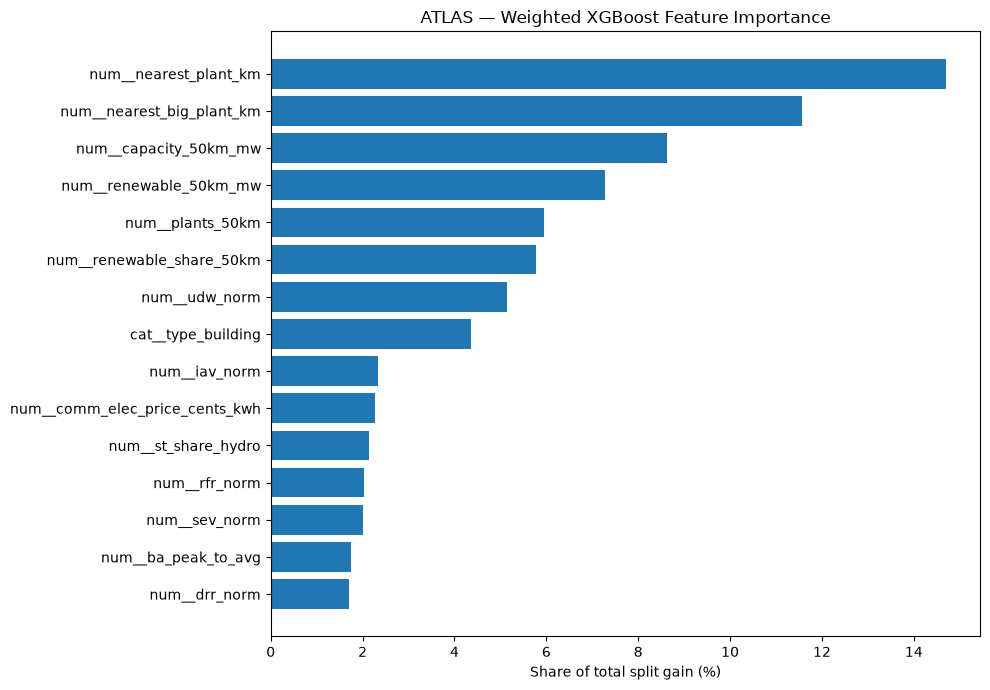

In [37]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Gain-based importance from the fitted weighted model.
booster = selected_classifier.get_booster()
gain_scores = booster.get_score(importance_type="total_gain")

importance_df = pd.DataFrame({
    "feature": selected_feature_names,
    "total_gain": [
        gain_scores.get(f"f{i}", 0.0)
        for i in range(len(selected_feature_names))
    ]
})

# Some XGBoost versions retain transformed feature names.
booster_names = booster.feature_names
if booster_names is not None:
    importance_df["total_gain"] = [
        gain_scores.get(name, gain_scores.get(f"f{i}", 0.0))
        for i, name in enumerate(booster_names)
    ]

def feature_source(name):
    if name.startswith("cat__"):
        return "IM3"
    if name.startswith("num__"):
        raw = name.removeprefix("num__")
        if raw.startswith("missingindicator_"):
            raw = raw.removeprefix("missingindicator_")
        if raw in WRI_FEATURES:
            return "WRI"
        if raw in EIA_FEATURES:
            return "EIA"
    return "Other"

importance_df["source"] = importance_df["feature"].map(feature_source)

total_gain = importance_df["total_gain"].sum()

importance_df["gain_share_pct"] = (
    100 * importance_df["total_gain"] / total_gain
    if total_gain > 0 else 0.0
)

importance_df = importance_df.sort_values(
    "total_gain", ascending=False
).reset_index(drop=True)

print("=== TOP 20 FEATURES BY TOTAL GAIN ===")
display(importance_df.head(20).round(3))

print("\n=== TOTAL GAIN BY DATA SOURCE ===")
source_importance = (
    importance_df.groupby("source")
    .agg(
        features=("feature", "count"),
        total_gain=("total_gain", "sum"),
        gain_share_pct=("gain_share_pct", "sum")
    )
    .sort_values("total_gain", ascending=False)
)

display(source_importance.round(3))

print("\n=== MISSINGNESS INDICATOR ===")
display(
    importance_df[
        importance_df["feature"].str.contains(
            "missingindicator", case=False
        )
    ].round(3)
)

# Plot the top 15 features.
top15 = importance_df.head(15).iloc[::-1]

plt.figure(figsize=(10, 7))
plt.barh(top15["feature"], top15["gain_share_pct"])
plt.xlabel("Share of total split gain (%)")
plt.title("ATLAS — Weighted XGBoost Feature Importance")
plt.tight_layout()
plt.show()


## 9. Explainable AI - SHAP and LIME

In [39]:

import importlib.metadata
import numpy as np
import pandas as pd

# Verify SHAP is available in the active kernel.
try:
    import shap
    print("SHAP version:", importlib.metadata.version("shap"))
except ImportError:
    raise ImportError(
        "SHAP is not installed in the active atlas kernel. "
        "Run %pip install shap in a separate notebook cell, "
        "then restart the kernel."
    )

# Use the selected weighted XGBoost development model.
xai_model = selected_weighted_model
xai_preprocessor = xai_model.named_steps["preprocess"]
xai_classifier = xai_model.named_steps["classifier"]

# Transform development data using the fitted preprocessor.
X_xai_array = xai_preprocessor.transform(X_dev)

if hasattr(X_xai_array, "toarray"):
    X_xai_array = X_xai_array.toarray()

xai_feature_names = xai_preprocessor.get_feature_names_out()

X_xai = pd.DataFrame(
    X_xai_array,
    columns=xai_feature_names,
    index=X_dev.index
)

assert X_xai.shape[1] == xai_classifier.n_features_in_
assert np.isfinite(X_xai.to_numpy()).all()

print("Development samples:", len(X_xai))
print("Transformed features:", X_xai.shape[1])
print("Model classes:", xai_classifier.classes_)
print("Missing transformed values:", X_xai.isna().sum().sum())
print("Held-out test used: 0")

display(X_xai.head(3))


/home/atthota/venvs/atlas/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version: 0.54.1
Development samples: 974
Transformed features: 46
Model classes: [0 1 2]
Missing transformed values: 0
Held-out test used: 0


,num__nearest_plant_km,num__plants_50km,num__capacity_50km_mw,num__renewable_50km_mw,num__renewable_share_50km,num__nearest_big_plant_km,num__ba_peak_mw,num__ba_avg_mw,num__ba_peak_to_avg,num__ba_demand_coverage,...,num__gtd_norm,num__rfr_norm,num__cfr_norm,num__drr_norm,num__cep_norm,num__udw_norm,num__usa_norm,num__missingindicator_gtd_norm,cat__type_building,cat__type_campus
1,24.278552,7.0,16.0,8.2,0.512500,51.450467,160560.0,96241.618265,1.668301,1.000000,...,0.260297,0.021336,0.0,0.501858,0.586987,0.054628,0.0,1.0,1.0,0.0
2,5.040431,33.0,322.2,309.3,0.959963,61.782910,21931.0,12535.759219,1.749475,0.999886,...,0.260297,0.202856,0.0,0.395143,0.369572,0.250813,0.0,1.0,0.0,1.0
3,11.285965,15.0,1583.3,462.0,0.291796,11.285965,118661.0,75772.987443,1.566007,1.000000,...,0.260297,0.064043,0.0,0.581810,0.586966,0.235160,0.0,1.0,0.0,1.0


# initialize multiclass SHAP

In [40]:

import numpy as np
import shap

# Reproducible subset of development data only.
X_shap_sample = X_xai.sample(
    n=min(200, len(X_xai)),
    random_state=SEED
)

# Explain the fitted XGBoost classifier directly.
# The inputs are already transformed by the fitted preprocessor.
shap_explainer = shap.TreeExplainer(
    xai_classifier,
    model_output="raw"
)

shap_values = shap_explainer(
    X_shap_sample,
    check_additivity=False
)

print("SHAP values shape:", shap_values.values.shape)
print("Sample count:", len(X_shap_sample))
print("Feature count:", X_shap_sample.shape[1])
print("Classes:", xai_classifier.classes_)

assert shap_values.values.shape == (
    len(X_shap_sample),
    X_shap_sample.shape[1],
    len(xai_classifier.classes_)
)

assert np.isfinite(shap_values.values).all()

print("\nMean absolute SHAP value by class:")

for class_idx, class_name in enumerate(CLASS_NAMES):
    mean_abs = np.abs(
        shap_values.values[:, :, class_idx]
    ).mean()

    print(f"{class_name}: {mean_abs:.4f}")

print("\nMulticlass SHAP initialization successful.")
print("Held-out test samples used: 0")


SHAP values shape: (200, 46, 3)
Sample count: 200
Feature count: 46
Classes: [0 1 2]

Mean absolute SHAP value by class:
Small: 0.0461
Medium: 0.0396
Large: 0.0388

Multiclass SHAP initialization successful.
Held-out test samples used: 0


# Verify SHAP additivity 

**Mathamatical consistancy** If this passes, we can trust the computed SHAP values faithfully decompose the models raw predictions

In [41]:

import numpy as np
import xgboost as xgb

# Get XGBoost's raw class scores, before softmax.
raw_scores = xai_classifier.get_booster().predict(
    xgb.DMatrix(
        X_shap_sample.to_numpy(),
        feature_names=list(X_shap_sample.columns)
    ),
    output_margin=True
)

# Reconstruct scores from SHAP explanations.
base_values = np.asarray(shap_values.base_values)

reconstructed_scores = (
    base_values + shap_values.values.sum(axis=1)
)

assert raw_scores.shape == reconstructed_scores.shape

absolute_errors = np.abs(
    raw_scores - reconstructed_scores
)

print("Raw score shape:", raw_scores.shape)
print("Maximum absolute error:", absolute_errors.max())
print("Mean absolute error:", absolute_errors.mean())

for class_idx, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name} max error: "
        f"{absolute_errors[:, class_idx].max():.8f}"
    )

assert np.allclose(
    raw_scores,
    reconstructed_scores,
    rtol=1e-4,
    atol=1e-4
), "SHAP additivity verification failed."

print("\nSHAP additivity verification passed.")
print("Held-out test samples used: 0")


Raw score shape: (200, 3)
Maximum absolute error: 1.9073486e-06
Mean absolute error: 2.4755175e-07
Small max error: 0.00000143
Medium max error: 0.00000131
Large max error: 0.00000191

SHAP additivity verification passed.
Held-out test samples used: 0


# Class sepcific SHAP importance

This helps us look at what features influence each class most strongly, and see wether WRI, EIA, or IM3 dominates 

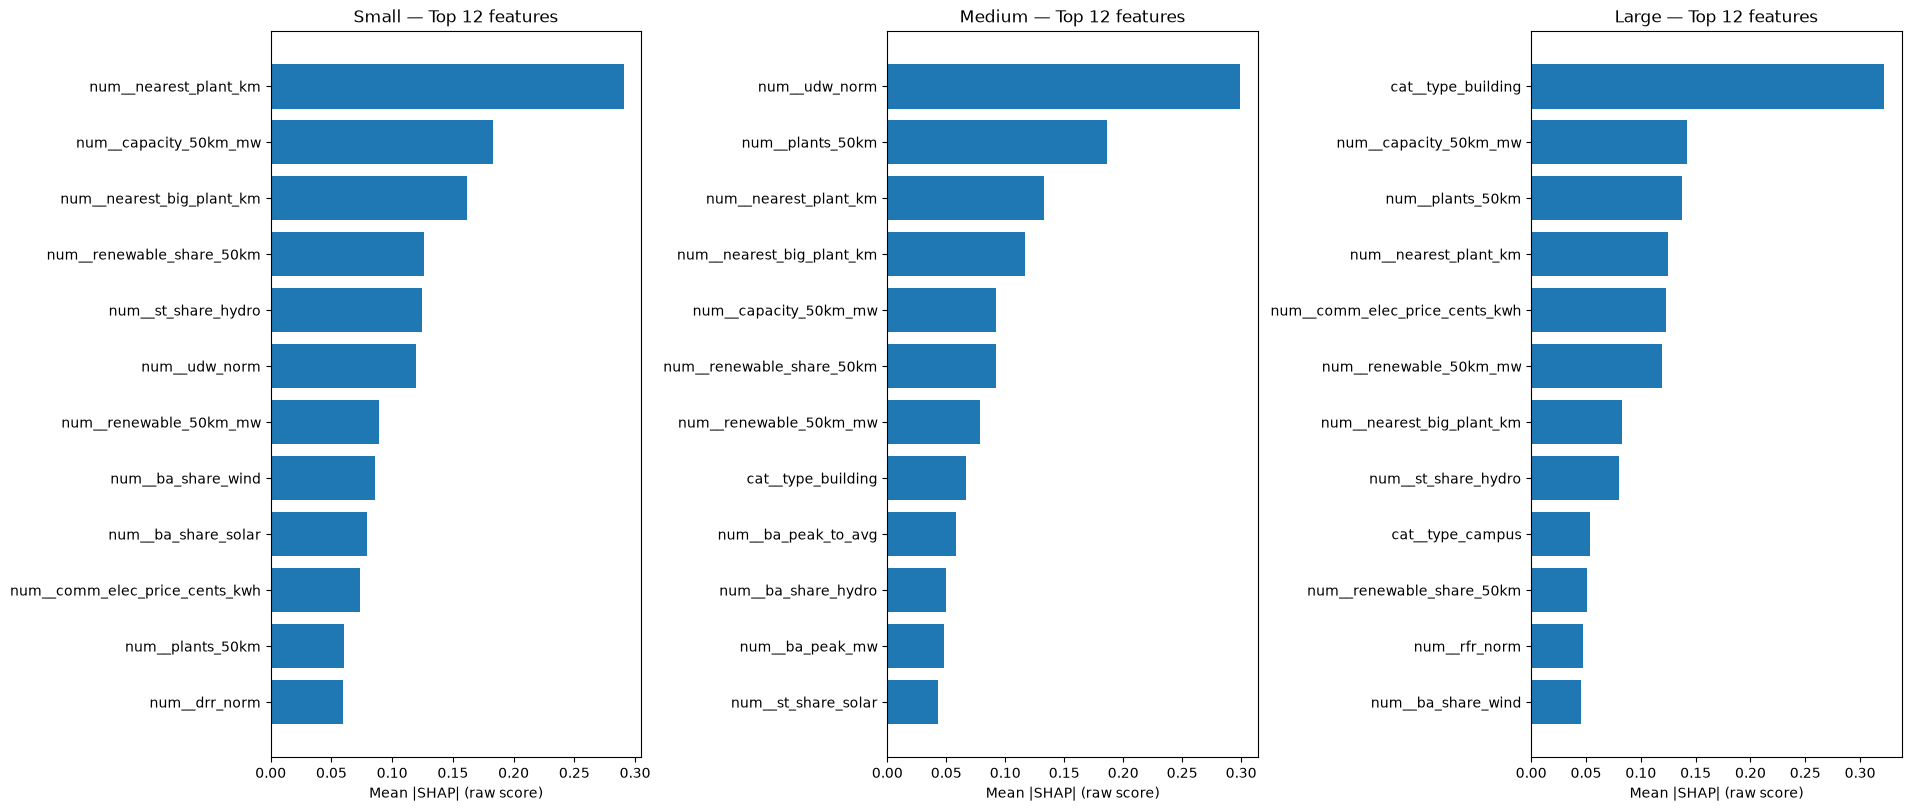

SHAP importance by dataset source:


,Small,Medium,Large
source,,,
EIA,1.7219,1.2176,1.1404
IM3,0.0008,0.0807,0.3758
WRI,0.3979,0.5232,0.2700



Top 10 features per class:

Small:


,Small,source
num__nearest_plant_km,0.2905,EIA
num__capacity_50km_mw,0.1829,EIA
num__nearest_big_plant_km,0.1615,EIA
num__renewable_share_50km,0.1264,EIA
num__st_share_hydro,0.1246,EIA
num__udw_norm,0.1192,WRI
num__renewable_50km_mw,0.0891,EIA
num__ba_share_wind,0.0855,EIA
num__ba_share_solar,0.0791,EIA
num__comm_elec_price_cents_kwh,0.0731,EIA



Medium:


,Medium,source
num__udw_norm,0.2992,WRI
num__plants_50km,0.1862,EIA
num__nearest_plant_km,0.1326,EIA
num__nearest_big_plant_km,0.1167,EIA
num__capacity_50km_mw,0.0925,EIA
num__renewable_share_50km,0.0924,EIA
num__renewable_50km_mw,0.0787,EIA
cat__type_building,0.0669,IM3
num__ba_peak_to_avg,0.0583,EIA
num__ba_share_hydro,0.0498,EIA



Large:


,Large,source
cat__type_building,0.3218,IM3
num__capacity_50km_mw,0.1417,EIA
num__plants_50km,0.1377,EIA
num__nearest_plant_km,0.1244,EIA
num__comm_elec_price_cents_kwh,0.1227,EIA
num__renewable_50km_mw,0.1191,EIA
num__nearest_big_plant_km,0.0825,EIA
num__st_share_hydro,0.0803,EIA
cat__type_campus,0.0540,IM3
num__renewable_share_50km,0.0505,EIA


In [42]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Mean absolute SHAP contribution for every feature and class.
mean_abs_shap = np.abs(shap_values.values).mean(axis=0)

shap_importance_df = pd.DataFrame(
    mean_abs_shap,
    index=X_shap_sample.columns,
    columns=CLASS_NAMES
)

# Assign features to their original dataset.
def shap_feature_source(feature):
    if feature.startswith("cat__"):
        return "IM3"
    if feature.replace("num__", "").replace(
        "missingindicator_", ""
    ) in WRI_ALL:
        return "WRI"
    return "EIA"

shap_importance_df["source"] = [
    shap_feature_source(f)
    for f in shap_importance_df.index
]

fig, axes = plt.subplots(
    1, 3, figsize=(19, 8),
    constrained_layout=True
)

for idx, class_name in enumerate(CLASS_NAMES):
    top_features = (
        shap_importance_df
        .sort_values(class_name, ascending=False)
        .head(12)
        .sort_values(class_name)
    )

    axes[idx].barh(
        top_features.index,
        top_features[class_name]
    )

    axes[idx].set_title(f"{class_name} — Top 12 features")
    axes[idx].set_xlabel("Mean |SHAP| (raw score)")

plt.show()

print("SHAP importance by dataset source:")

source_shap_importance = (
    shap_importance_df
    .groupby("source")[CLASS_NAMES]
    .sum()
)

display(source_shap_importance.round(4))

print("\nTop 10 features per class:")

for class_name in CLASS_NAMES:
    print(f"\n{class_name}:")
    display(
        shap_importance_df[
            [class_name, "source"]
        ]
        .sort_values(class_name, ascending=False)
        .head(10)
        .round(4)
    )


# SHAP beeswarm plots 

This shows feature values, attribution directions, and variability across facilities


SHAP beeswarm — Small


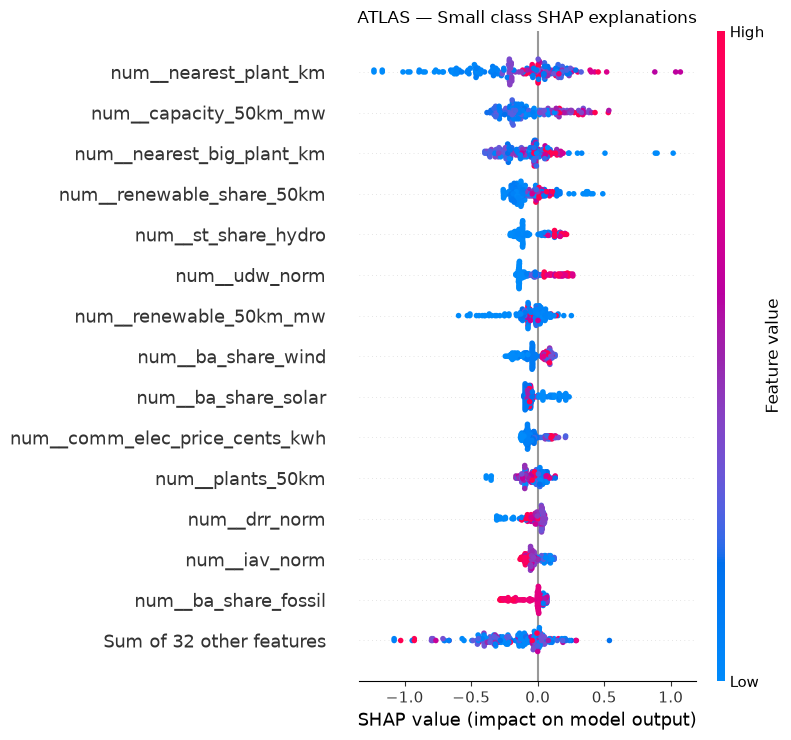


SHAP beeswarm — Medium


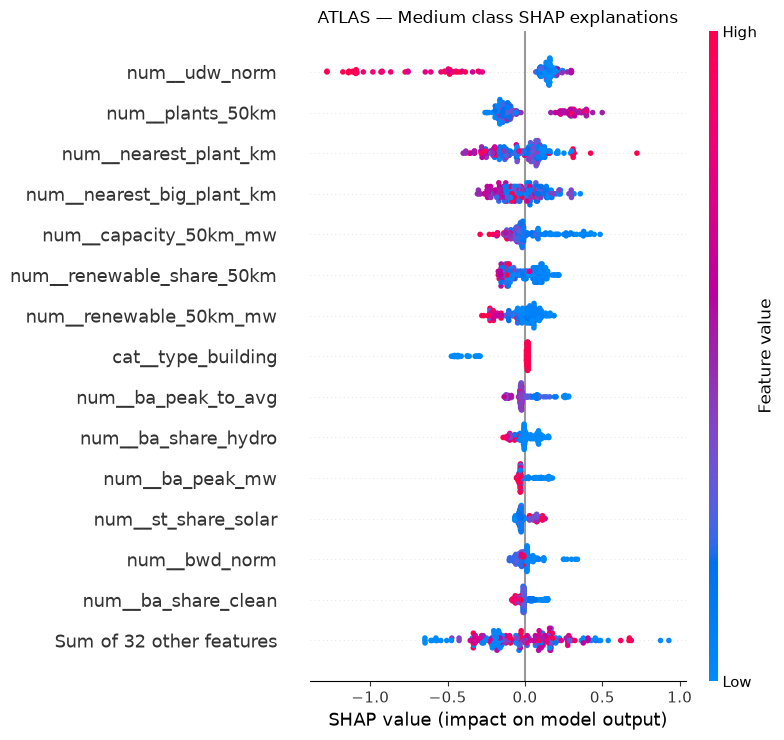


SHAP beeswarm — Large


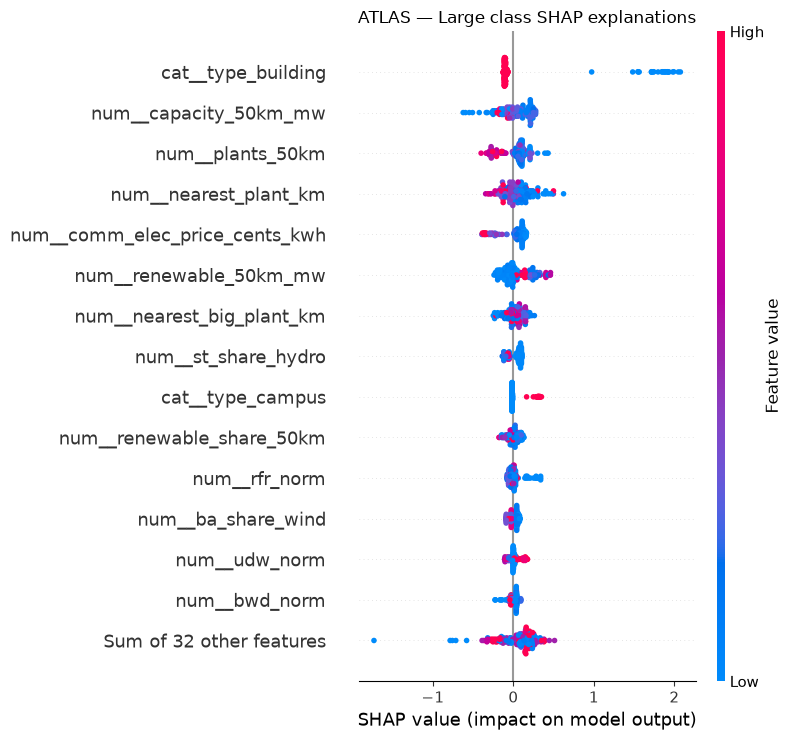

In [43]:

import shap
import matplotlib.pyplot as plt

for class_idx, class_name in enumerate(CLASS_NAMES):

    print(f"\nSHAP beeswarm — {class_name}")

    # Select only this class's SHAP explanations.
    class_explanation = shap_values[:, :, class_idx]

    shap.plots.beeswarm(
        class_explanation,
        max_display=15,
        show=False
    )

    plt.title(
        f"ATLAS — {class_name} class SHAP explanations"
    )
    plt.tight_layout()
    plt.show()


# Facilitiy type shortcut audit

This looks at the relationship between IM3 facility type and the three size classes. This helps us look at if we need type abalation based eda, rerunning the weighted XGBoost without type, etc

In [44]:

import pandas as pd
import numpy as np

# Development data only — held-out test remains untouched.
type_audit = geo_df[
    ["type", "size_class", "state"]
].copy()

print("Facility type counts:")
display(type_audit["type"].value_counts(dropna=False))

print("\nFacility type vs size class (counts):")
type_class_counts = pd.crosstab(
    type_audit["type"],
    type_audit["size_class"]
)
type_class_counts = type_class_counts.reindex(
    columns=[0, 1, 2],
    fill_value=0
)
type_class_counts.columns = CLASS_NAMES
display(type_class_counts)

print("\nFacility type vs size class (row percentages):")
type_class_pct = type_class_counts.div(
    type_class_counts.sum(axis=1),
    axis=0
) * 100
display(type_class_pct.round(2))

print("\nLarge-class rate by facility type:")
display(
    type_class_pct["Large"]
    .sort_values(ascending=False)
    .round(2)
)

print("\nStates represented by each facility type:")
display(
    type_audit.groupby("type")["state"]
    .nunique()
)

print("\nHeld-out test samples used: 0")


Facility type counts:


type
building    879
campus       95
Name: count, dtype: int64


Facility type vs size class (counts):


,Small,Medium,Large
type,,,
building,92,279,508
campus,2,1,92



Facility type vs size class (row percentages):


...


Large-class rate by facility type:


type
campus      96.84
building    57.79
Name: Large, dtype: float64


States represented by each facility type:


type
building    39
campus      21
Name: state, dtype: int64


Held-out test samples used: 0


# Target leakage check

In [45]:
# Prevent direct target leakage.
forbidden_features = {"sqft", "size_class"}

for group_name, features in FEATURE_GROUPS.items():
    leaked = forbidden_features.intersection(features)

    assert not leaked, (
        f"Target leakage in {group_name}: {leaked}"
    )

print("Direct target-leakage feature audit passed.")

Direct target-leakage feature audit passed.


# Geographic CV without facility type

In [46]:

from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
import pandas as pd
import numpy as np

no_type_features = FEATURE_GROUPS["EIA_WRI"]

no_type_fold_results = []

for fold, (tr_idx, va_idx) in enumerate(geo_splits, start=1):

    X_tr = geo_df.iloc[tr_idx][no_type_features]
    X_va = geo_df.iloc[va_idx][no_type_features]

    y_tr = geo_df.iloc[tr_idx]["size_class"]
    y_va = geo_df.iloc[va_idx]["size_class"]

    weights = compute_sample_weight(
        class_weight="balanced",
        y=y_tr
    )

    model = clone(
        trained["IM3_EIA_WRI__XGBoost"]
    )

    # Rebuild preprocessing without IM3 type.
    model.set_params(
        preprocess=make_preprocessor(no_type_features)
    )

    model.fit(
        X_tr,
        y_tr,
        classifier__sample_weight=weights
    )

    metrics, _ = evaluate(model, X_va, y_va)

    no_type_fold_results.append({
        "fold": fold,
        "macro_f1": metrics["macro_f1"],
        "balanced_accuracy": metrics["balanced_accuracy"],
        "small_recall": metrics["small_recall"],
        "medium_recall": metrics["medium_recall"],
        "large_recall": metrics["large_recall"]
    })

no_type_cv_df = pd.DataFrame(no_type_fold_results)

print("Geographic CV without facility type:")
display(no_type_cv_df.round(4))

print("\nMean geographic CV performance:")
display(
    no_type_cv_df.drop(columns="fold")
    .agg(["mean", "std"])
    .round(4)
)

print("\nPreviously measured weighted XGBoost:")
print("With IM3 type: macro-F1 = 0.3884")
print("Held-out test samples used: 0")


Geographic CV without facility type:


,fold,macro_f1,balanced_accuracy,small_recall,medium_recall,large_recall
0,1,0.2872,0.3543,0.1111,0.6949,0.2568
1,2,0.3628,0.3562,0.1053,0.3774,0.5859
2,3,0.3804,0.4199,0.2778,0.7458,0.2361
3,4,0.2739,0.3002,0.2632,0.2778,0.3597
4,5,0.4302,0.5275,0.7000,0.5273,0.3551



Mean geographic CV performance:


,macro_f1,balanced_accuracy,small_recall,medium_recall,large_recall
mean,0.3469,0.3916,0.2915,0.5246,0.3587
std,0.0656,0.0870,0.2424,0.2003,0.1388



Previously measured weighted XGBoost:
With IM3 type: macro-F1 = 0.3884
Held-out test samples used: 0


# Paired facility type abalation

In [47]:

import pandas as pd
import numpy as np

# Existing weighted XGBoost geographic CV results.
with_type = weighted_xgb_geo_df.copy()

# Align with the newly completed no-type experiment.
without_type = no_type_cv_df.copy()

paired_type = with_type.merge(
    without_type,
    on="fold",
    suffixes=("_with_type", "_without_type"),
    validate="one_to_one"
)

paired_type["macro_f1_gain"] = (
    paired_type["macro_f1_with_type"]
    - paired_type["macro_f1_without_type"]
)

paired_type["balanced_accuracy_gain"] = (
    paired_type["balanced_accuracy_with_type"]
    - paired_type["balanced_accuracy_without_type"]
)

display(
    paired_type[
        [
            "fold",
            "macro_f1_with_type",
            "macro_f1_without_type",
            "macro_f1_gain",
            "balanced_accuracy_gain"
        ]
    ].round(4)
)

print(
    "Folds improved with type:",
    (paired_type["macro_f1_gain"] > 0).sum(),
    "/",
    len(paired_type)
)

print(
    "Mean macro-F1 gain:",
    round(paired_type["macro_f1_gain"].mean(), 4)
)

print("Held-out test samples used: 0")


,fold,macro_f1_with_type,macro_f1_without_type,macro_f1_gain,balanced_accuracy_gain
0,1,0.3701,0.2872,0.0829,0.0680
1,2,0.3832,0.3628,0.0204,0.0231
2,3,0.4372,0.3804,0.0569,0.0478
3,4,0.3444,0.2739,0.0705,0.0941
4,5,0.4072,0.4302,-0.0230,0.0084


Folds improved with type: 4 / 5
Mean macro-F1 gain: 0.0415
Held-out test samples used: 0


## 10. Preparing LIME

In [48]:

import importlib.metadata
import numpy as np
from sklearn.model_selection import train_test_split

try:
    from lime.lime_tabular import LimeTabularExplainer
    print("LIME version:", importlib.metadata.version("lime"))
except ImportError:
    print("LIME is not installed.")
    print("Run %pip install lime in a separate cell.")
else:
    lime_background = X_xai.sample(
        n=min(500, len(X_xai)),
        random_state=SEED
    )

    lime_explainer = LimeTabularExplainer(
        training_data=lime_background.to_numpy(),
        feature_names=list(X_xai.columns),
        class_names=CLASS_NAMES,
        mode="classification",
        discretize_continuous=True,
        random_state=SEED
    )

    print("LIME background shape:", lime_background.shape)
    print("Model classes:", xai_classifier.classes_)
    print("Held-out test samples used: 0")
    print("LIME initialization successful.")


LIME version: 0.2.0.1
LIME background shape: (500, 46)
Model classes: [0 1 2]
Held-out test samples used: 0
LIME initialization successful.


# Select facilities for local explanations 

This helps identify 3 casses from the development dataset

**Correctly predicted large:** Understand what supports a succesful large classification
**Misclassified small:** Investigate why the model struggles with smaller facilities
**Correctly predicted medium:** Exmine weather the strong `udw_norm` SHAP pattern appears locally

In [49]:

import numpy as np
import pandas as pd

# Predictions from the selected development-fitted model.
lime_probabilities = xai_classifier.predict_proba(X_xai)
lime_predictions = xai_classifier.classes_[
    lime_probabilities.argmax(axis=1)
]

lime_cases = pd.DataFrame({
    "facility_id": geo_df.loc[X_xai.index, "id"].values,
    "true_class": geo_df.loc[X_xai.index, "size_class"].values,
    "predicted_class": lime_predictions,
    "confidence": lime_probabilities.max(axis=1)
}, index=X_xai.index)

lime_cases["correct"] = (
    lime_cases["true_class"] == lime_cases["predicted_class"]
)

# Select cases deterministically.
case_filters = {
    "correct_large": (
        (lime_cases["true_class"] == 2)
        & lime_cases["correct"]
    ),
    "misclassified_small": (
        (lime_cases["true_class"] == 0)
        & (~lime_cases["correct"])
    ),
    "correct_medium": (
        (lime_cases["true_class"] == 1)
        & lime_cases["correct"]
    )
}

selected_lime_cases = {}

for case_name, mask in case_filters.items():
    candidates = lime_cases.loc[mask].sort_values(
        ["confidence", "facility_id"],
        ascending=[False, True]
    )

    if candidates.empty:
        print(f"No available case: {case_name}")
        continue

    selected_idx = candidates.index[0]
    selected_lime_cases[case_name] = selected_idx

    print(f"\n{case_name}")
    display(lime_cases.loc[[selected_idx]])

print("\nSelected cases:", len(selected_lime_cases))
print("Held-out test samples used: 0")



correct_large


,facility_id,true_class,predicted_class,confidence,correct
535,675108684,2,2,0.98513,True



misclassified_small


,facility_id,true_class,predicted_class,confidence,correct
817,1015995259,0,2,0.634441,False



correct_medium


,facility_id,true_class,predicted_class,confidence,correct
771,965755845,1,1,0.93217,True



Selected cases: 3
Held-out test samples used: 0


# LIME explination of the misclassified small facility

Facility ID: 1015995259
True class: Small
Predicted class: Large

XGBoost probabilities:


Small     0.2838
Medium    0.0817
Large     0.6344
dtype: float32


LIME local approximation R²:
0.2914

Top local contributions toward/against Large:


,feature_condition,lime_weight
0,num__cfr_norm > 0.00,-0.1000
1,cat__type_campus <= 0.00,-0.0538
2,num__nearest_plant_km <= 2.36,0.0517
3,3230.30 < num__capacity_50km_mw <= 4474.17,0.0387
4,num__comm_elec_price_cents_kwh <= 9.95,0.0329
5,36.00 < num__plants_50km <= 69.00,0.0244
6,0.08 < num__ba_share_coal <= 0.17,0.0232
7,0.12 < num__rfr_norm <= 0.23,-0.0174
8,num__nearest_big_plant_km > 22.49,-0.0140
9,num__ba_share_renewable <= 0.08,0.0133


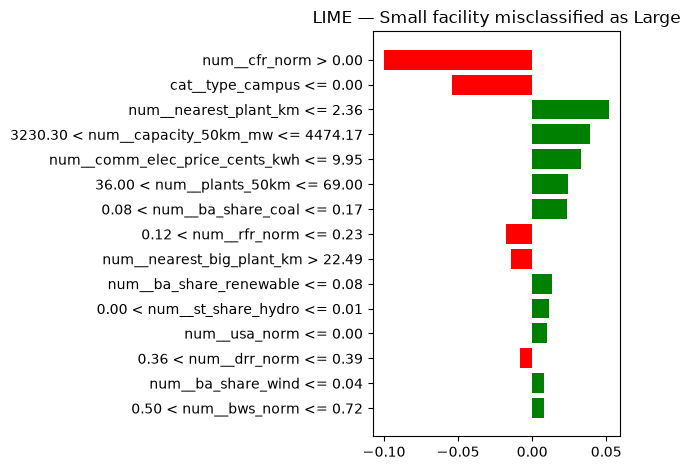

In [50]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

case_idx = selected_lime_cases["misclassified_small"]

# Position of the selected facility in the transformed matrix.
case_position = X_xai.index.get_loc(case_idx)
case_values = X_xai.iloc[case_position].to_numpy()

# Explain the actual model's probability predictions.
lime_exp_small = lime_explainer.explain_instance(
    data_row=case_values,
    predict_fn=xai_classifier.predict_proba,
    labels=(0, 1, 2),
    num_features=15,
    num_samples=5000
)

predicted_class = int(
    lime_cases.loc[case_idx, "predicted_class"]
)

print("Facility ID:", lime_cases.loc[case_idx, "facility_id"])
print("True class:", CLASS_NAMES[int(lime_cases.loc[case_idx, "true_class"])])
print("Predicted class:", CLASS_NAMES[predicted_class])

print("\nXGBoost probabilities:")
display(
    pd.Series(
        xai_classifier.predict_proba(
            X_xai.iloc[[case_position]]
        )[0],
        index=CLASS_NAMES
    ).round(4)
)

print("\nLIME local approximation R²:")
print(round(lime_exp_small.score, 4))

print("\nTop local contributions toward/against Large:")

lime_small_weights = pd.DataFrame(
    lime_exp_small.as_list(label=predicted_class),
    columns=["feature_condition", "lime_weight"]
)

display(lime_small_weights.round(4))

fig = lime_exp_small.as_pyplot_figure(
    label=predicted_class
)

plt.title(
    "LIME — Small facility misclassified as Large"
)
plt.tight_layout()
plt.show()


# LIME neighborhood sensitivity

In [51]:

import numpy as np
import pandas as pd

lime_sensitivity_results = []

for kernel_width in [1.0, 3.0, 6.0]:

    local_explainer = LimeTabularExplainer(
        training_data=lime_background.to_numpy(),
        feature_names=list(X_xai.columns),
        class_names=CLASS_NAMES,
        mode="classification",
        discretize_continuous=True,
        kernel_width=kernel_width,
        random_state=SEED
    )

    explanation = local_explainer.explain_instance(
        data_row=case_values,
        predict_fn=xai_classifier.predict_proba,
        labels=(predicted_class,),
        num_features=15,
        num_samples=5000
    )

    lime_sensitivity_results.append({
        "kernel_width": kernel_width,
        "local_r2": explanation.score,
        "intercept": explanation.intercept[predicted_class],
        "top_feature": explanation.as_list(
            label=predicted_class
        )[0][0]
    })

lime_sensitivity_df = pd.DataFrame(
    lime_sensitivity_results
)

display(lime_sensitivity_df.round(4))

print("\nOriginal LIME R²:", round(lime_exp_small.score, 4))
print("Held-out test samples used: 0")


,kernel_width,local_r2,intercept,top_feature
0,1.0,0.2853,0.7069,num__cfr_norm > 0.00
1,3.0,0.2956,0.8095,num__cfr_norm > 0.00
2,6.0,0.2907,0.8024,num__cfr_norm > 0.00



Original LIME R²: 0.2914
Held-out test samples used: 0


# LIME fidelity across 3 facility types 

In [52]:

import pandas as pd

lime_fidelity_results = []

for case_name, idx in selected_lime_cases.items():

    row = X_xai.loc[idx].to_numpy()
    predicted = int(lime_cases.loc[idx, "predicted_class"])

    exp = lime_explainer.explain_instance(
        data_row=row,
        predict_fn=xai_classifier.predict_proba,
        labels=(predicted,),
        num_features=15,
        num_samples=5000
    )

    lime_fidelity_results.append({
        "case": case_name,
        "true_class": CLASS_NAMES[
            int(lime_cases.loc[idx, "true_class"])
        ],
        "predicted_class": CLASS_NAMES[predicted],
        "confidence": lime_cases.loc[idx, "confidence"],
        "local_r2": exp.score,
        "top_feature": exp.as_list(
            label=predicted
        )[0][0]
    })

lime_fidelity_df = pd.DataFrame(lime_fidelity_results)

display(lime_fidelity_df.round(4))

print("\nMean local R²:", round(lime_fidelity_df["local_r2"].mean(), 4))
print("Held-out test samples used: 0")


,case,true_class,predicted_class,confidence,local_r2,top_feature
0,correct_large,Large,Large,0.9851,0.2866,num__cfr_norm <= 0.00
1,misclassified_small,Small,Large,0.6344,0.2834,num__cfr_norm > 0.00
2,correct_medium,Medium,Medium,0.9322,0.3371,num__cfr_norm <= 0.00



Mean local R²: 0.3024
Held-out test samples used: 0


# Save SHAP and LIME results 

In [53]:

from pathlib import Path
import json
import pandas as pd
import numpy as np

xai_output_dir = Path(
    "outputs/tabular_baselines/atlas_wri_v2/explainability"
)
xai_output_dir.mkdir(parents=True, exist_ok=True)

# Save feature-level and source-level SHAP importance.
shap_importance_df.to_csv(
    xai_output_dir / "shap_class_importance.csv",
    index_label="feature"
)

source_shap_importance.to_csv(
    xai_output_dir / "shap_source_importance.csv"
)

# Save LIME fidelity diagnostics.
lime_fidelity_df.to_csv(
    xai_output_dir / "lime_fidelity.csv",
    index=False
)

lime_sensitivity_df.to_csv(
    xai_output_dir / "lime_kernel_sensitivity.csv",
    index=False
)

# Save paired facility-type ablation.
paired_type.to_csv(
    xai_output_dir / "facility_type_ablation.csv",
    index=False
)

metadata = {
    "model": "Weighted XGBoost",
    "feature_group": "IM3_EIA_WRI",
    "development_samples": int(len(X_dev)),
    "shap_samples": int(len(X_shap_sample)),
    "transformed_features": int(X_xai.shape[1]),
    "shap_output": "raw_class_scores",
    "shap_additivity_max_error": float(
        absolute_errors.max()
    ),
    "lime_mean_local_r2": float(
        lime_fidelity_df["local_r2"].mean()
    ),
    "facility_type_macro_f1_gain": float(
        paired_type["macro_f1_gain"].mean()
    ),
    "held_out_test_evaluated": False,
    "notes": [
        "SHAP explanations computed on development data.",
        "SHAP additivity verified against XGBoost raw scores.",
        "LIME local surrogate fidelity was low.",
        "Facility type improves geographic CV performance but remains a potential target proxy.",
        "SHAP attributions are not causal explanations."
    ]
}

with open(
    xai_output_dir / "explainability_metadata.json",
    "w"
) as f:
    json.dump(metadata, f, indent=2)

print("Saved explainability artifacts:")
for path in sorted(xai_output_dir.iterdir()):
    print(" -", path.name, f"({path.stat().st_size:,} bytes)")

print("\nHeld-out test samples used: 0")


Saved explainability artifacts:
 - explainability_metadata.json (700 bytes)
 - facility_type_ablation.csv (1,465 bytes)
 - lime_fidelity.csv (305 bytes)
 - lime_kernel_sensitivity.csv (234 bytes)
 - shap_class_importance.csv (2,704 bytes)
 - shap_source_importance.csv (134 bytes)

Held-out test samples used: 0


## 11. Final model and leakage audit

In [54]:

import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.utils.validation import check_is_fitted

# Selected model from our completed development experiments.
final_model = selected_weighted_model
final_features = list(FEATURE_GROUPS["IM3_EIA_WRI"])

# 1. Confirm model structure and fitted state.
assert isinstance(final_model, Pipeline)
assert list(final_model.named_steps) == [
    "preprocess", "classifier"
]

check_is_fitted(final_model.named_steps["preprocess"])
check_is_fitted(final_model.named_steps["classifier"])

classifier = final_model.named_steps["classifier"]
preprocessor = final_model.named_steps["preprocess"]

assert classifier.__class__.__name__ == "XGBClassifier"
assert list(classifier.classes_) == [0, 1, 2]

# 2. Verify direct target leakage is excluded.
forbidden = {
    "sqft", "size_class",
    "id", "name", "operator",
    "lat", "lon", "state", "state_abb", "county"
}

assert not forbidden.intersection(final_features), (
    "Forbidden features detected: "
    f"{forbidden.intersection(final_features)}"
)

# 3. Confirm feature and preprocessing alignment.
assert list(preprocessor.feature_names_in_) == final_features

transformed_features = list(
    preprocessor.get_feature_names_out()
)

assert len(transformed_features) == classifier.n_features_in_

# 4. Verify development and held-out IDs are disjoint.
dev_ids = set(df.iloc[train_val_idx]["id"])
test_ids = set(df.iloc[test_idx]["id"])

assert dev_ids.isdisjoint(test_ids)
assert len(dev_ids) == len(train_val_idx)
assert len(test_ids) == len(test_idx)

# 5. Confirm the fitted model's expected input schema.
assert list(X_dev.columns) == final_features
assert len(X_dev) == len(train_val_idx)

print("FINAL MODEL AUDIT")
print("-" * 45)
print("Classifier:", classifier.__class__.__name__)
print("Raw features:", len(final_features))
print("Transformed features:", len(transformed_features))
print("Classes:", classifier.classes_)
print("Development samples:", len(dev_ids))
print("Held-out samples:", len(test_ids))
print("Direct leakage features:", sorted(forbidden.intersection(final_features)))
print("Development/test ID overlap:", len(dev_ids.intersection(test_ids)))

print("\nSelected XGBoost hyperparameters:")
for parameter in [
    "n_estimators",
    "max_depth",
    "learning_rate",
    "subsample",
    "colsample_bytree",
    "reg_lambda",
    "min_child_weight"
]:
    print(f"  {parameter}: {classifier.get_params().get(parameter)}")

print("\nFeature groups:")
print("IM3:", len(IM3_FEATURES))
print("EIA:", len(EIA_FEATURES))
print("WRI:", len(WRI_FEATURES))

print("\nStructural audit passed.")
print("No predictions or held-out test evaluation performed.")


FINAL MODEL AUDIT
---------------------------------------------
Classifier: XGBClassifier
Raw features: 44
Transformed features: 46
Classes: [0 1 2]
Development samples: 974
Held-out samples: 173
Direct leakage features: []
Development/test ID overlap: 0

Selected XGBoost hyperparameters:
  n_estimators: 300
  max_depth: 3
  learning_rate: 0.05
  subsample: 0.8
  colsample_bytree: 0.8
  reg_lambda: 5.0
  min_child_weight: None

Feature groups:
IM3: 1
EIA: 32
WRI: 11

Structural audit passed.
No predictions or held-out test evaluation performed.


# Feature provanance and target proxy audit

In [55]:

import numpy as np
import pandas as pd

audit_df = df.iloc[train_val_idx][
    ["id", "type", "sqft", "size_class", "state"]
].copy()

print("Missing values:")
display(
    audit_df[["type", "sqft", "size_class"]]
    .isna()
    .sum()
)

print("\nFootprint area by facility type:")
display(
    audit_df.groupby("type")["sqft"]
    .agg(["count", "min", "median", "mean", "max"])
    .round(1)
)

print("\nFootprint area by size class:")
display(
    audit_df.groupby("size_class")["sqft"]
    .agg(["count", "min", "median", "max"])
    .round(1)
)

print("\nFootprint area by type and size class:")
display(
    audit_df.groupby(["type", "size_class"])["sqft"]
    .agg(["count", "min", "median", "max"])
    .round(1)
)

print("\nSize-class boundaries:")
for class_id, class_name in enumerate(CLASS_NAMES):
    values = audit_df.loc[
        audit_df["size_class"] == class_id, "sqft"
    ]
    print(
        f"{class_name}: "
        f"min={values.min():,.1f}, "
        f"max={values.max():,.1f}"
    )

print("\nHeld-out test samples used: 0")


Missing values:


type          0
sqft          0
size_class    0
dtype: int64


Footprint area by facility type:


,count,min,median,mean,max
type,,,,,
building,879,204.0,121002.0,150336.1,1338261.0
campus,95,9139.0,1299936.0,3467451.0,26597517.0



Footprint area by size class:


,count,min,median,max
size_class,,,,
0,94,204.0,12367.0,19807.0
1,280,20213.0,55033.5,99760.0
2,600,100537.0,211938.0,26597517.0



Footprint area by type and size class:


count       min     median         max
type     size_class                                        
building 0              92     204.0    12367.0     19807.0
         1             279   20213.0    55066.0     99760.0
         2             508  100537.0   180721.0   1338261.0
campus   0               2    9139.0    11368.0     13597.0
         1               1   49212.0    49212.0     49212.0
         2              92  143246.0  1488203.5  26597517.0


Size-class boundaries:
Small: min=204.0, max=19,807.0
Medium: min=20,213.0, max=99,760.0
Large: min=100,537.0, max=26,597,517.0

Held-out test samples used: 0


# Feature redundancy check

In [56]:

import numpy as np
import pandas as pd

numeric_features = [
    c for c in final_features
    if pd.api.types.is_numeric_dtype(X_dev[c])
]

X_numeric = X_dev[numeric_features].copy()

# Identify constant or nearly constant features.
feature_variability = pd.DataFrame({
    "feature": numeric_features,
    "unique_values": [
        X_numeric[c].nunique(dropna=True)
        for c in numeric_features
    ],
    "missing_pct": [
        X_numeric[c].isna().mean() * 100
        for c in numeric_features
    ]
})

print("Constant or near-constant features:")
display(
    feature_variability[
        feature_variability["unique_values"] <= 2
    ].sort_values("unique_values")
)

print("\nFeatures with over 50% missing values:")
display(
    feature_variability[
        feature_variability["missing_pct"] > 50
    ].sort_values("missing_pct", ascending=False)
)

# Pairwise correlations using observed values.
correlation = X_numeric.corr(method="spearman").abs()

upper = correlation.where(
    np.triu(
        np.ones(correlation.shape),
        k=1
    ).astype(bool)
)

high_corr = (
    upper.stack()
    .reset_index()
)

high_corr.columns = [
    "feature_1",
    "feature_2",
    "abs_spearman"
]

high_corr = high_corr[
    high_corr["abs_spearman"] >= 0.95
].sort_values(
    "abs_spearman",
    ascending=False
)

print("\nHighly correlated feature pairs (|Spearman| >= 0.95):")
display(high_corr)

print("\nTotal highly correlated pairs:", len(high_corr))
print("Held-out test samples used: 0")


Constant or near-constant features:


,feature,unique_values,missing_pct
42,usa_norm,2,0.0



Features with over 50% missing values:


,feature,unique_values,missing_pct
36,gtd_norm,12,75.667351



Highly correlated feature pairs (|Spearman| >= 0.95):


,feature_1,feature_2,abs_spearman
265,ba_peak_mw,ba_avg_mw,0.999528
1234,st_share_fossil,st_share_clean,0.998606
320,ba_avg_mw,ba_total_gen_mwh,0.996652
277,ba_peak_mw,ba_total_gen_mwh,0.996194
1409,bws_norm,bwd_norm,0.985766
706,ba_share_fossil,ba_share_clean,0.984485



Total highly correlated pairs: 6
Held-out test samples used: 0


# Save Weighted XGBoost

In [57]:

from pathlib import Path
import json
import joblib
import sklearn
import xgboost

model_dir = Path(
    "outputs/tabular_baselines/atlas_wri_v2/selected_model"
)

model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "weighted_xgboost_pipeline.joblib"
metadata_path = model_dir / "model_metadata.json"

# Protect existing artifacts.
assert not model_path.exists(), (
    f"Model artifact already exists: {model_path}"
)
assert not metadata_path.exists(), (
    f"Metadata already exists: {metadata_path}"
)

metadata = {
    "model": "Weighted XGBoost",
    "selection_status": "provisional_geographic_cv_winner",
    "feature_group": "IM3_EIA_WRI",
    "raw_features": final_features,
    "transformed_features": transformed_features,
    "classes": CLASS_NAMES,
    "development_samples": len(X_dev),
    "held_out_samples": len(test_idx),
    "geographic_cv_macro_f1": 0.3884,
    "geographic_cv_balanced_accuracy": 0.4399,
    "class_weighting": "balanced_per_fold_for_cv_and_balanced_on_development_for_final_fit",
    "hyperparameters": {
        "n_estimators": 300,
        "max_depth": 3,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 5.0
    },
    "versions": {
        "sklearn": sklearn.__version__,
        "xgboost": xgboost.__version__
    },
    "held_out_test_evaluated": False,
    "limitations": [
        "Facility type provenance remains unverified.",
        "Size labels are derived from footprint area.",
        "Geographic CV performance remains modest.",
        "WRI incremental geographic CV benefit is small.",
        "Correlated features may affect SHAP importance stability.",
        "gtd_norm has substantial missingness."
    ]
}

joblib.dump(final_model, model_path)

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

print("Selected model saved:")
print(model_path)
print(metadata_path)

print("\nModel size:")
print(f"{model_path.stat().st_size / 1024 / 1024:.2f} MiB")

print("\nHeld-out test samples used: 0")


Selected model saved:
outputs/tabular_baselines/atlas_wri_v2/selected_model/weighted_xgboost_pipeline.joblib
outputs/tabular_baselines/atlas_wri_v2/selected_model/model_metadata.json

Model size:
0.98 MiB

Held-out test samples used: 0


# Verify model serialization

In [58]:

import joblib
import json
import numpy as np

# Reload the saved pipeline and metadata.
reloaded_model = joblib.load(model_path)

with open(metadata_path, "r") as f:
    saved_metadata = json.load(f)

# Development-only verification sample.
X_verify = X_dev.sample(
    n=20,
    random_state=SEED
)

original_probs = final_model.predict_proba(X_verify)
reloaded_probs = reloaded_model.predict_proba(X_verify)

original_preds = final_model.predict(X_verify)
reloaded_preds = reloaded_model.predict(X_verify)

# Verify serialization preserved model behavior.
assert np.array_equal(original_preds, reloaded_preds)

assert np.allclose(
    original_probs,
    reloaded_probs,
    rtol=1e-7,
    atol=1e-7
)

# Verify feature schema and class ordering.
assert saved_metadata["raw_features"] == list(X_verify.columns)
assert list(reloaded_model.classes_) == [0, 1, 2]
assert saved_metadata["held_out_test_evaluated"] is False

print("SERIALIZATION VALIDATION")
print("-" * 40)
print("Predictions identical:", np.array_equal(
    original_preds, reloaded_preds
))
print("Maximum probability difference:",
      np.max(np.abs(original_probs - reloaded_probs)))
print("Feature schema matches:", True)
print("Class order:", reloaded_model.classes_)
print("Verification facilities:", len(X_verify))
print("Held-out test samples used: 0")

print("\nSaved pipeline verification passed.")


SERIALIZATION VALIDATION
----------------------------------------
Predictions identical: True
Maximum probability difference: 0.0
Feature schema matches: True
Class order: [0 1 2]
Verification facilities: 20
Held-out test samples used: 0

Saved pipeline verification passed.


# geographic audit

In [59]:

import pandas as pd
import numpy as np

geo_columns = [
    "id", "name", "operator", "state",
    "state_abb", "county", "lat", "lon",
    "type", "sqft", "size_class"
]

available = [c for c in geo_columns if c in df.columns]
missing = [c for c in geo_columns if c not in df.columns]

print("GEOGRAPHIC AUDIT PREPARATION")
print("-" * 45)
print("Available columns:", available)
print("Missing columns:", missing)

print("\nCoordinate completeness:")
if {"lat", "lon"}.issubset(df.columns):
    print("Missing latitude:", df["lat"].isna().sum())
    print("Missing longitude:", df["lon"].isna().sum())

    valid_coords = (
        df["lat"].between(-90, 90)
        & df["lon"].between(-180, 180)
    )
    print("Invalid coordinate rows:", (~valid_coords).sum())

    coord_counts = (
        df.groupby(["lat", "lon"], dropna=False)
        .size()
        .sort_values(ascending=False)
    )

    print("Repeated coordinate groups:",
          (coord_counts > 1).sum())
    print("Facilities in repeated groups:",
          coord_counts[coord_counts > 1].sum())

print("\nCurrent split sizes:")
print("Development:", len(train_val_idx))
print("Held-out:", len(test_idx))

print("\nAudit preparation complete.")
print("No model fitting or test-label inspection performed.")


GEOGRAPHIC AUDIT PREPARATION
---------------------------------------------
Available columns: ['id', 'name', 'operator', 'state', 'state_abb', 'county', 'lat', 'lon', 'type', 'sqft', 'size_class']
Missing columns: []

Coordinate completeness:
Missing latitude: 0
Missing longitude: 0
Invalid coordinate rows: 0
Repeated coordinate groups: 0
Facilities in repeated groups: 0

Current split sizes:
Development: 974
Held-out: 173

Audit preparation complete.
No model fitting or test-label inspection performed.


# Cross split proximity audit

In [60]:

import numpy as np
import pandas as pd
from sklearn.neighbors import BallTree

# Coordinates only; no target labels.
dev_geo = df.iloc[train_val_idx][
    ["id", "name", "lat", "lon", "type"]
].copy()

test_geo = df.iloc[test_idx][
    ["id", "name", "lat", "lon", "type"]
].copy()

EARTH_RADIUS_M = 6_371_000

dev_radians = np.radians(
    dev_geo[["lat", "lon"]].to_numpy()
)

test_radians = np.radians(
    test_geo[["lat", "lon"]].to_numpy()
)

# Haversine nearest-neighbor search.
tree = BallTree(dev_radians, metric="haversine")

distances, indices = tree.query(
    test_radians,
    k=1
)

nearest_dev = dev_geo.iloc[
    indices[:, 0]
].reset_index(drop=True)

proximity_audit = test_geo.reset_index(
    drop=True
).copy()

proximity_audit["nearest_dev_id"] = (
    nearest_dev["id"].to_numpy()
)

proximity_audit["nearest_dev_name"] = (
    nearest_dev["name"].to_numpy()
)

proximity_audit["nearest_dev_type"] = (
    nearest_dev["type"].to_numpy()
)

proximity_audit["distance_m"] = (
    distances[:, 0] * EARTH_RADIUS_M
)

print("CROSS-SPLIT PROXIMITY AUDIT")
print("-" * 45)

for threshold in [100, 250, 500, 1000]:
    count = (
        proximity_audit["distance_m"] <= threshold
    ).sum()

    print(
        f"Within {threshold:>4} m: "
        f"{count:>3} / {len(test_geo)} "
        f"({count / len(test_geo):.1%})"
    )

print("\nNearest-neighbor distance summary (meters):")
display(
    proximity_audit["distance_m"].describe(
        percentiles=[0.01, 0.05, 0.10, 0.25, 0.50]
    ).round(1)
)

print("\nClosest 15 cross-split facility pairs:")
display(
    proximity_audit[
        [
            "id", "name", "type",
            "nearest_dev_id",
            "nearest_dev_name",
            "nearest_dev_type",
            "distance_m"
        ]
    ].nsmallest(
        15, "distance_m"
    ).round({"distance_m": 1})
)

print("\nNo target labels or model predictions accessed.")


CROSS-SPLIT PROXIMITY AUDIT
---------------------------------------------
Within  100 m:  34 / 173 (19.7%)
Within  250 m: 109 / 173 (63.0%)
Within  500 m: 132 / 173 (76.3%)
Within 1000 m: 136 / 173 (78.6%)

Nearest-neighbor distance summary (meters):


count       173.0
mean      10433.3
std       35731.0
min           2.1
1%            7.9
5%           40.4
10%          81.5
25%         112.3
50%         180.0
max      324562.1
Name: distance_m, dtype: float64


Closest 15 cross-split facility pairs:


,id,name,type,nearest_dev_id,nearest_dev_name,nearest_dev_type,distance_m
84,701924668,Amazon IAD91,building,1022744248,AWS,campus,2.1
58,495115494,NaN,campus,428021816,One Wilshire,building,3.3
127,1071774674,Intergate Columbia D,building,460167190,Intergate Columbia,campus,9.7
48,460060341,Amazon IAD52,building,696992451,NaN,campus,10.8
50,460070136,NaN,building,460070137,NaN,building,15.4
172,1226436457,CyrusOne OCB1 Council Bluffs,campus,1226436454,NaN,building,15.5
170,813688320,Actapio,campus,813688319,NaN,building,22.7
96,814061070,NaN,building,814061069,NaN,building,27.6
22,283051482,NaN,building,283051485,NaN,building,39.4
12,192307107,360 Spear Street Data Center,building,460085343,365 Main Street Data Center,building,41.1



No target labels or model predictions accessed.


# spatial clustering sensetivity

In [61]:

import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN

EARTH_RADIUS_M = 6_371_000

coords_rad = np.radians(
    df[["lat", "lon"]].to_numpy()
)

split_labels = np.full(
    len(df), "development", dtype=object
)
split_labels[test_idx] = "held_out"

results = []

for radius_m in [100, 250, 500, 1000]:
    clustering = DBSCAN(
        eps=radius_m / EARTH_RADIUS_M,
        min_samples=1,
        metric="haversine",
        algorithm="ball_tree"
    )

    groups = clustering.fit_predict(coords_rad)

    group_df = pd.DataFrame({
        "group": groups,
        "split": split_labels
    })

    group_sizes = group_df.groupby("group").size()

    split_counts = (
        group_df.groupby("group")["split"]
        .nunique()
    )

    mixed_groups = split_counts[
        split_counts > 1
    ].index

    held_out_in_mixed = group_df[
        (group_df["split"] == "held_out")
        & (group_df["group"].isin(mixed_groups))
    ].shape[0]

    results.append({
        "radius_m": radius_m,
        "total_groups": len(group_sizes),
        "multi_facility_groups": int(
            (group_sizes > 1).sum()
        ),
        "largest_group": int(group_sizes.max()),
        "cross_split_groups": len(mixed_groups),
        "held_out_in_cross_split_groups": held_out_in_mixed,
        "held_out_pct": round(
            held_out_in_mixed / len(test_idx) * 100, 1
        )
    })

spatial_sensitivity = pd.DataFrame(results)

print("SPATIAL CLUSTERING SENSITIVITY")
print("-" * 50)
display(spatial_sensitivity)

print("\nNotes:")
print("- Groups use coordinates only.")
print("- DBSCAN can chain nearby facilities into larger groups.")
print("- Distance thresholds are sensitivity checks, not confirmed campus boundaries.")
print("- No target labels or model predictions accessed.")


SPATIAL CLUSTERING SENSITIVITY
--------------------------------------------------


,radius_m,total_groups,multi_facility_groups,largest_group,cross_split_groups,held_out_in_cross_split_groups,held_out_pct
0,100,1011,89,8,32,35,20.2
1,250,670,197,21,87,111,64.2
2,500,508,182,59,87,133,76.9
3,1000,422,150,111,76,136,78.6



Notes:
- Groups use coordinates only.
- DBSCAN can chain nearby facilities into larger groups.
- Distance thresholds are sensitivity checks, not confirmed campus boundaries.
- No target labels or model predictions accessed.


# Inspect candidate shared site clusters

In [62]:

import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN

radius_m = 250
earth_radius_m = 6_371_000

coords_rad = np.radians(
    df[["lat", "lon"]].to_numpy()
)

cluster_ids = DBSCAN(
    eps=radius_m / earth_radius_m,
    min_samples=1,
    metric="haversine",
    algorithm="ball_tree"
).fit_predict(coords_rad)

cluster_audit = df[
    ["id", "name", "operator", "state", "type"]
].copy()

cluster_audit["cluster_id"] = cluster_ids

cluster_audit["split"] = "development"
cluster_audit.iloc[
    test_idx,
    cluster_audit.columns.get_loc("split")
] = "held_out"

cluster_summary = (
    cluster_audit.groupby("cluster_id")
    .agg(
        facilities=("id", "size"),
        states=("state", "nunique"),
        types=("type", "nunique"),
        operators=("operator", "nunique"),
        splits=("split", "nunique")
    )
    .reset_index()
)

mixed_clusters = cluster_summary[
    cluster_summary["splits"] > 1
].sort_values(
    "facilities",
    ascending=False
)

print("250 METER SHARED-SITE CANDIDATE AUDIT")
print("-" * 50)

print("Total clusters:", len(cluster_summary))
print("Cross-split clusters:", len(mixed_clusters))

print("\nLargest cross-split clusters:")
display(mixed_clusters.head(15))

print("\nRecords in the five largest cross-split clusters:")

for cluster_id in mixed_clusters.head(5)["cluster_id"]:
    print(f"\nCluster {cluster_id}")

    display(
        cluster_audit[
            cluster_audit["cluster_id"] == cluster_id
        ][
            [
                "id", "name", "operator",
                "state", "type", "split"
            ]
        ].sort_values(["split", "name"])
    )

print("\nNo target labels accessed.")
print("No training or splitting changes performed.")


250 METER SHARED-SITE CANDIDATE AUDIT
--------------------------------------------------
Total clusters: 670
Cross-split clusters: 87

Largest cross-split clusters:


,cluster_id,facilities,states,types,operators,splits
115,115,21,1,2,6,2
21,21,13,1,1,4,2
154,154,12,1,2,2,2
536,536,11,1,1,1,2
252,252,11,1,1,1,2
152,152,8,1,1,1,2
138,138,8,1,2,1,2
327,327,8,1,1,2,2
303,303,8,1,2,1,2
220,220,7,1,1,0,2



Records in the five largest cross-split clusters:

Cluster 115


,id,name,operator,state,type,split
1143,1317915930,Centersquare Ashburn IAD4 Data Center,Centersquare,Virginia,campus,development
217,298242335,Digital Realty ACC3,Digital Realty,Virginia,building,development
223,300162675,Digital Realty ACC6,Digital Realty,Virginia,building,development
213,298127059,Equinix Ashburn DC1,Equinix,Virginia,building,development
348,460050155,Equinix Ashburn DC10,Equinix,Virginia,building,development
486,596690175,Equinix Ashburn DC12,Equinix,Virginia,building,development
641,793888408,Equinix Ashburn DC15,Equinix,Virginia,building,development
153,234722029,Equinix Ashburn DC2,Equinix,Virginia,building,development
216,298242260,Equinix Ashburn DC3,Equinix,Virginia,building,development
1088,1309123034,Equinix Ashburn DC4,Equinix,Virginia,building,development



Cluster 21


...


Cluster 536


,id,name,operator,state,type,split
866,1073720208,Google,Google,Iowa,building,development
867,1073720209,Google,Google,Iowa,building,development
868,1073720210,Google,Google,Iowa,building,development
869,1073720211,Google,Google,Iowa,building,development
871,1073720213,Google,Google,Iowa,building,development
875,1073720217,Google,Google,Iowa,building,development
876,1073720218,Google,Google,Iowa,building,development
870,1073720212,Google,Google,Iowa,building,held_out
872,1073720214,Google,Google,Iowa,building,held_out
873,1073720215,Google,Google,Iowa,building,held_out



Cluster 252


,id,name,operator,state,type,split
369,460070143,Amazon PDX2,Amazon Web Services,Oregon,building,development
484,592257327,Amazon PDX51/54,Amazon Web Services,Oregon,building,development
362,460070135,NaN,NaN,Oregon,building,development
364,460070137,NaN,NaN,Oregon,building,development
365,460070138,NaN,NaN,Oregon,building,development
366,460070139,NaN,NaN,Oregon,building,development
367,460070140,NaN,NaN,Oregon,building,development
368,460070141,NaN,NaN,Oregon,building,development
909,1127951468,NaN,NaN,Oregon,building,development
554,697413741,Amazon PDX57/60,Amazon Web Services,Oregon,building,held_out



No target labels accessed.
No training or splitting changes performed.


# Check clusters before choosing splits

In [63]:

import pandas as pd
import numpy as np

# Reuse cluster_audit and cluster_summary from 12D.
grouped = cluster_audit.groupby("cluster_id")

operator_audit = grouped.agg(
    facilities=("id", "size"),
    known_operators=("operator", lambda x: x.notna().sum()),
    distinct_operators=("operator", "nunique"),
    distinct_names=("name", "nunique"),
    distinct_types=("type", "nunique"),
    split_count=("split", "nunique")
).reset_index()

multi_facility = operator_audit[
    operator_audit["facilities"] > 1
]

print("CLUSTER OPERATOR AUDIT")
print("-" * 45)

print("Multi-facility clusters:", len(multi_facility))

print(
    "Multi-facility clusters with >1 known operator:",
    (multi_facility["distinct_operators"] > 1).sum()
)

print(
    "Multi-facility clusters with exactly 1 known operator:",
    (multi_facility["distinct_operators"] == 1).sum()
)

print(
    "Multi-facility clusters with no known operator:",
    (multi_facility["distinct_operators"] == 0).sum()
)

print("\nCross-split cluster breakdown:")
display(
    operator_audit[
        operator_audit["split_count"] > 1
    ].groupby(
        pd.cut(
            operator_audit[
                operator_audit["split_count"] > 1
            ]["distinct_operators"],
            bins=[-1, 0, 1, 100],
            labels=["Unknown", "Single", "Multiple"]
        ),
        observed=True
    ).agg(
        clusters=("cluster_id", "count"),
        facilities=("facilities", "sum")
    )
)

print("\nLargest multi-operator clusters:")
display(
    operator_audit[
        operator_audit["distinct_operators"] > 1
    ].sort_values(
        "facilities", ascending=False
    ).head(10)
)

print("\nNo labels or predictions accessed.")


CLUSTER OPERATOR AUDIT
---------------------------------------------
Multi-facility clusters: 197
Multi-facility clusters with >1 known operator: 28
Multi-facility clusters with exactly 1 known operator: 131
Multi-facility clusters with no known operator: 38

Cross-split cluster breakdown:


,clusters,facilities
distinct_operators,,
Unknown,13,41
Single,61,244
Multiple,13,89



Largest multi-operator clusters:


,cluster_id,facilities,known_operators,distinct_operators,distinct_names,distinct_types,split_count
115,115,21,18,6,18,2,2
20,20,15,13,5,15,1,1
21,21,13,12,4,8,1,2
154,154,12,10,2,11,2,2
133,133,8,4,2,4,2,1
327,327,8,7,2,7,1,2
251,251,6,6,2,2,2,2
384,384,6,6,2,6,1,2
35,35,5,4,3,4,1,1
92,92,5,4,2,5,1,1



No labels or predictions accessed.


# Preparing corrected spatial groups 
this helps to make sure the centers close together are not put on different parts of the splits

In [64]:

import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN

SPATIAL_RADIUS_M = 250
EARTH_RADIUS_M = 6_371_000

coords_rad = np.radians(
    df[["lat", "lon"]].to_numpy()
)

spatial_groups = DBSCAN(
    eps=SPATIAL_RADIUS_M / EARTH_RADIUS_M,
    min_samples=1,
    metric="haversine",
    algorithm="ball_tree"
).fit_predict(coords_rad)

spatial_group_df = pd.DataFrame({
    "id": df["id"].to_numpy(),
    "spatial_group": spatial_groups
})

group_sizes = (
    spatial_group_df.groupby("spatial_group")
    .size()
)

print("SPATIAL GROUP PREPARATION")
print("-" * 45)

print("Total facilities:", len(spatial_group_df))
print("Unique facility IDs:",
      spatial_group_df["id"].nunique())
print("Spatial groups:",
      spatial_group_df["spatial_group"].nunique())
print("Largest group:", group_sizes.max())
print("Median group size:", group_sizes.median())
print("Groups with >1 facility:",
      (group_sizes > 1).sum())

assert len(spatial_group_df) == len(df)
assert spatial_group_df["id"].is_unique
assert spatial_group_df["spatial_group"].notna().all()

print("\nGroup size distribution:")
display(
    group_sizes.value_counts()
    .sort_index()
    .rename_axis("facilities_per_group")
    .reset_index(name="number_of_groups")
)

print("\nPreparation passed.")
print("No records removed.")
print("No model training or held-out label access.")


SPATIAL GROUP PREPARATION
---------------------------------------------
Total facilities: 1147
Unique facility IDs: 1147
Spatial groups: 670
Largest group: 21
Median group size: 1.0
Groups with >1 facility: 197

Group size distribution:


,facilities_per_group,number_of_groups
0,1,473
1,2,93
2,3,41
3,4,30
4,5,13
5,6,6
6,7,3
7,8,5
8,11,2
9,12,1



Preparation passed.
No records removed.
No model training or held-out label access.


# making a group disjoint holdout

In [65]:

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# Fixed protocol: 250 m spatial groups, 15% target holdout.
SPLIT_SEED = 42
HOLDOUT_FRACTION = 0.15

group_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=HOLDOUT_FRACTION,
    random_state=SPLIT_SEED
)

new_dev_idx, new_test_idx = next(
    group_splitter.split(
        df,
        groups=spatial_groups
    )
)

new_dev_groups = set(spatial_groups[new_dev_idx])
new_test_groups = set(spatial_groups[new_test_idx])

assert new_dev_groups.isdisjoint(new_test_groups)
assert len(new_dev_idx) + len(new_test_idx) == len(df)

print("GROUP-DISJOINT SPLIT VALIDATION")
print("-" * 45)

print("Development facilities:", len(new_dev_idx))
print("Held-out facilities:", len(new_test_idx))
print("Development groups:", len(new_dev_groups))
print("Held-out groups:", len(new_test_groups))
print(
    "Shared spatial groups:",
    len(new_dev_groups.intersection(new_test_groups))
)

print("\nHeld-out fraction:",
      round(len(new_test_idx) / len(df), 4))

print("\nFacility IDs unique across partitions:",
      set(df.iloc[new_dev_idx]["id"]).isdisjoint(
          set(df.iloc[new_test_idx]["id"])
      ))

print("\nNo target labels used to construct the split.")
print("No models trained or evaluated.")


GROUP-DISJOINT SPLIT VALIDATION
---------------------------------------------
Development facilities: 986
Held-out facilities: 161
Development groups: 569
Held-out groups: 101
Shared spatial groups: 0

Held-out fraction: 0.1404

Facility IDs unique across partitions: True

No target labels used to construct the split.
No models trained or evaluated.


# Validate corrected spits 

In [66]:

import numpy as np
import pandas as pd
from sklearn.neighbors import BallTree

dev_partition = df.iloc[new_dev_idx]
test_partition = df.iloc[new_test_idx]

print("CORRECTED SPLIT DIAGNOSTICS")
print("-" * 45)

# Class distribution for reporting only.
class_distribution = pd.DataFrame({
    "development": (
        dev_partition["size_class"]
        .value_counts()
        .reindex([0, 1, 2], fill_value=0)
    ),
    "held_out": (
        test_partition["size_class"]
        .value_counts()
        .reindex([0, 1, 2], fill_value=0)
    )
})

class_distribution.index = CLASS_NAMES

display(class_distribution)

print("\nClass proportions:")
display(
    class_distribution.div(
        class_distribution.sum(axis=0),
        axis=1
    ).round(3)
)

# Cross-split nearest-neighbor distances.
earth_radius_m = 6_371_000

dev_coords = np.radians(
    dev_partition[["lat", "lon"]].to_numpy()
)

test_coords = np.radians(
    test_partition[["lat", "lon"]].to_numpy()
)

tree = BallTree(dev_coords, metric="haversine")

distances, _ = tree.query(test_coords, k=1)

distance_m = distances[:, 0] * earth_radius_m

print("\nCross-split minimum distance (meters):")
print(round(distance_m.min(), 2))

print("\nHeld-out facilities within 250 m of development:")
print(int((distance_m <= 250).sum()))

print("\nDistance distribution (meters):")
display(
    pd.Series(distance_m).describe(
        percentiles=[0.05, 0.25, 0.50]
    ).round(1)
)

assert not (
    set(spatial_groups[new_dev_idx])
    & set(spatial_groups[new_test_idx])
)

print("\nDiagnostics complete.")
print("No model training or performance evaluation.")


CORRECTED SPLIT DIAGNOSTICS
---------------------------------------------


,development,held_out
Small,100,11
Medium,285,45
Large,601,105



Class proportions:


,development,held_out
Small,0.101,0.068
Medium,0.289,0.280
Large,0.610,0.652



Cross-split minimum distance (meters):
254.18

Held-out facilities within 250 m of development:
0

Distance distribution (meters):


count       161.0
mean      15833.1
std       47952.4
min         254.2
5%          271.5
25%         436.9
50%         870.0
max      366700.3
dtype: float64


Diagnostics complete.
No model training or performance evaluation.


# save corrected splits 

In [67]:

from pathlib import Path
import pandas as pd
import json

v3_dir = Path("outputs/tabular_baselines/atlas_wri_v3")
split_dir = v3_dir / "splits"
split_dir.mkdir(parents=True, exist_ok=True)

manifest_path = split_dir / "spatial_250m_split_manifest.csv"
protocol_path = split_dir / "split_protocol.json"

assert not manifest_path.exists(), (
    f"Manifest already exists: {manifest_path}"
)
assert not protocol_path.exists(), (
    f"Protocol already exists: {protocol_path}"
)

split_assignment = pd.Series(
    "development",
    index=df.index
)
split_assignment.iloc[new_test_idx] = "held_out"

split_manifest = pd.DataFrame({
    "id": df["id"].to_numpy(),
    "spatial_group": spatial_groups,
    "split": split_assignment.to_numpy()
})

assert split_manifest["id"].is_unique
assert split_manifest["split"].value_counts().to_dict() == {
    "development": 986,
    "held_out": 161
}

protocol = {
    "version": "atlas_wri_v3",
    "grouping_method": "DBSCAN_haversine",
    "spatial_radius_m": 250,
    "grouping_features": ["lat", "lon"],
    "split_method": "GroupShuffleSplit",
    "split_seed": SPLIT_SEED,
    "holdout_group_fraction": HOLDOUT_FRACTION,
    "total_facilities": len(df),
    "development_facilities": len(new_dev_idx),
    "held_out_facilities": len(new_test_idx),
    "shared_spatial_groups": 0,
    "minimum_cross_split_distance_m": float(distance_m.min()),
    "target_used_for_split_construction": False,
    "held_out_model_evaluation_performed": False,
    "limitations": [
        "250 m is a provisional proximity threshold, not a verified campus boundary.",
        "DBSCAN grouping does not establish polygon overlap.",
        "Only 11 Small-class facilities are present in the holdout.",
        "This split does not guarantee transfer to unseen states."
    ]
}

split_manifest.to_csv(manifest_path, index=False)

with open(protocol_path, "w") as f:
    json.dump(protocol, f, indent=2)

print("SPLIT MANIFEST SAVED")
print("-" * 45)
print(manifest_path)
print(protocol_path)

print("\nSplit counts:")
print(split_manifest["split"].value_counts())

print("\nUnique groups by partition:")
print(
    split_manifest.groupby("split")["spatial_group"]
    .nunique()
)

print("\nNo models trained or evaluated.")


SPLIT MANIFEST SAVED
---------------------------------------------
outputs/tabular_baselines/atlas_wri_v3/splits/spatial_250m_split_manifest.csv
outputs/tabular_baselines/atlas_wri_v3/splits/split_protocol.json

Split counts:
split
development    986
held_out       161
Name: count, dtype: int64

Unique groups by partition:
split
development    569
held_out       101
Name: spatial_group, dtype: int64

No models trained or evaluated.


## 12. Fair model 

In [68]:

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

V3_FEATURES = EIA_FEATURES + WRI_FEATURES

# Development partition only.
v3_dev = df.iloc[new_dev_idx].copy()
v3_groups = spatial_groups[new_dev_idx]

X_v3 = v3_dev[V3_FEATURES]
y_v3 = v3_dev["size_class"]

assert "type" not in V3_FEATURES
assert "sqft" not in V3_FEATURES
assert "size_class" not in V3_FEATURES
assert "id" not in V3_FEATURES

assert len(X_v3) == 986
assert len(y_v3) == 986
assert len(v3_groups) == 986

v3_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

v3_splits = list(
    v3_cv.split(
        X_v3,
        y_v3,
        groups=v3_groups
    )
)

print("V3 SPATIAL CV PREPARATION")
print("-" * 50)
print("Features:", len(V3_FEATURES))
print("IM3 type included:", "type" in V3_FEATURES)
print("Development samples:", len(X_v3))
print("Held-out samples excluded:", len(new_test_idx))
print("Spatial CV folds:", len(v3_splits))

fold_rows = []

for fold, (tr, va) in enumerate(v3_splits, start=1):
    train_groups = set(v3_groups[tr])
    val_groups = set(v3_groups[va])

    overlap = len(train_groups & val_groups)

    assert overlap == 0

    val_counts = (
        y_v3.iloc[va]
        .value_counts()
        .reindex([0, 1, 2], fill_value=0)
    )

    fold_rows.append({
        "fold": fold,
        "train_n": len(tr),
        "val_n": len(va),
        "group_overlap": overlap,
        "small_n": int(val_counts[0]),
        "medium_n": int(val_counts[1]),
        "large_n": int(val_counts[2])
    })

fold_summary = pd.DataFrame(fold_rows)

display(fold_summary)

print("\nTotal validation observations:",
      fold_summary["val_n"].sum())

assert fold_summary["val_n"].sum() == len(X_v3)

print("\nAll spatial folds verified.")
print("No models trained.")
print("No held-out evaluation.")


V3 SPATIAL CV PREPARATION
--------------------------------------------------
Features: 43
IM3 type included: False
Development samples: 986
Held-out samples excluded: 161
Spatial CV folds: 5


,fold,train_n,val_n,group_overlap,small_n,medium_n,large_n
0,1,789,197,0,20,57,120
1,2,790,196,0,20,56,120
2,3,789,197,0,20,57,120
3,4,789,197,0,20,57,120
4,5,787,199,0,20,58,121



Total validation observations: 986

All spatial folds verified.
No models trained.
No held-out evaluation.


# Comparing mdel families

In [69]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    recall_score
)
from sklearn.utils.class_weight import compute_sample_weight

from xgboost import XGBClassifier
from catboost import CatBoostClassifier

model_candidates = {
    "RandomForest": RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    ),
    "WeightedXGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5.0,
        objective="multi:softprob",
        num_class=3,
        tree_method="hist",
        random_state=SEED,
        n_jobs=-1
    ),
    "WeightedCatBoost": CatBoostClassifier(
        iterations=300,
        depth=5,
        learning_rate=0.05,
        loss_function="MultiClass",
        verbose=False,
        random_seed=SEED,
        thread_count=-1
    )
}

cv_results = []

for model_name, estimator in model_candidates.items():
    print(f"\nEvaluating {model_name}...")

    for fold, (tr, va) in enumerate(v3_splits, start=1):
        X_tr = X_v3.iloc[tr]
        X_va = X_v3.iloc[va]
        y_tr = y_v3.iloc[tr]
        y_va = y_v3.iloc[va]

        pipeline = Pipeline([
            ("preprocess", make_preprocessor(V3_FEATURES)),
            ("classifier", clone(estimator))
        ])

        if model_name == "RandomForest":
            pipeline.fit(X_tr, y_tr)
        else:
            weights = compute_sample_weight(
                class_weight="balanced",
                y=y_tr
            )
            pipeline.fit(
                X_tr,
                y_tr,
                classifier__sample_weight=weights
            )

        predictions = pipeline.predict(X_va)

        recalls = recall_score(
            y_va,
            predictions,
            labels=[0, 1, 2],
            average=None,
            zero_division=0
        )

        cv_results.append({
            "model": model_name,
            "fold": fold,
            "macro_f1": f1_score(
                y_va,
                predictions,
                labels=[0, 1, 2],
                average="macro",
                zero_division=0
            ),
            "balanced_accuracy": balanced_accuracy_score(
                y_va,
                predictions
            ),
            "small_recall": recalls[0],
            "medium_recall": recalls[1],
            "large_recall": recalls[2]
        })

        print(
            f"  Fold {fold}: "
            f"macro-F1={cv_results[-1]['macro_f1']:.4f}"
        )

v3_cv_results = pd.DataFrame(cv_results)

v3_cv_summary = (
    v3_cv_results.groupby("model")
    .agg(
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        balanced_accuracy=("balanced_accuracy", "mean"),
        small_recall=("small_recall", "mean"),
        medium_recall=("medium_recall", "mean"),
        large_recall=("large_recall", "mean")
    )
    .sort_values("macro_f1_mean", ascending=False)
)

print("\nV3 SPATIAL CV MODEL COMPARISON")
print("-" * 55)
display(v3_cv_summary.round(4))

print("\nNo held-out test evaluation performed.")



Evaluating RandomForest...
  Fold 1: macro-F1=0.4841
  Fold 2: macro-F1=0.4845
  Fold 3: macro-F1=0.4253
  Fold 4: macro-F1=0.3865
  Fold 5: macro-F1=0.4912

Evaluating WeightedXGBoost...
  Fold 1: macro-F1=0.4628
  Fold 2: macro-F1=0.4785
  Fold 3: macro-F1=0.4128
  Fold 4: macro-F1=0.4161
  Fold 5: macro-F1=0.4569

Evaluating WeightedCatBoost...
  Fold 1: macro-F1=0.4555
  Fold 2: macro-F1=0.4677
  Fold 3: macro-F1=0.4062
  Fold 4: macro-F1=0.4332
  Fold 5: macro-F1=0.4462

V3 SPATIAL CV MODEL COMPARISON
-------------------------------------------------------


,macro_f1_mean,macro_f1_std,balanced_accuracy,small_recall,medium_recall,large_recall
model,,,,,,
RandomForest,0.4543,0.0464,0.4613,0.19,0.5300,0.6638
WeightedXGBoost,0.4454,0.0293,0.4512,0.17,0.4914,0.6922
WeightedCatBoost,0.4417,0.0236,0.4507,0.17,0.5332,0.6489



No held-out test evaluation performed.


# state grouped CV comparision

In [70]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    recall_score
)

state_groups = v3_dev["state"].fillna("UNKNOWN").astype(str)

state_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

state_splits = list(
    state_cv.split(
        X_v3,
        y_v3,
        groups=state_groups
    )
)

state_results = []

for model_name, estimator in model_candidates.items():
    print(f"\nEvaluating {model_name} (state-grouped)...")

    for fold, (tr, va) in enumerate(state_splits, start=1):
        assert set(state_groups.iloc[tr]).isdisjoint(
            set(state_groups.iloc[va])
        )

        X_tr = X_v3.iloc[tr]
        X_va = X_v3.iloc[va]
        y_tr = y_v3.iloc[tr]
        y_va = y_v3.iloc[va]

        pipeline = Pipeline([
            ("preprocess", make_preprocessor(V3_FEATURES)),
            ("classifier", clone(estimator))
        ])

        if model_name == "RandomForest":
            pipeline.fit(X_tr, y_tr)
        else:
            weights = compute_sample_weight(
                class_weight="balanced",
                y=y_tr
            )
            pipeline.fit(
                X_tr,
                y_tr,
                classifier__sample_weight=weights
            )

        preds = pipeline.predict(X_va)

        recalls = recall_score(
            y_va,
            preds,
            labels=[0, 1, 2],
            average=None,
            zero_division=0
        )

        state_results.append({
            "model": model_name,
            "fold": fold,
            "train_n": len(tr),
            "val_n": len(va),
            "macro_f1": f1_score(
                y_va,
                preds,
                labels=[0, 1, 2],
                average="macro",
                zero_division=0
            ),
            "balanced_accuracy": balanced_accuracy_score(
                y_va,
                preds
            ),
            "small_recall": recalls[0],
            "medium_recall": recalls[1],
            "large_recall": recalls[2]
        })

        print(
            f"  Fold {fold}: "
            f"n={len(va)}, "
            f"macro-F1={state_results[-1]['macro_f1']:.4f}"
        )

v3_state_results = pd.DataFrame(state_results)

v3_state_summary = (
    v3_state_results.groupby("model")
    .agg(
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        balanced_accuracy=("balanced_accuracy", "mean"),
        small_recall=("small_recall", "mean"),
        medium_recall=("medium_recall", "mean"),
        large_recall=("large_recall", "mean")
    )
    .sort_values("macro_f1_mean", ascending=False)
)

print("\nV3 STATE-GROUPED CV MODEL COMPARISON")
print("-" * 55)
display(v3_state_summary.round(4))

print("\nValidation fold sizes:")
display(
    v3_state_results[
        v3_state_results["model"] == "RandomForest"
    ][["fold", "train_n", "val_n"]]
)

print("\nNo held-out evaluation performed.")



Evaluating RandomForest (state-grouped)...
  Fold 1: n=260, macro-F1=0.1648
  Fold 2: n=175, macro-F1=0.3070
  Fold 3: n=168, macro-F1=0.2972
  Fold 4: n=170, macro-F1=0.2169
  Fold 5: n=213, macro-F1=0.1994

Evaluating WeightedXGBoost (state-grouped)...
  Fold 1: n=260, macro-F1=0.2957
  Fold 2: n=175, macro-F1=0.3451
  Fold 3: n=168, macro-F1=0.3125
  Fold 4: n=170, macro-F1=0.2972
  Fold 5: n=213, macro-F1=0.2391

Evaluating WeightedCatBoost (state-grouped)...
  Fold 1: n=260, macro-F1=0.2825
  Fold 2: n=175, macro-F1=0.3769
  Fold 3: n=168, macro-F1=0.3024
  Fold 4: n=170, macro-F1=0.2960
  Fold 5: n=213, macro-F1=0.2502

V3 STATE-GROUPED CV MODEL COMPARISON
-------------------------------------------------------


,macro_f1_mean,macro_f1_std,balanced_accuracy,small_recall,medium_recall,large_recall
model,,,,,,
WeightedCatBoost,0.3016,0.0467,0.3748,0.17,0.7280,0.2265
WeightedXGBoost,0.2979,0.0384,0.3771,0.25,0.6535,0.2278
RandomForest,0.2371,0.0624,0.3502,0.21,0.7259,0.1147



Validation fold sizes:


,fold,train_n,val_n
0,1,726,260
1,2,811,175
2,3,818,168
3,4,816,170
4,5,773,213



No held-out evaluation performed.


# paired model comparison and robustness

In [71]:

import pandas as pd
import numpy as np

def paired_model_comparison(
    results_df,
    model_a,
    model_b,
    metric="macro_f1"
):
    paired = results_df.pivot(
        index="fold",
        columns="model",
        values=metric
    )[[model_a, model_b]].copy()

    paired["difference"] = (
        paired[model_a] - paired[model_b]
    )

    return paired

print("STATE-GROUPED: XGBoost vs CatBoost")
print("-" * 45)

state_paired = paired_model_comparison(
    v3_state_results,
    "WeightedXGBoost",
    "WeightedCatBoost"
)

display(state_paired.round(4))

print(
    "Mean difference (XGB - CatBoost):",
    round(state_paired["difference"].mean(), 4)
)

print(
    "Folds won by XGBoost:",
    int((state_paired["difference"] > 0).sum()),
    "/ 5"
)

print("\nSPATIAL-GROUPED: XGBoost vs Random Forest")
print("-" * 45)

spatial_paired = paired_model_comparison(
    v3_cv_results,
    "WeightedXGBoost",
    "RandomForest"
)

display(spatial_paired.round(4))

print(
    "Mean difference (XGB - RF):",
    round(spatial_paired["difference"].mean(), 4)
)

print(
    "Folds won by XGBoost:",
    int((spatial_paired["difference"] > 0).sum()),
    "/ 5"
)

print("\nNo models trained or held-out data accessed.")


STATE-GROUPED: XGBoost vs CatBoost
---------------------------------------------


model,WeightedXGBoost,WeightedCatBoost,difference
fold,,,
1,0.2957,0.2825,0.0132
2,0.3451,0.3769,-0.0319
3,0.3125,0.3024,0.0101
4,0.2972,0.2960,0.0012
5,0.2391,0.2502,-0.0111


Mean difference (XGB - CatBoost): -0.0037
Folds won by XGBoost: 3 / 5

SPATIAL-GROUPED: XGBoost vs Random Forest
---------------------------------------------


model,WeightedXGBoost,RandomForest,difference
fold,,,
1,0.4628,0.4841,-0.0213
2,0.4785,0.4845,-0.0060
3,0.4128,0.4253,-0.0124
4,0.4161,0.3865,0.0296
5,0.4569,0.4912,-0.0343


Mean difference (XGB - RF): -0.0089
Folds won by XGBoost: 1 / 5

No models trained or held-out data accessed.


# Audit unseen state validation folds

In [72]:

import pandas as pd

state_fold_rows = []

for fold, (tr, va) in enumerate(state_splits, start=1):
    val_df = v3_dev.iloc[va]

    class_counts = (
        val_df["size_class"]
        .value_counts()
        .reindex([0, 1, 2], fill_value=0)
    )

    state_counts = val_df["state"].value_counts()

    state_fold_rows.append({
        "fold": fold,
        "validation_n": len(va),
        "states_n": val_df["state"].nunique(),
        "small_n": int(class_counts[0]),
        "medium_n": int(class_counts[1]),
        "large_n": int(class_counts[2]),
        "largest_state": state_counts.index[0],
        "largest_state_n": int(state_counts.iloc[0]),
        "largest_state_fraction": round(
            state_counts.iloc[0] / len(va), 3
        )
    })

state_fold_audit = pd.DataFrame(state_fold_rows)

print("V3 STATE-GROUPED FOLD AUDIT")
print("-" * 55)
display(state_fold_audit)

print("\nStates by validation fold:")

for fold, (_, va) in enumerate(state_splits, start=1):
    states = sorted(
        v3_dev.iloc[va]["state"]
        .dropna()
        .unique()
        .tolist()
    )

    print(f"\nFold {fold}:")
    print(", ".join(states))

print("\nNo models trained.")
print("No held-out evaluation performed.")


V3 STATE-GROUPED FOLD AUDIT
-------------------------------------------------------


,fold,validation_n,states_n,small_n,medium_n,large_n,largest_state,largest_state_n,largest_state_fraction
0,1,260,4,20,56,184,Virginia,243,0.935
1,2,175,8,20,53,102,Oregon,80,0.457
2,3,168,8,20,54,94,Texas,78,0.464
3,4,170,11,20,65,85,California,72,0.424
4,5,213,11,20,57,136,Ohio,52,0.244



States by validation fold:

Fold 1:
Arkansas, Kansas, New York, Virginia

Fold 2:
Colorado, Florida, Georgia, Kentucky, Missouri, New Jersey, Oregon, South Dakota

Fold 3:
Maine, Maryland, Massachusetts, Minnesota, New Hampshire, Pennsylvania, Texas, Washington

Fold 4:
Alabama, Arizona, California, Indiana, Mississippi, Montana, Nebraska, Oklahoma, South Carolina, Tennessee, Wisconsin

Fold 5:
Connecticut, Idaho, Illinois, Iowa, Michigan, Nevada, New Mexico, North Carolina, Ohio, Utah, Wyoming

No models trained.
No held-out evaluation performed.


# state fold integrity check

In [73]:

import pandas as pd

print("STATE-GROUPED CV INTEGRITY")
print("-" * 50)

print("Missing state labels:", v3_dev["state"].isna().sum())
print("Unique development states:", state_groups.nunique())

state_to_folds = {}

for fold, (_, va) in enumerate(state_splits, start=1):
    for state in state_groups.iloc[va].unique():
        state_to_folds.setdefault(state, []).append(fold)

repeated_states = {
    state: folds
    for state, folds in state_to_folds.items()
    if len(folds) != 1
}

print("States appearing in multiple validation folds:",
      repeated_states)

all_validation_indices = [
    idx
    for _, va in state_splits
    for idx in va
]

print(
    "Unique validation samples:",
    len(set(all_validation_indices))
)

print(
    "Total validation samples:",
    len(all_validation_indices)
)

assert not repeated_states
assert len(all_validation_indices) == len(X_v3)
assert len(set(all_validation_indices)) == len(X_v3)

print("\nState-grouped folds verified.")
print("No models trained.")
print("No held-out evaluation performed.")


STATE-GROUPED CV INTEGRITY
--------------------------------------------------
Missing state labels: 0
Unique development states: 42
States appearing in multiple validation folds: {}
Unique validation samples: 986
Total validation samples: 986

State-grouped folds verified.
No models trained.
No held-out evaluation performed.


# fitting the selected v3 XGBoost model

In [74]:

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight
import numpy as np

V3_SELECTED_MODEL_NAME = "WeightedXGBoost"

v3_final_model = Pipeline([
    ("preprocess", make_preprocessor(V3_FEATURES)),
    ("classifier", clone(
        model_candidates[V3_SELECTED_MODEL_NAME]
    ))
])

v3_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_v3
)

v3_final_model.fit(
    X_v3,
    y_v3,
    classifier__sample_weight=v3_sample_weights
)

v3_preprocessor = v3_final_model.named_steps["preprocess"]
v3_classifier = v3_final_model.named_steps["classifier"]

v3_transformed_features = (
    v3_preprocessor.get_feature_names_out()
)

print("ATLAS V3 FINAL DEVELOPMENT FIT")
print("-" * 55)

print("Selected model:", V3_SELECTED_MODEL_NAME)
print("Development samples:", len(X_v3))
print("Raw features:", len(V3_FEATURES))
print("Transformed features:", len(v3_transformed_features))
print("Classes:", v3_classifier.classes_)

print("\nClass distribution:")
print(y_v3.value_counts().sort_index())

print("\nSample weight range:")
print(
    round(float(v3_sample_weights.min()), 4),
    "to",
    round(float(v3_sample_weights.max()), 4)
)

assert len(X_v3) == 986
assert len(V3_FEATURES) == 43
assert "type" not in V3_FEATURES
assert np.array_equal(
    v3_classifier.classes_,
    np.array([0, 1, 2])
)

print("\nDevelopment-only model fitting complete.")
print("Held-out test predictions: NOT GENERATED.")


ATLAS V3 FINAL DEVELOPMENT FIT
-------------------------------------------------------
Selected model: WeightedXGBoost
Development samples: 986
Raw features: 43
Transformed features: 44
Classes: [0 1 2]

Class distribution:
size_class
0    100
1    285
2    601
Name: count, dtype: int64

Sample weight range:
0.5469 to 3.2867

Development-only model fitting complete.
Held-out test predictions: NOT GENERATED.


# Save model and metadata

In [75]:

from pathlib import Path
from datetime import datetime, timezone
import json
import joblib
import numpy as np

model_dir = v3_dir / "selected_model"
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "weighted_xgboost_pipeline.joblib"
metadata_path = model_dir / "model_metadata.json"
spatial_cv_path = model_dir / "spatial_cv_results.csv"
state_cv_path = model_dir / "state_cv_results.csv"

output_paths = [
    model_path,
    metadata_path,
    spatial_cv_path,
    state_cv_path
]

existing = [str(p) for p in output_paths if p.exists()]
assert not existing, f"Refusing to overwrite: {existing}"

metadata = {
    "version": "atlas_wri_v3",
    "saved_at_utc": datetime.now(timezone.utc).isoformat(),
    "selected_model": V3_SELECTED_MODEL_NAME,
    "model_family": "XGBoost",
    "selection_status": "provisional",
    "selection_rationale": (
        "Competitive spatial-grouped performance and "
        "unseen-state performance, with comparatively "
        "stable state-grouped results and stronger "
        "Small-class recall than CatBoost."
    ),
    "training": {
        "samples": int(len(X_v3)),
        "class_counts": {
            str(k): int(v)
            for k, v in y_v3.value_counts().sort_index().items()
        },
        "class_weighting": "balanced_sample_weights",
        "random_seed": int(SEED)
    },
    "features": {
        "raw_count": len(V3_FEATURES),
        "raw_names": list(V3_FEATURES),
        "transformed_count": len(v3_transformed_features),
        "transformed_names": list(
            map(str, v3_transformed_features)
        ),
        "im3_type_included": False
    },
    "evaluation": {
        "spatial_cv": {
            "grouping": "250m_DBSCAN_proximity_groups",
            "folds": 5,
            "macro_f1_mean": float(
                v3_cv_summary.loc[
                    V3_SELECTED_MODEL_NAME, "macro_f1_mean"
                ]
            ),
            "macro_f1_std": float(
                v3_cv_summary.loc[
                    V3_SELECTED_MODEL_NAME, "macro_f1_std"
                ]
            )
        },
        "state_cv": {
            "grouping": "state",
            "folds": 5,
            "macro_f1_mean": float(
                v3_state_summary.loc[
                    V3_SELECTED_MODEL_NAME, "macro_f1_mean"
                ]
            ),
            "macro_f1_std": float(
                v3_state_summary.loc[
                    V3_SELECTED_MODEL_NAME, "macro_f1_std"
                ]
            )
        },
        "held_out": {
            "samples": int(len(new_test_idx)),
            "evaluated": False
        }
    },
    "limitations": [
        "250m proximity grouping does not guarantee "
        "separation of all facilities within larger campuses.",
        "Unseen-state generalization remains weak.",
        "Small-class recall is limited.",
        "Size labels are derived from facility footprint.",
        "This is known-facility size classification, "
        "not unknown data center detection."
    ]
}

joblib.dump(v3_final_model, model_path)

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

v3_cv_results.to_csv(spatial_cv_path, index=False)
v3_state_results.to_csv(state_cv_path, index=False)

print("ATLAS V3 MODEL ARTIFACTS SAVED")
print("-" * 55)

for path in output_paths:
    print(
        path,
        f"({path.stat().st_size / 1024:.1f} KiB)"
    )

print("\nSelected model:", metadata["selected_model"])
print("Selection status:", metadata["selection_status"])
print("Held-out evaluated:", metadata["evaluation"]["held_out"]["evaluated"])


ATLAS V3 MODEL ARTIFACTS SAVED
-------------------------------------------------------
outputs/tabular_baselines/atlas_wri_v3/selected_model/weighted_xgboost_pipeline.joblib (1011.0 KiB)
outputs/tabular_baselines/atlas_wri_v3/selected_model/model_metadata.json (3.7 KiB)
outputs/tabular_baselines/atlas_wri_v3/selected_model/spatial_cv_results.csv (1.5 KiB)
outputs/tabular_baselines/atlas_wri_v3/selected_model/state_cv_results.csv (1.6 KiB)

Selected model: WeightedXGBoost
Selection status: provisional
Held-out evaluated: False


# verify model integrity

In [76]:

import joblib
import json
import numpy as np

# Reload saved artifacts
v3_reloaded_model = joblib.load(model_path)

with open(metadata_path, "r") as f:
    v3_saved_metadata = json.load(f)

# Development-only verification samples
X_verify = X_v3.iloc[:20].copy()

original_preds = v3_final_model.predict(X_verify)
reloaded_preds = v3_reloaded_model.predict(X_verify)

original_probs = v3_final_model.predict_proba(X_verify)
reloaded_probs = v3_reloaded_model.predict_proba(X_verify)

# Verify model outputs
predictions_match = np.array_equal(
    original_preds,
    reloaded_preds
)

max_probability_difference = float(
    np.max(np.abs(original_probs - reloaded_probs))
)

# Verify feature schema
reloaded_features = (
    v3_reloaded_model
    .named_steps["preprocess"]
    .get_feature_names_out()
)

feature_schema_matches = np.array_equal(
    v3_transformed_features,
    reloaded_features
)

metadata_features_match = (
    list(V3_FEATURES)
    == v3_saved_metadata["features"]["raw_names"]
)

classes_match = np.array_equal(
    v3_reloaded_model.named_steps["classifier"].classes_,
    np.array([0, 1, 2])
)

print("ATLAS V3 SERIALIZATION VERIFICATION")
print("-" * 55)

print("Predictions identical:", predictions_match)
print("Maximum probability difference:", max_probability_difference)
print("Transformed feature schema matches:", feature_schema_matches)
print("Metadata raw features match:", metadata_features_match)
print("Class labels match:", classes_match)

assert predictions_match
assert max_probability_difference < 1e-10
assert feature_schema_matches
assert metadata_features_match
assert classes_match

print("\nSaved model verification PASSED.")
print("Held-out test data remains untouched.")


ATLAS V3 SERIALIZATION VERIFICATION
-------------------------------------------------------
Predictions identical: True
Maximum probability difference: 0.0
Transformed feature schema matches: True
Metadata raw features match: True
Class labels match: True

Saved model verification PASSED.
Held-out test data remains untouched.


# SHAP for fair model

In [77]:

import numpy as np
import shap

# Use the verified saved model.
shap_pipeline = v3_reloaded_model

shap_preprocessor = shap_pipeline.named_steps["preprocess"]
shap_classifier = shap_pipeline.named_steps["classifier"]

# Deterministic development-only sample.
SHAP_SAMPLE_N = min(200, len(X_v3))

X_shap_raw = X_v3.sample(
    n=SHAP_SAMPLE_N,
    random_state=SEED
)

X_shap_transformed = shap_preprocessor.transform(
    X_shap_raw
)

if hasattr(X_shap_transformed, "toarray"):
    X_shap_transformed = X_shap_transformed.toarray()

shap_feature_names = list(
    shap_preprocessor.get_feature_names_out()
)

# Tree-based explanations.
v3_shap_explainer = shap.TreeExplainer(
    shap_classifier
)

v3_shap_values = v3_shap_explainer.shap_values(
    X_shap_transformed
)

print("ATLAS V3 SHAP INITIALIZATION")
print("-" * 55)

print("Development samples:", SHAP_SAMPLE_N)
print("Transformed features:", len(shap_feature_names))
print("SHAP output shape:", np.shape(v3_shap_values))
print("Expected values shape:",
      np.shape(v3_shap_explainer.expected_value))

assert X_shap_transformed.shape[0] == SHAP_SAMPLE_N
assert X_shap_transformed.shape[1] == len(shap_feature_names)

print("\nSHAP initialization complete.")
print("No held-out test data accessed.")


ATLAS V3 SHAP INITIALIZATION
-------------------------------------------------------
Development samples: 200
Transformed features: 44
SHAP output shape: (200, 44, 3)
Expected values shape: (3,)

SHAP initialization complete.
No held-out test data accessed.


# verify additivity

In [78]:

import numpy as np

# Normalize SHAP output to:
# (samples, features, classes)
if isinstance(v3_shap_values, list):
    shap_array = np.stack(v3_shap_values, axis=-1)
else:
    shap_array = np.asarray(v3_shap_values)

expected_values = np.asarray(
    v3_shap_explainer.expected_value
).reshape(-1)

assert shap_array.shape == (
    SHAP_SAMPLE_N,
    len(shap_feature_names),
    3
)

assert expected_values.shape == (3,)

# SHAP contributions + baseline raw margin
shap_reconstructed_margins = (
    shap_array.sum(axis=1)
    + expected_values[None, :]
)

# Raw XGBoost class margins, not probabilities
model_raw_margins = shap_classifier.predict(
    X_shap_transformed,
    output_margin=True
)

max_additivity_error = float(
    np.max(
        np.abs(
            shap_reconstructed_margins
            - model_raw_margins
        )
    )
)

print("ATLAS V3 SHAP ADDITIVITY CHECK")
print("-" * 55)

print("SHAP array:", shap_array.shape)
print("Model margins:", model_raw_margins.shape)
print("Expected values:", expected_values.shape)

print(
    "Maximum absolute additivity error:",
    max_additivity_error
)

assert max_additivity_error < 1e-4, (
    "SHAP contributions do not reconstruct "
    "model raw margins within tolerance."
)

print("\nSHAP additivity verification PASSED.")
print("SHAP values explain raw class margins.")
print("No held-out test data accessed.")


ATLAS V3 SHAP ADDITIVITY CHECK
-------------------------------------------------------
SHAP array: (200, 44, 3)
Model margins: (200, 3)
Expected values: (3,)
Maximum absolute additivity error: 1.6689300537109375e-06

SHAP additivity verification PASSED.
SHAP values explain raw class margins.
No held-out test data accessed.


# global and class specific SHAP importance

ATLAS V3 GLOBAL SHAP IMPORTANCE
-------------------------------------------------------


,feature,Small,Medium,Large,global_mean_abs
0,num__nearest_plant_km,0.2273,0.1440,0.1280,0.1665
1,num__nearest_big_plant_km,0.1937,0.1494,0.1247,0.1559
2,num__plants_50km,0.0934,0.1689,0.1706,0.1443
3,num__udw_norm,0.0878,0.2705,0.0731,0.1438
4,num__capacity_50km_mw,0.1682,0.0899,0.1651,0.1411
5,num__renewable_50km_mw,0.0610,0.1103,0.0731,0.0815
6,num__st_share_hydro,0.1368,0.0163,0.0653,0.0728
7,num__renewable_share_50km,0.0885,0.0519,0.0529,0.0644
8,num__rfr_norm,0.0392,0.0520,0.0921,0.0611
9,num__comm_elec_price_cents_kwh,0.0260,0.0075,0.1486,0.0607


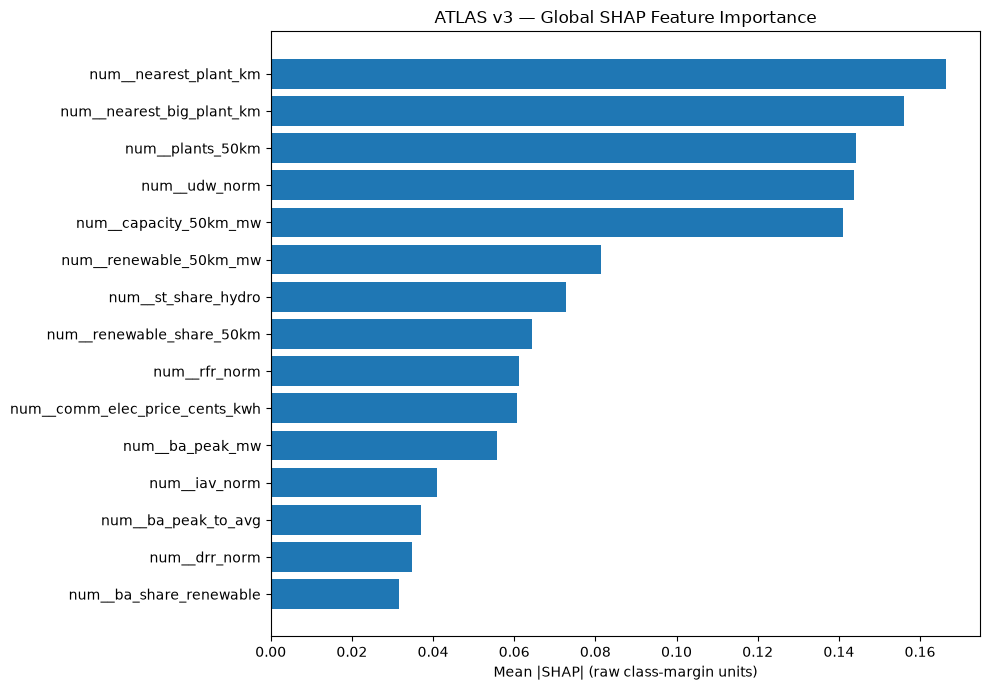

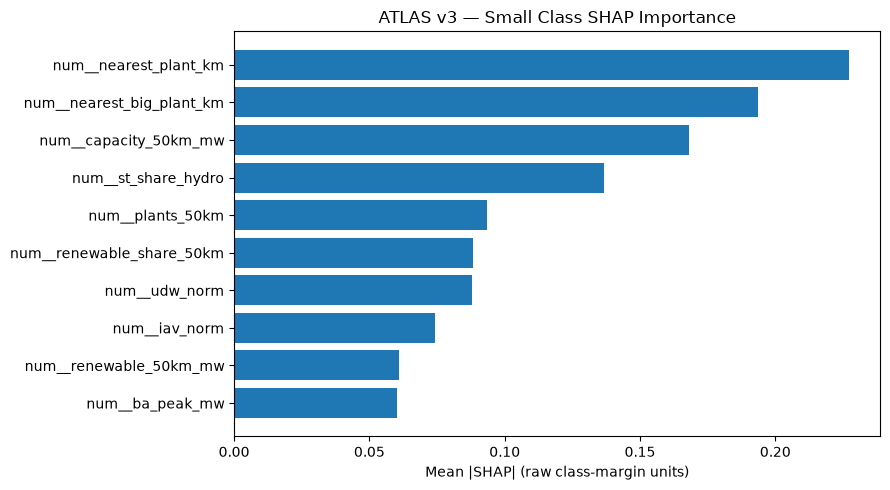

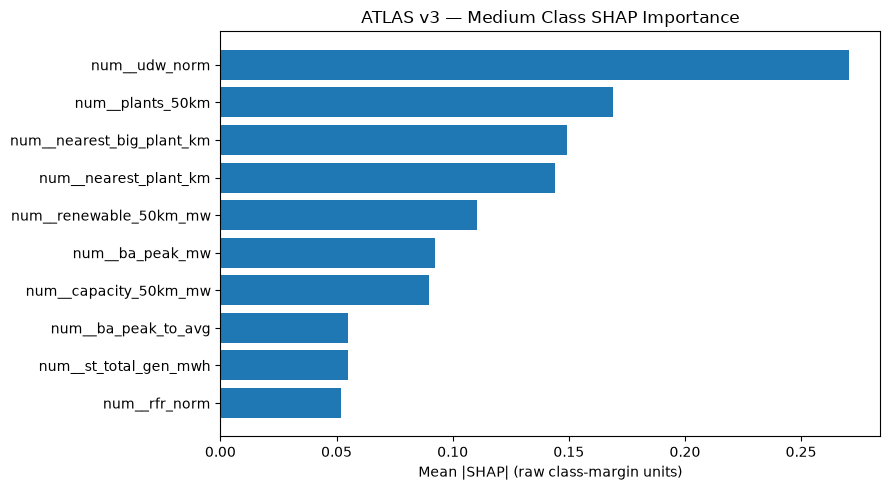

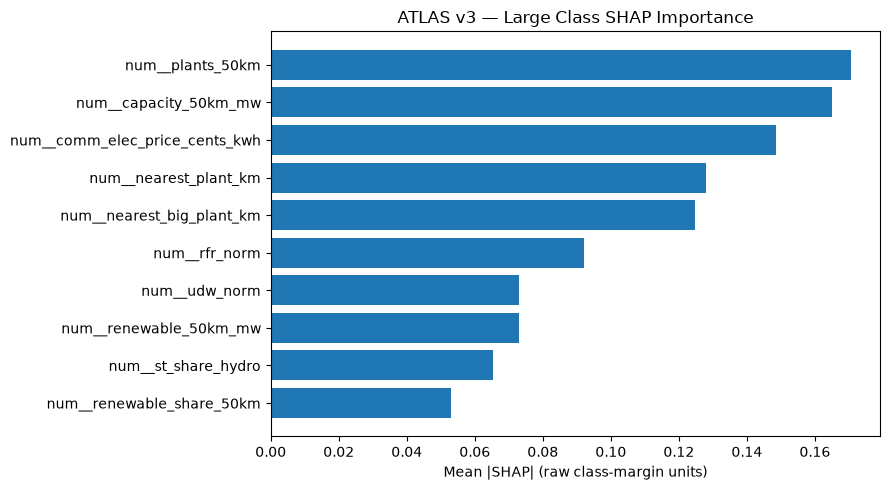


SHAP importance analysis complete.
No held-out test data accessed.


In [79]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Mean absolute SHAP magnitude across development samples.
mean_abs_shap = np.abs(shap_array).mean(axis=0)

assert mean_abs_shap.shape == (
    len(shap_feature_names), 3
)

v3_shap_importance = pd.DataFrame({
    "feature": shap_feature_names,
    "Small": mean_abs_shap[:, 0],
    "Medium": mean_abs_shap[:, 1],
    "Large": mean_abs_shap[:, 2]
})

# Equal weighting across the three class outputs.
v3_shap_importance["global_mean_abs"] = (
    v3_shap_importance[
        ["Small", "Medium", "Large"]
    ].mean(axis=1)
)

v3_shap_importance = (
    v3_shap_importance
    .sort_values("global_mean_abs", ascending=False)
    .reset_index(drop=True)
)

print("ATLAS V3 GLOBAL SHAP IMPORTANCE")
print("-" * 55)

display(v3_shap_importance.head(20).round(4))

# Global top-15 plot.
top_features = (
    v3_shap_importance.head(15)
    .sort_values("global_mean_abs")
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["feature"],
    top_features["global_mean_abs"]
)

plt.xlabel("Mean |SHAP| (raw class-margin units)")
plt.title("ATLAS v3 — Global SHAP Feature Importance")
plt.tight_layout()
plt.show()

# Class-specific top-10 features.
for class_name in CLASS_NAMES:
    top_class = (
        v3_shap_importance
        .sort_values(class_name, ascending=False)
        .head(10)
        .sort_values(class_name)
    )

    plt.figure(figsize=(9, 5))
    plt.barh(
        top_class["feature"],
        top_class[class_name]
    )

    plt.xlabel("Mean |SHAP| (raw class-margin units)")
    plt.title(
        f"ATLAS v3 — {class_name} Class SHAP Importance"
    )
    plt.tight_layout()
    plt.show()

print("\nSHAP importance analysis complete.")
print("No held-out test data accessed.")


# EIA vs WRI SHAP contributions 

In [80]:

import numpy as np
import pandas as pd

# Map transformed feature names to their source family.
eia_set = set(EIA_FEATURES)
wri_set = set(WRI_FEATURES)

def identify_feature_family(transformed_name):
    name = transformed_name.removeprefix("num__")

    if name in eia_set:
        return "EIA"
    if name in wri_set:
        return "WRI"

    # Missing-value indicators from preprocessing.
    for original in eia_set:
        if name == f"missingindicator_{original}":
            return "EIA"

    for original in wri_set:
        if name == f"missingindicator_{original}":
            return "WRI"

    return "Unmapped"

v3_shap_family = v3_shap_importance.copy()

v3_shap_family["family"] = (
    v3_shap_family["feature"]
    .apply(identify_feature_family)
)

print("FEATURE FAMILY MAPPING")
print("-" * 50)
print(v3_shap_family["family"].value_counts())

unmapped = v3_shap_family.loc[
    v3_shap_family["family"] == "Unmapped",
    "feature"
].tolist()

assert not unmapped, f"Unmapped features: {unmapped}"

family_summary = (
    v3_shap_family
    .groupby("family")[
        ["Small", "Medium", "Large", "global_mean_abs"]
    ]
    .sum()
)

family_summary["global_share"] = (
    family_summary["global_mean_abs"]
    / family_summary["global_mean_abs"].sum()
)

print("\nEIA VS WRI SHAP CONTRIBUTIONS")
display(family_summary.round(4))

print("\nTOP WRI FEATURES")
display(
    v3_shap_family.loc[
        v3_shap_family["family"] == "WRI",
        ["feature", "Small", "Medium", "Large", "global_mean_abs"]
    ]
    .sort_values("global_mean_abs", ascending=False)
    .round(4)
)

print("\nNo models trained.")
print("No held-out data accessed.")


FEATURE FAMILY MAPPING
--------------------------------------------------
family
EIA    32
WRI    12
Name: count, dtype: int64

EIA VS WRI SHAP CONTRIBUTIONS


,Small,Medium,Large,global_mean_abs,global_share
family,,,,,
EIA,1.5796,1.2394,1.2041,1.3410,0.763
WRI,0.4080,0.5274,0.3139,0.4164,0.237



TOP WRI FEATURES


,feature,Small,Medium,Large,global_mean_abs
3,num__udw_norm,0.0878,0.2705,0.0731,0.1438
8,num__rfr_norm,0.0392,0.0520,0.0921,0.0611
11,num__iav_norm,0.0741,0.0292,0.0196,0.0410
13,num__drr_norm,0.0536,0.0119,0.0387,0.0347
16,num__sev_norm,0.0346,0.0375,0.0159,0.0294
17,num__cep_norm,0.0215,0.0282,0.0325,0.0274
20,num__bws_norm,0.0388,0.0292,0.0091,0.0257
21,num__bwd_norm,0.0179,0.0312,0.0274,0.0255
31,num__cfr_norm,0.0276,0.0171,0.0019,0.0155
36,num__missingindicator_gtd_norm,0.0018,0.0182,0.0021,0.0073



No models trained.
No held-out data accessed.


# EIA only XGBoost ablation

In [81]:

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import f1_score, balanced_accuracy_score, recall_score
import numpy as np
import pandas as pd

EIA_ONLY_FEATURES = list(EIA_FEATURES)

assert len(EIA_ONLY_FEATURES) == 32
assert set(EIA_ONLY_FEATURES).issubset(V3_FEATURES)

ablation_results = []

cv_protocols = {
    "spatial": v3_splits,
    "state": state_splits
}

for protocol_name, splits in cv_protocols.items():
    print(f"\nEIA-only XGBoost — {protocol_name} CV")

    for fold, (tr, va) in enumerate(splits, start=1):
        X_tr = v3_dev.iloc[tr][EIA_ONLY_FEATURES]
        X_va = v3_dev.iloc[va][EIA_ONLY_FEATURES]

        y_tr = y_v3.iloc[tr]
        y_va = y_v3.iloc[va]

        model = Pipeline([
            ("preprocess", make_preprocessor(EIA_ONLY_FEATURES)),
            ("classifier", clone(
                model_candidates["WeightedXGBoost"]
            ))
        ])

        sample_weights = compute_sample_weight(
            class_weight="balanced",
            y=y_tr
        )

        model.fit(
            X_tr,
            y_tr,
            classifier__sample_weight=sample_weights
        )

        predictions = model.predict(X_va)

        recalls = recall_score(
            y_va,
            predictions,
            labels=[0, 1, 2],
            average=None,
            zero_division=0
        )

        ablation_results.append({
            "protocol": protocol_name,
            "fold": fold,
            "macro_f1": f1_score(
                y_va,
                predictions,
                labels=[0, 1, 2],
                average="macro",
                zero_division=0
            ),
            "balanced_accuracy": balanced_accuracy_score(
                y_va,
                predictions
            ),
            "small_recall": recalls[0],
            "medium_recall": recalls[1],
            "large_recall": recalls[2]
        })

        print(
            f"  Fold {fold}: "
            f"macro-F1={ablation_results[-1]['macro_f1']:.4f}"
        )

v3_eia_ablation = pd.DataFrame(ablation_results)

# Compare against the already computed full-feature XGBoost results.
comparison_rows = []

for protocol, full_results in [
    ("spatial", v3_cv_results),
    ("state", v3_state_results)
]:
    full = (
        full_results.loc[
            full_results["model"] == "WeightedXGBoost"
        ]
        .set_index("fold")
    )

    eia = (
        v3_eia_ablation.loc[
            v3_eia_ablation["protocol"] == protocol
        ]
        .set_index("fold")
    )

    for fold in sorted(full.index):
        comparison_rows.append({
            "protocol": protocol,
            "fold": fold,
            "eia_only_macro_f1": eia.loc[fold, "macro_f1"],
            "eia_wri_macro_f1": full.loc[fold, "macro_f1"],
            "wri_delta": (
                full.loc[fold, "macro_f1"]
                - eia.loc[fold, "macro_f1"]
            )
        })

v3_wri_ablation_comparison = pd.DataFrame(comparison_rows)

print("\nWRI INCREMENTAL VALUE — MACRO-F1")
print("-" * 55)

display(
    v3_wri_ablation_comparison.groupby("protocol")[
        ["eia_only_macro_f1", "eia_wri_macro_f1", "wri_delta"]
    ]
    .agg(["mean", "std"])
    .round(4)
)

print("\nFold-level differences:")
display(v3_wri_ablation_comparison.round(4))

print("\nHeld-out test data remains untouched.")



EIA-only XGBoost — spatial CV
  Fold 1: macro-F1=0.4683
  Fold 2: macro-F1=0.4620
  Fold 3: macro-F1=0.4055
  Fold 4: macro-F1=0.4484
  Fold 5: macro-F1=0.4734

EIA-only XGBoost — state CV
  Fold 1: macro-F1=0.2249
  Fold 2: macro-F1=0.3723
  Fold 3: macro-F1=0.3201
  Fold 4: macro-F1=0.2208
  Fold 5: macro-F1=0.2439

WRI INCREMENTAL VALUE — MACRO-F1
-------------------------------------------------------


eia_only_macro_f1         eia_wri_macro_f1         wri_delta        
                      mean     std             mean     std      mean     std
protocol                                                                     
spatial             0.4515  0.0274           0.4454  0.0293   -0.0061  0.0193
state               0.2764  0.0669           0.2979  0.0384    0.0215  0.0484


Fold-level differences:


,protocol,fold,eia_only_macro_f1,eia_wri_macro_f1,wri_delta
0,spatial,1,0.4683,0.4628,-0.0055
1,spatial,2,0.4620,0.4785,0.0165
2,spatial,3,0.4055,0.4128,0.0074
3,spatial,4,0.4484,0.4161,-0.0323
4,spatial,5,0.4734,0.4569,-0.0166
5,state,1,0.2249,0.2957,0.0708
6,state,2,0.3723,0.3451,-0.0273
7,state,3,0.3201,0.3125,-0.0076
8,state,4,0.2208,0.2972,0.0764
9,state,5,0.2439,0.2391,-0.0048



Held-out test data remains untouched.


# save WRI ablation and SHAP finding

In [82]:

from pathlib import Path
from datetime import datetime, timezone
import json

explain_dir = v3_dir / "explainability"
explain_dir.mkdir(parents=True, exist_ok=True)

artifact_paths = {
    "shap_importance": explain_dir / "shap_feature_importance.csv",
    "shap_families": explain_dir / "shap_feature_family_summary.csv",
    "wri_ablation": explain_dir / "wri_ablation_fold_results.csv",
    "wri_comparison": explain_dir / "wri_ablation_comparison.csv",
    "findings": explain_dir / "research_findings.json"
}

existing = [
    str(path)
    for path in artifact_paths.values()
    if path.exists()
]

assert not existing, f"Refusing to overwrite: {existing}"

v3_shap_family.to_csv(
    artifact_paths["shap_importance"],
    index=False
)

family_summary.to_csv(
    artifact_paths["shap_families"]
)

v3_eia_ablation.to_csv(
    artifact_paths["wri_ablation"],
    index=False
)

v3_wri_ablation_comparison.to_csv(
    artifact_paths["wri_comparison"],
    index=False
)

research_findings = {
    "version": "atlas_wri_v3",
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "model": "WeightedXGBoost",
    "explainability": {
        "method": "SHAP TreeExplainer",
        "samples": SHAP_SAMPLE_N,
        "output_space": "raw_class_margins",
        "maximum_additivity_error": max_additivity_error,
        "eia_attribution_share": float(
            family_summary.loc["EIA", "global_share"]
        ),
        "wri_attribution_share": float(
            family_summary.loc["WRI", "global_share"]
        ),
        "top_wri_feature": "udw_norm"
    },
    "wri_ablation": {
        "spatial_cv_macro_f1_delta": float(
            v3_wri_ablation_comparison.query(
                "protocol == 'spatial'"
            )["wri_delta"].mean()
        ),
        "state_cv_macro_f1_delta": float(
            v3_wri_ablation_comparison.query(
                "protocol == 'state'"
            )["wri_delta"].mean()
        ),
        "interpretation": (
            "WRI does not consistently improve spatial CV. "
            "State CV shows a positive average improvement, "
            "but only two of five folds improve. "
            "Evidence of geographic robustness gains "
            "is preliminary."
        )
    },
    "limitations": [
        "SHAP attribution is not causal evidence.",
        "SHAP attribution share is not predictive gain.",
        "Correlated features may share attribution.",
        "State folds have uneven geographic composition.",
        "No held-out test evaluation has been performed."
    ]
}

with open(artifact_paths["findings"], "w") as f:
    json.dump(research_findings, f, indent=2)

print("ATLAS V3 RESEARCH ARTIFACTS SAVED")
print("-" * 55)

for name, path in artifact_paths.items():
    print(name, "->", path)

print("\nWRI ablation recorded.")
print("SHAP attribution recorded.")
print("Held-out test remains untouched.")


ATLAS V3 RESEARCH ARTIFACTS SAVED
-------------------------------------------------------
shap_importance -> outputs/tabular_baselines/atlas_wri_v3/explainability/shap_feature_importance.csv
shap_families -> outputs/tabular_baselines/atlas_wri_v3/explainability/shap_feature_family_summary.csv
wri_ablation -> outputs/tabular_baselines/atlas_wri_v3/explainability/wri_ablation_fold_results.csv
wri_comparison -> outputs/tabular_baselines/atlas_wri_v3/explainability/wri_ablation_comparison.csv
findings -> outputs/tabular_baselines/atlas_wri_v3/explainability/research_findings.json

WRI ablation recorded.
SHAP attribution recorded.
Held-out test remains untouched.


## 13 — Final held-out evaluation

ATLAS V3 — FINAL HELD-OUT EVALUATION
-------------------------------------------------------
Samples: 161
Macro-F1: 0.4298
Balanced accuracy: 0.5137
Accuracy: 0.5093

Classification report:
              precision    recall  f1-score   support

       Small       0.21      0.64      0.32        11
      Medium       0.31      0.33      0.32        45
       Large       0.76      0.57      0.65       105

    accuracy                           0.51       161
   macro avg       0.43      0.51      0.43       161
weighted avg       0.60      0.51      0.54       161



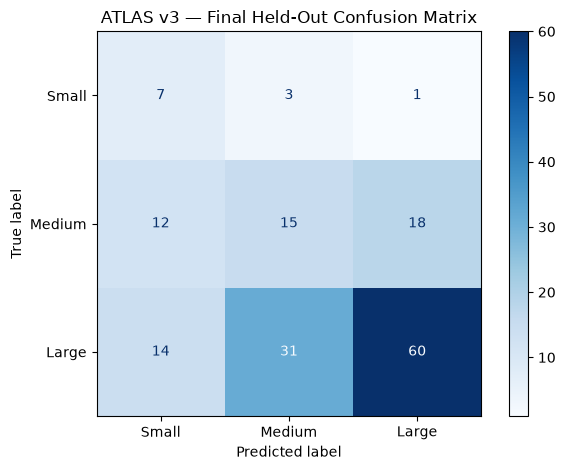


Final evaluation artifacts saved:
outputs/tabular_baselines/atlas_wri_v3/final_evaluation/held_out_metrics.json
outputs/tabular_baselines/atlas_wri_v3/final_evaluation/held_out_predictions.csv


In [83]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load the frozen model and split manifest.
frozen_model = joblib.load(model_path)
manifest = pd.read_csv(manifest_path, dtype={"id": str})

# Recover held-out rows by ID, not notebook row position.
test_ids = set(
    manifest.loc[
        manifest["split"] == "held_out", "id"
    ]
)

dev_ids = set(
    manifest.loc[
        manifest["split"] == "development", "id"
    ]
)

df_ids = df["id"].astype(str)

assert len(test_ids) == 161
assert len(dev_ids) == 986
assert test_ids.isdisjoint(dev_ids)
assert df_ids.is_unique
assert set(df_ids) == test_ids | dev_ids

test_mask = df_ids.isin(test_ids)
test_df = df.loc[test_mask].copy()

assert len(test_df) == 161
assert list(frozen_model.feature_names_in_) == list(V3_FEATURES)

# Check spatial-group separation.
group_lookup = dict(
    zip(manifest["id"], manifest["spatial_group"])
)

test_groups = {
    group_lookup[i] for i in test_ids
}
dev_groups = {
    group_lookup[i] for i in dev_ids
}

assert test_groups.isdisjoint(dev_groups)

# Evaluate exactly the frozen model.
X_test = test_df[V3_FEATURES]
y_test = test_df["size_class"]

y_pred = frozen_model.predict(X_test)

metrics = {
    "model": V3_SELECTED_MODEL_NAME,
    "test_samples": int(len(y_test)),
    "macro_f1": float(
        f1_score(y_test, y_pred, average="macro")
    ),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_test, y_pred)
    ),
    "accuracy": float(
        accuracy_score(y_test, y_pred)
    ),
    "classification_report": classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    ),
    "confusion_matrix": confusion_matrix(
        y_test, y_pred, labels=[0, 1, 2]
    ).tolist()
}

print("ATLAS V3 — FINAL HELD-OUT EVALUATION")
print("-" * 55)

print(f"Samples: {len(y_test)}")
print(f"Macro-F1: {metrics['macro_f1']:.4f}")
print(
    f"Balanced accuracy: "
    f"{metrics['balanced_accuracy']:.4f}"
)
print(f"Accuracy: {metrics['accuracy']:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    display_labels=CLASS_NAMES,
    cmap="Blues"
)

plt.title("ATLAS v3 — Final Held-Out Confusion Matrix")
plt.tight_layout()
plt.show()

# Save final evaluation artifacts.
evaluation_dir = v3_dir / "final_evaluation"
evaluation_dir.mkdir(parents=True, exist_ok=True)

metrics_path = evaluation_dir / "held_out_metrics.json"
predictions_path = evaluation_dir / "held_out_predictions.csv"

assert not metrics_path.exists()
assert not predictions_path.exists()

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=2)

pd.DataFrame({
    "id": test_df["id"].astype(str).to_numpy(),
    "actual": y_test.to_numpy(),
    "predicted": y_pred
}).to_csv(predictions_path, index=False)

print("\nFinal evaluation artifacts saved:")
print(metrics_path)
print(predictions_path)


## Appendix — Historical Random Forest workflow (NON-EXECUTABLE)

The following cells were present in the uploaded notebook after the active WRI v2 workflow. They are retained **verbatim as reference**, but former code cells are rendered as Markdown code blocks so that **Run All cannot train an older model, inspect the test partition, or overwrite the WRI v2 artifacts**. These historical cells are not needed for the active workflow. The original notebook should be retained separately for audit/history.

**Historical cell 22 (archived Python; not executed):**

```python
import json

notebook_path = "ATLAS_tabular_baselines.ipynb"

with open(notebook_path, encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))

    if (
        "Run baseline experiments" in source
        or "baseline_rows" in source
        or "trained_models" in source
        or "results_df" in source
    ):
        print(f"\n{'=' * 20} CELL {i} {'=' * 20}")
        print(source[:7000])
```

**Historical cell 46 (Markdown):**

## 9 — Compare validation results
The chart below is for model selection only. Test results remain untouched.

**Historical cell 47 (archived Python; not executed):**

```python
plot_df = results_df.sort_values("val_macro_f1")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot_df["experiment"], plot_df["val_macro_f1"])
ax.set(xlabel="Validation macro-F1", title="ATLAS tabular baselines")
ax.set_xlim(0, 1)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "validation_macro_f1.png", dpi=160)
plt.show()
best = results_df.loc[results_df["model"] != "Dummy"].iloc[0]
print("Best non-dummy validation model:", best["experiment"])
```

**Historical cell 48 (Markdown):**

## 10 — Final held-out test (run once after selection)

**Stop here until the feature audit and model choice are approved.** Set `RUN_FINAL_TEST = True` only when ready to report final results. This evaluates the already-fitted validation-selected model on test data; it does not refit on train+validation. A future production workflow may refit after evaluation, with careful provenance.

**Historical cell 49 (archived Python; not executed):**

```python
RUN_FINAL_TEST = False
if RUN_FINAL_TEST:
    key = best["experiment"]
    group = best["group"]
    model = trained[key]
    test_metrics, test_pred = evaluate(
        model, df.iloc[test_idx][FEATURE_GROUPS[group]], y.iloc[test_idx]
    )
    print("Selected:", key)
    print(json.dumps(test_metrics, indent=2))
    print(classification_report(y.iloc[test_idx], test_pred,
                                labels=LABELS, target_names=CLASS_NAMES, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y.iloc[test_idx], test_pred, labels=LABELS, display_labels=CLASS_NAMES
    )
    plt.title(f"Test confusion matrix: {key}")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "test_confusion_matrix.png", dpi=160)
    plt.show()
    with open(OUTPUT_DIR / "final_test_metrics.json", "w") as f:
        json.dump({"experiment": key, "metrics": test_metrics}, f, indent=2)
else:
    print("Final test intentionally locked. Review validation findings first.")
```

**Historical cell 50 (Markdown):**

## Model Diagnostics — Per-Class Performance

Compare EIA-only and IM3+EIA Random Forest models
using classification reports and confusion matrices
on the validation set.

The test set remains untouched.

**Historical cell 51 (archived Python; not executed):**

```python
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

models_to_compare = {
    "EIA Random Forest": "EIA__RandomForest",
    "IM3 + EIA Random Forest": "IM3_EIA__RandomForest"
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, key) in zip(axes, models_to_compare.items()):

    model = trained[key]

    group = "EIA" if key.startswith("EIA__") else "IM3_EIA"

    X_val = df.iloc[val_idx][FEATURE_GROUPS[group]]
    y_val = y.iloc[val_idx]

    predictions = model.predict(X_val)

    print(f"\n{'='*55}")
    print(name)
    print(f"{'='*55}")

    print(
        classification_report(
            y_val,
            predictions,
            labels=[0, 1, 2],
            target_names=["Small", "Medium", "Large"],
            digits=3,
            zero_division=0
        )
    )

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        predictions,
        labels=[0, 1, 2],
        display_labels=["Small", "Medium", "Large"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()
```

**Historical cell 52 (Markdown):**

## permutation feature importance

**Historical cell 53 (archived Python; not executed):**

```python
from sklearn.inspection import permutation_importance

model = trained["IM3_EIA__RandomForest"]

X_val = df.iloc[val_idx][FEATURE_GROUPS["IM3_EIA"]]
y_val = y.iloc[val_idx]

result = permutation_importance(
    model,
    X_val,
    y_val,
    scoring="f1_macro",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_val.columns,
    "importance_mean": result.importances_mean,
    "importance_std": result.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance_df.head(15))

# Plot top 15 features
top = importance_df.head(15).sort_values("importance_mean")

plt.figure(figsize=(10, 6))

plt.barh(
    top["feature"],
    top["importance_mean"],
    xerr=top["importance_std"]
)

plt.xlabel("Decrease in validation macro-F1 when shuffled")
plt.title("ATLAS — Permutation Feature Importance")
plt.tight_layout()
plt.show()
```

**Historical cell 54 (Markdown):**

## random forest regularization 

**Historical cell 55 (archived Python; not executed):**

```python
from sklearn.model_selection import StratifiedKFold, GridSearchCV

X_train = df.iloc[train_idx][FEATURE_GROUPS["IM3_EIA"]]
y_train = y.iloc[train_idx]

pipeline = make_model(
    "RandomForest",
    FEATURE_GROUPS["IM3_EIA"]
)

param_grid = {
    "classifier__max_depth": [5, 10, 15],
    "classifier__min_samples_leaf": [3, 5, 10],
    "classifier__max_features": ["sqrt", 0.5]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

grid.fit(X_train, y_train)

print("Best parameters:")
print(grid.best_params_)

print("\nBest cross-validation macro-F1:")
print(round(grid.best_score_, 4))

cv_results = pd.DataFrame(grid.cv_results_)

display(
    cv_results[
        [
            "param_classifier__max_depth",
            "param_classifier__min_samples_leaf",
            "param_classifier__max_features",
            "mean_train_score",
            "mean_test_score",
            "std_test_score"
        ]
    ].sort_values(
        "mean_test_score",
        ascending=False
    ).head(10)
)
```

**Historical cell 56 (Markdown):**

## tuned value evalutation

**Historical cell 57 (archived Python; not executed):**

```python
# Retrieve the best model
tuned_model = grid.best_estimator_

# Use the same validation data as our original baseline
X_val = df.iloc[val_idx][FEATURE_GROUPS["IM3_EIA"]]
y_val = y.iloc[val_idx]

# Evaluate
tuned_metrics, tuned_predictions = evaluate(
    tuned_model,
    X_val,
    y_val
)

print("Tuned Random Forest Validation Results")
print("=" * 45)

print("Macro-F1:", round(tuned_metrics["macro_f1"], 4))
print("Balanced accuracy:", round(tuned_metrics["balanced_accuracy"], 4))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        tuned_predictions,
        labels=[0, 1, 2],
        target_names=["Small", "Medium", "Large"],
        digits=3,
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    tuned_predictions,
    labels=[0, 1, 2],
    display_labels=["Small", "Medium", "Large"],
    cmap="Blues"
)

plt.title("Tuned IM3 + EIA Random Forest")
plt.tight_layout()
plt.show()
```

**Historical cell 58 (Markdown):**

## Inspecting geographic coverage

**Historical cell 59 (archived Python; not executed):**

```python
# Geographic coverage and class distribution
state_distribution = pd.crosstab(
    df["state"],
    df["size_class"]
)

state_distribution.columns = [
    "Small",
    "Medium",
    "Large"
]

state_distribution["Total"] = state_distribution.sum(axis=1)

print("Number of states:", len(state_distribution))

display(
    state_distribution.sort_values(
        "Total",
        ascending=False
    ).head(20)
)

print("\nStates containing all three classes:")
print(
    (
        state_distribution[["Small", "Medium", "Large"]] > 0
    ).all(axis=1).sum()
)
```

**Historical cell 60 (Markdown):**

## Spatial Generalization — State-Grouped Cross-Validation

Evaluate whether the tabular classifier generalizes to
data centers in states excluded from training.

All experiments run locally in WSL.
The original held-out test set remains untouched.

**Historical cell 61 (archived Python; not executed):**

```python
from sklearn.model_selection import StratifiedGroupKFold
import pandas as pd
import numpy as np

# Only use the original training partition
train_df = df.iloc[train_idx].copy()

X_spatial = train_df[FEATURE_GROUPS["IM3_EIA"]]
y_spatial = train_df["size_class"].astype(int)
groups = train_df["state"]

spatial_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

spatial_splits = list(
    spatial_cv.split(X_spatial, y_spatial, groups)
)

fold_summary = []

for fold, (tr_idx, va_idx) in enumerate(spatial_splits, start=1):

    train_states = set(groups.iloc[tr_idx])
    val_states = set(groups.iloc[va_idx])

    assert train_states.isdisjoint(val_states)

    fold_summary.append({
        "Fold": fold,
        "Train facilities": len(tr_idx),
        "Validation facilities": len(va_idx),
        "Validation states": len(val_states),
        "Small": int((y_spatial.iloc[va_idx] == 0).sum()),
        "Medium": int((y_spatial.iloc[va_idx] == 1).sum()),
        "Large": int((y_spatial.iloc[va_idx] == 2).sum())
    })

fold_df = pd.DataFrame(fold_summary)

display(fold_df)
```

**Historical cell 62 (Markdown):**

# spacial cv

**Historical cell 63 (archived Python; not executed):**

```python
from sklearn.base import clone
from sklearn.metrics import f1_score, balanced_accuracy_score, recall_score

# Compare original and tuned Random Forests
spatial_models = {
    "Original RF": trained["IM3_EIA__RandomForest"],
    "Tuned RF": grid.best_estimator_
}

spatial_results = []

for model_name, base_model in spatial_models.items():

    for fold, (tr_idx, va_idx) in enumerate(spatial_splits, start=1):

        # Clone to ensure each fold starts with an unfitted model
        model = clone(base_model)

        X_tr = X_spatial.iloc[tr_idx]
        X_va = X_spatial.iloc[va_idx]

        y_tr = y_spatial.iloc[tr_idx]
        y_va = y_spatial.iloc[va_idx]

        model.fit(X_tr, y_tr)
        predictions = model.predict(X_va)

        spatial_results.append({
            "model": model_name,
            "fold": fold,
            "n_validation": len(va_idx),
            "macro_f1": f1_score(
                y_va, predictions,
                average="macro",
                labels=[0, 1, 2],
                zero_division=0
            ),
            "balanced_accuracy": balanced_accuracy_score(
                y_va, predictions
            ),
            "small_recall": recall_score(
                y_va, predictions,
                labels=[0, 1, 2],
                average=None,
                zero_division=0
            )[0]
        })

spatial_results_df = pd.DataFrame(spatial_results)

display(spatial_results_df)
```

**Historical cell 64 (Markdown):**

# summary 

**Historical cell 65 (archived Python; not executed):**

```python
spatial_summary = (
    spatial_results_df
    .groupby("model")
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        std_macro_f1=("macro_f1", "std"),
        mean_balanced_accuracy=("balanced_accuracy", "mean"),
        mean_small_recall=("small_recall", "mean")
    )
    .round(4)
)

display(spatial_summary)
```

**Historical cell 66 (Markdown):**

## Diagnostioc held out test 

**Historical cell 67 (archived Python; not executed):**

```python
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, balanced_accuracy_score

dummy_results = []

for fold, (tr_idx, va_idx) in enumerate(spatial_splits, start=1):

    dummy = DummyClassifier(strategy="most_frequent")

    dummy.fit(
        X_spatial.iloc[tr_idx],
        y_spatial.iloc[tr_idx]
    )

    predictions = dummy.predict(X_spatial.iloc[va_idx])

    dummy_results.append({
        "fold": fold,
        "macro_f1": f1_score(
            y_spatial.iloc[va_idx],
            predictions,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_spatial.iloc[va_idx],
            predictions
        )
    })

dummy_spatial_df = pd.DataFrame(dummy_results)

display(dummy_spatial_df)

print(
    "\nMean spatial dummy macro-F1:",
    round(dummy_spatial_df["macro_f1"].mean(), 4)
)
```

**Historical cell 68 (Markdown):**

## saving metadata

**Historical cell 69 (archived Python; not executed):**

```python
import json
import joblib

selected_model = grid.best_estimator_

model_path = OUTPUT_DIR / "selected_tabular_model.joblib"
metadata_path = OUTPUT_DIR / "selected_model_metadata.json"

joblib.dump(selected_model, model_path)

metadata = {
    "project": "ACM ATLAS",
    "objective": "Three-class footprint-based data center size classification",
    "selected_model": "IM3 + EIA Random Forest",
    "selection_metric": "validation_macro_f1",
    "validation_macro_f1": 0.5547,
    "cv_macro_f1": float(grid.best_score_),
    "hyperparameters": grid.best_params_,
    "features": FEATURE_GROUPS["IM3_EIA"],
    "random_state": 42,
    "test_evaluated": False
}

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

print("Model saved:", model_path)
print("Metadata saved:", metadata_path)
```

**Historical cell 70 (Markdown):**

## saved model evals

**Historical cell 71 (archived Python; not executed):**

```python
# Reconstruct the original held-out test partition
X_test = df.iloc[test_idx][FEATURE_GROUPS["IM3_EIA"]].copy()
y_test = df.iloc[test_idx]["size_class"].astype(int).copy()

print("Test samples:", len(X_test))
print("\nClass distribution:")
print(y_test.value_counts().sort_index())

print("\nFeatures:", X_test.shape[1])
```

**Historical cell 72 (archived Python; not executed):**

```python
import joblib
import pandas as pd

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    balanced_accuracy_score,
    accuracy_score
)

# Load the frozen model
final_model = joblib.load(
    OUTPUT_DIR / "selected_tabular_model.joblib"
)

# Use the original held-out test set
test_predictions = final_model.predict(X_test)

print("FINAL HELD-OUT TEST RESULTS")
print("-" * 40)

print("Macro-F1:", round(
    f1_score(y_test, test_predictions, average="macro"), 4
))

print("Balanced accuracy:", round(
    balanced_accuracy_score(y_test, test_predictions), 4
))

print("Accuracy:", round(
    accuracy_score(y_test, test_predictions), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1, 2],
    target_names=["Small", "Medium", "Large"],
    zero_division=0
))

print("\nConfusion Matrix:")
display(pd.DataFrame(
    confusion_matrix(y_test, test_predictions, labels=[0, 1, 2]),
    index=["Actual Small", "Actual Medium", "Actual Large"],
    columns=["Predicted Small", "Predicted Medium", "Predicted Large"]
))
```

**Historical cell 73 (Markdown):**

## svaing artifacts

**Historical cell 74 (archived Python; not executed):**

```python
import json
import sklearn
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    f1_score, classification_report, confusion_matrix
)

final_metrics = {
    "model": "IM3_EIA_TunedRandomForest",
    "test_macro_f1": float(f1_score(
        y_test, test_predictions, average="macro"
    )),
    "test_balanced_accuracy": float(
        balanced_accuracy_score(y_test, test_predictions)
    ),
    "test_accuracy": float(
        accuracy_score(y_test, test_predictions)
    ),
    "test_samples": int(len(y_test)),
    "sklearn_version": sklearn.__version__,
    "random_state": 42,
    "evaluation": "final_random_holdout"
}

with open(OUTPUT_DIR / "final_test_metrics.json", "w") as f:
    json.dump(final_metrics, f, indent=2)

pd.DataFrame(
    confusion_matrix(y_test, test_predictions, labels=[0, 1, 2]),
    index=["Small", "Medium", "Large"],
    columns=["Small", "Medium", "Large"]
).to_csv(OUTPUT_DIR / "final_test_confusion_matrix.csv")

pd.DataFrame(
    classification_report(
        y_test, test_predictions,
        labels=[0, 1, 2],
        target_names=["Small", "Medium", "Large"],
        output_dict=True,
        zero_division=0
    )
).T.to_csv(OUTPUT_DIR / "final_test_classification_report.csv")

print("Final evaluation artifacts saved.")
```

**Historical cell 75 (Markdown):**

## 14 — Reproducibility and research notes

**Outputs** in `outputs/tabular_baselines/`:
- `split_manifest.csv` — facility IDs and shared split assignment
- `validation_metrics.csv` — comparable experiment scores
- `*.joblib` — fitted preprocessing+model pipelines
- `validation_macro_f1.png` — validation comparison
- Test metrics and confusion matrix only after explicit unlock

**Before the mentor meeting:**
1. Confirm how `type` is assigned and whether it is independent of footprint.
2. Examine whether EIA features have low variance, missingness, or extreme correlations.
3. Compare minority-class recall, not only macro-F1.
4. Evaluate spatial generalization with state-grouped splits as a follow-up experiment.
5. Port the validated logic into `train_tabular.py` for SageMaker.

**Do not commit generated model binaries or output folders unless the repository explicitly requires them.** Keep the combined CSV as the single authoritative input and avoid duplicating upstream notebooks.